# Decoding the Role of Emojis in Bangla Sarcasm and Offensiveness: A Multitask, Emoji-Intent-Aware Approach with a New Sarcastic-Offense Class

**Research Gap Addressed:** In Bangla online comments, emojis often reverse or intensify the literal meaning of the text. Prior work treats sarcasm and offensiveness as separate tasks, ignores emojis, and cannot represent comments that are both sarcastic and offensive (sarcastic offense). No prior work quantifies how much emojis contribute compared with words.

An emoji-aware pipeline that treats emojis as **language-independent intent anchors** for four-way classification of Bangla comments (pure sarcastic, pure offensive, sarcastic offense, neutral). The system combines a **leakage-free emoji intent encoder** (the core novelty), a `BanglaBERT` multitask backbone with **cross-stitch soft-sharing**, **LIME** explainability computed on the model's true (preprocessed) input, and a **full statistical-significance protocol** — bootstrap 95 % CIs, label-permutation tests, one-sided McNemar, paired *t*-tests and Wilcoxon signed-rank tests, χ² task-dependence and across-fold variance.

Results are reported for a **single reference run at seed 42 with 5-fold cross-validation**, evaluated as a **5-fold ensemble** on a **separate TEST sheet** that is never touched before the final report. The file is read as two sheets, `train` and `test`; a single-sheet file falls back to a stratified hold-out carved out *before* any fitting. Every ablation shares the same folds, seed, budget and hyper-parameters, so each reported difference is attributable to the ablated component alone.


**Revision 2** adds: (1) a separate **train** / **test** sheet workflow, with a single-sheet fallback; (2) per-class precision / recall / F1 for all four classes logged every epoch and every fold; (3) the class-stratified LIME test, the incongruent-subset benchmark and the gated-fusion model with its gate analysis, as recommended in the verified research-recommendations document; (4) optional repeated seeds for mean ± SD.

*Author: Mohammod Hamed Hasan*

## Audit-Fix Changelog (this revision)

| # | Issue | Fix |
|---|---|---|
| 1 | Text-dup train/test contamination | `CFG["DEDUP_ON_TEXT"]=True` (was False); verified 0 conflicting-label text dupes on this dataset |
| 2 | Val fold used for both early-stopping & reporting | Inner `INNER_ES_FRAC` monitor split now carved from train; fold-`b` never seen until final report |
| 3 | Shallow training budget | Config: `MAX_EPOCHS`=2 as a ceiling, `PATIENCE`=1, `SCHED_EPOCHS`=12 (LR horizon decoupled from the ceiling). Earlier text said "2→4", which did not match the code; corrected in revision 2 |
| 4 | Sparse HPO | `HPO_MAX_EVALS` 10→20, `HPO_PROXY_SIZE` 1000→1500 |
| 5 | Low-power ablation tests | Added Wilcoxon signed-rank + explicit n=5 power caveat alongside paired t-test |
| 6 | SupCon biased toward sarcasm task | `supcon_loss_mtl` averages sarcasm- and offensive-contrastive losses symmetrically |
| 7 | Fixed 0.5 threshold only | Added OOF-tuned F1-optimal threshold, reported alongside 0.5 baseline (Section 13c) |
| 8 | Aug/robustness-eval emoji clusters overlapped | Clusters split into disjoint `AUG_CLUSTERS` / `EVAL_CLUSTERS`; swap-in test now uses the held-out half |
| 9 | Broken dataset-path candidate list | Fixed path concatenation bug; now finds `/mnt/user-data/uploads/puc-sarcof-v1.xlsx` correctly |
| 10 | Minor | Version upper-bounds pinned; interactive cell gated by `CFG` flag; `explain_encoder` scope documented; bootstrap/permutation RNGs decorrelated across calls |
| 11 | Target was 2 binary heads (sarcasm, offensive); dataset has 4 mutually exclusive classes | Primary **4-way softmax head** over Pure Sarcastic / Pure Offensive / Sarcastic Offense / Neutral; sarcasm & offensive kept as auxiliary heads derived from the same label |
| 12 | Loss over 2 tasks | 4-way class-weighted cross-entropy + 2 auxiliary BCE, combined by 3-task Kendall uncertainty weighting; SupCon on the 4-way label |
| 13 | Metrics/plots/calibration/robustness/LIME/ablations/stats were binary | All rewritten for 4 classes: macro-F1, MCC, one-vs-rest AUC, 4×4 confusion, 4-class temperature scaling, OOF-tuned class weights, LIME on predicted class, McNemar on 4-way correctness; binary views reported as implied by the 4-way prediction |
| 14 | `ImportError`/`AttributeError: Can't get attribute 'EmoMTL_BanglaBERT' on __main__` in the ablation cell | Checkpoints store **state dicts** plus plain-Python encoder state (no pickled module classes); restore rebuilds models from this notebook's definitions. Ablation cell no longer relies on `__main__` hacks or `ref_folds`; shared `ensemble_predict` moved into the CV engine so the cell runs in a fresh session |
| 15 | Stale binary-era checkpoint could be silently reused | Reference checkpoint renamed `ref_run_4cls_seed{seed}.pt`; loader rejects any checkpoint that is not the 4-class format |
| 16 | Chi-square interpretation hard-coded as "strongly dependent, negative" | Interpretation now follows the computed result (on this data φ ≈ +0.03, p ≈ 0.18: effectively independent) |
| 17 | Cell 53 crosstab labels `row_0`/`col_0`; class weights printed as `np.float64` | Named axes; plain floats |
| 18 | Train and test were one file split internally | `SPLIT_MODE="sheets"` reads the `train` and `test` sheets directly; the stratified split is only a fallback for a single-sheet file. Exact text overlaps between sheets are removed from TEST and reported |
| 19 | Per-class metrics not logged | Per-epoch per-class F1 on fold-validation; a per-fold classification report; per-class precision / recall / F1 tables (folds × 4 classes, mean ± std) after CV |
| 20 | Recommendation Part 1 (class-stratified LIME test) | Section 14c: each emoji-bearing test row explained for its TRUE class (cache shared with 14b); paired t-test + Wilcoxon for sarcastic-labelled (H₁: Δ>0) and offensive-labelled (H₁: Δ<0) rows |
| 21 | Recommendation Part 2 (incongruent-subset benchmark) | Section 14d: positive-surface-trigger subset of sarcastic test rows, re-using the Section 13d emoji-drop predictions; McNemar on sarcasm decisions; automatic expansion with positive emojis when the lexicon subset is below `INCONGRUENT_MIN` |
| 22 | Recommendation Part 3 (gated multimodal fusion) | Section 16b: `MultimodalGatedFusion` replaces concatenation; all downstream heads identical; paired fold test and McNemar against concatenation on identical folds; gate analysis with unit tests |
| 23 | Recommendation Part 5 P4 (repeated seeds) | Section 16b: `MULTI_SEEDS` re-draws folds and re-trains the reference model; mean ± SD reported |
| 24 | Recommendation Part 4 corrections | Gate sub-hypothesis tested on ω = 1 − g (g is the text weight); incongruent-subset metric uses recall / McNemar because macro-F1 is degenerate on an all-positive subset; hard-coded statistics removed from markdown; Section 13 text now describes what the code computes |
| 25 | Label mapping | Sarcasm = {Pure Sarcastic, Sarcastic Offense}; Offensive = {Pure Offensive, Sarcastic Offense}, derived from the one-hot columns. The recommendation's "φ = −0.32, label-mapping artifact" is not reproduced by this mapping; all association values are computed from the data at run time |

Everything else (leakage-free intent encoder, hold-out carved before fitting, OOF temperature scaling, LIME on true model input) was already sound and is unchanged.

## Section 0 — Environment, Dependencies & Global Configuration

In [1]:
import torch

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. In Settings > Accelerator, select GPU T4 x1, then restart the session.")

GPU: Tesla T4


In [2]:

# Kaggle Notebook: Install packages for BanglaBERT
# Keep Kaggle's preinstalled NumPy version to reduce conflicts.

%pip install -q \
    "transformers>=4.40,<5.0" \
    "datasets>=2.18,<4.0" \
    "huggingface-hub>=0.23,<1.0" \
    "scikit-learn>=1.3,<2.0" \
    "pandas>=2.0,<3.0" \
    "openpyxl>=3.1,<4.0" \
    "emoji==1.4.2" \
    "scipy" \
    "matplotlib" \
    "seaborn" \
    "tqdm" \
    "lime>=0.2.0.1,<0.3" \
    "hyperopt>=0.2.7,<0.3"

# Install the BanglaBERT normalizer without changing dependencies
%pip install -q --no-deps \
    "git+https://github.com/csebuetnlp/normalizer"


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
pathos 0.3.5 requires dill>=0.4.1, but you have dill 0.3.8 which is incompatible.
pathos 0.3.5 requires multiprocess>=0.70.19, but you have multiprocess 0.70.16 which is incompatible.
s3fs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
tpot 1.1.0 requires dill>=0.3.9, but you have dill 0.3.8 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggi

In [3]:
import os, re, random, copy, warnings, math
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import emoji as emojilib
warnings.filterwarnings("ignore")

# ---- Reproducibility ----------------------------------------------------------
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- Global configuration -----------------------------------------------------
CFG = {
    "QUICK_SMOKE_TEST": False,    # True -> tiny/fast end-to-end sanity run
    "MODEL_NAME":   "csebuetnlp/banglabert",   # Bangla-specific ELECTRA-discriminator (hidden=768, same as XLM-R base)
    "MAX_LEN":      96,           # texts are <=15 words (99th pct 12) -> 96 is ample & ~1.8x faster than 128
    "N_SPLITS":     5,
    "TEST_SIZE":    0.15,         # used ONLY when the file has no separate train/test sheets
    "MAX_EPOCHS":   20,            # ceiling only — early stopping usually ends sooner
    "PATIENCE":     3,
    "SCHED_EPOCHS": 12,           # LR anneals over THIS horizon (decoupled from MAX_EPOCHS)
    "WARMUP_RATIO": 0.1,
    "WEIGHT_DECAY": 0.01,         # CONSISTENT across train / hyperopt / ablation
    "GRAD_CLIP":    1.0,
    "USE_SUPCON":   True,         # supervised-contrastive auxiliary loss
    "SUPCON_W":     0.1,
    "INTENT_MIN_COUNT": 3,        # emoji must appear >=N times (in TRAIN) to get a prop
    "INTENT_SMOOTH_M":  5.0,      # m-estimate smoothing strength toward train base-rate
    "HPO_MAX_EVALS": 20,
    "HPO_PROXY_SIZE": 1500,
    "HPO_PROXY_EPOCHS": 3,

    # ---- data / leakage controls ----------------------------------------------
    "DEDUP_ON_TEXT": True,        # drop text-level dupes with conflicting labels
    "INNER_ES_FRAC": 0.1,         # inner early-stopping monitor carved out of TRAIN
    "TUNE_THRESHOLD": True,

    # ---- statistical-significance controls -------------------------------------
    "ABLATION_SEED": 42,          # reference run + ablations share this seed (paired tests)
    "SKIP_HPO":     False,        # True -> reuse DEFAULT_HP (skips the search, saves time)
    "BOOTSTRAP_N":  5000,
    "PERM_N":       2000,

    # ---- LIME / explainability --------------------------------------------------
    "LIME_SAMPLES": 300,
    "LIME_INFER_BATCH": 64,
    "LIME_AUTOCAST": True,
    "LIME_MAX_EXAMPLES": None,    # None -> ALL emoji-bearing test rows

    # ---- 4-way target (dataset columns, in this order) ---------------------------
    "CLASS_NAMES": ["Pure Sarcastic", "Pure Offensive", "Sarcastic Offense", "Neutral"],
    "CLASS_SHORT": ["PureSarc", "PureOff", "SarcOff", "Neutral"],   # compact log labels
    "RUN_DIR":      "/kaggle/working/runs",   # checkpoints (resume-safe)

    # ---- revision 2: research-recommendation controls -------------------------
    "GATE_HIDDEN":  256,          # hidden width of the gated-fusion gate network (Part 3)
    "RUN_GATED":    True,         # Part 3: train the gated-fusion model on the SAME folds and compare
    "INCONGRUENT_MIN": 10,        # Part 2: lexicon subset smaller than this -> expand with positive emojis
    "MULTI_SEEDS":  [7, 2024],    # Part 5: extra seeds for mean ± SD ([] to skip)
}
# Sensible fallback if HPO is skipped
DEFAULT_HP = {"lr": 2e-5, "batch_size": 16, "dropout": 0.3, "shared_dim": 512, "task_dim": 256}

if CFG["QUICK_SMOKE_TEST"]:
    CFG.update(MAX_EPOCHS=2, PATIENCE=1, SCHED_EPOCHS=2, N_SPLITS=2, HPO_MAX_EVALS=3,
               HPO_PROXY_SIZE=200, HPO_PROXY_EPOCHS=1, BOOTSTRAP_N=500, PERM_N=200,
               LIME_SAMPLES=80, LIME_MAX_EXAMPLES=5, MULTI_SEEDS=[7])

os.makedirs(CFG["RUN_DIR"], exist_ok=True)

# ---- 4-class target helpers ---------------------------------------------------
# The four classes are exactly the four (sarcasm, offensive) joint cells, so the binary
# views are DERIVED from the 4-way label rather than stored separately:
#   Pure Sarcastic = (sarc 1, off 0)   Pure Offensive = (0, 1)
#   Sarcastic Offense = (1, 1)         Neutral = (0, 0)
CLASS_NAMES = CFG["CLASS_NAMES"]
N_CLASSES   = len(CLASS_NAMES)
JOINT2CLS   = {(1, 0): 0, (0, 1): 1, (1, 1): 2, (0, 0): 3}

def to_class(sarc, off):
    """(sarcasm, offensive) binary arrays -> 4-way class indices (np.int64)."""
    return np.array([JOINT2CLS[(int(s), int(o))] for s, o in zip(sarc, off)], dtype=np.int64)

def derived_binary(P):
    """4-way probability matrix [N, 4] -> (P(sarcasm), P(offensive)) implied by it."""
    return P[:, 0] + P[:, 2], P[:, 1] + P[:, 2]

print(f"Device: {DEVICE} | torch {torch.__version__} | emoji {emojilib.__version__}")
print("QUICK_SMOKE_TEST =", CFG["QUICK_SMOKE_TEST"], "| seed =", CFG["ABLATION_SEED"],
      "| folds =", CFG["N_SPLITS"], "| multi-seeds =", CFG["MULTI_SEEDS"])

Device: cuda | torch 2.11.0+cu128 | emoji 1.4.2
QUICK_SMOKE_TEST = False | seed = 42 | folds = 5 | multi-seeds = [7, 2024]


## Section 1 — Dataset Loading, Verified Statistics & Integrity Checks

The Excel file is expected to hold **two sheets, `train` and `test`**. The TRAIN sheet is the learning set (5-fold cross-validation runs inside it); the TEST sheet is the hold-out, used for the reported numbers only. If the file has a single sheet, the notebook says so and falls back to a stratified hold-out (Section 5).

Native columns (`Comment` and the four one-hot class columns) are mapped to the pipeline schema `text` / `label` / `sarcasm` / `offensive`. The `Domain` column is dropped because the target is the four-way label. Exact duplicates are removed within each sheet, and any text that occurs in both sheets is removed from TEST, so that no test sentence was seen during training.

In [4]:
# ---- Load dataset -------------------------------------------------------------
# Expected layout: ONE Excel file with two sheets named `train` and `test` (case-insensitive).
#   * two sheets found  -> SPLIT_MODE = "sheets": TRAIN and TEST are used exactly as given.
#   * one sheet only    -> SPLIT_MODE = "internal": a stratified hold-out is carved out (Section 5).
import os
import glob
import pandas as pd

print("Contents of /kaggle/input:")
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print("  ", os.path.join(root, f))

candidates = glob.glob("/kaggle/input/datasets/shuvraroy1093/copy-of-bangla-offensive-and-sarcasm-dataset/Copy of Bangla Offensive and Sarcasm Dataset.xlsx", recursive=True) + \
             glob.glob("/kaggle/input/**/*.csv", recursive=True)
preferred = [p for p in candidates if "emojysarcofv3" in os.path.basename(p).lower()]
DATA_PATH = (preferred or candidates or [None])[0]

if DATA_PATH is None:
    raise FileNotFoundError(
        "No .xlsx or .csv found under /kaggle/input. In the notebook sidebar, "
        "click '+ Add Input' and make sure the dataset is attached to this notebook session.")
print(f"Using file: {DATA_PATH}")

ONEHOT_COLS = ["Pure Sarcastic", "Pure Offensive", "Sarcastic Offense", "Neutral"]
if "CLASS_NAMES" not in globals():
    CLASS_NAMES = ONEHOT_COLS
assert list(CLASS_NAMES) == ONEHOT_COLS, "CLASS_NAMES must match the dataset's class column order"

# ---- Detect the sheet layout ----------------------------------------------------
IS_EXCEL = DATA_PATH.lower().endswith((".xlsx", ".xls"))
if IS_EXCEL:
    SHEETS = pd.ExcelFile(DATA_PATH).sheet_names
    def _find_sheet(name):
        hits = [s for s in SHEETS if str(s).strip().lower() == name]
        return hits[0] if hits else None
    TRAIN_SHEET, TEST_SHEET = _find_sheet("train"), _find_sheet("test")
else:
    SHEETS, TRAIN_SHEET, TEST_SHEET = [], None, None

if TRAIN_SHEET is not None and TEST_SHEET is not None:
    SPLIT_MODE = "sheets"
    print(f"Sheets in file: {SHEETS}")
    print(f"SPLIT_MODE = 'sheets'  -> TRAIN from '{TRAIN_SHEET}', TEST from '{TEST_SHEET}' "
          f"(separate sets, NO internal split)")
else:
    SPLIT_MODE = "internal"
    print(f"Sheets in file: {SHEETS if SHEETS else '(csv)'}")
    warnings.warn(
        "No separate 'train' and 'test' sheets found -> SPLIT_MODE = 'internal'. A stratified "
        f"{int(CFG['TEST_SIZE']*100)}% hold-out will be carved from the single table in Section 5.")

def _read(sheet=None):
    if IS_EXCEL:
        frame = pd.read_excel(DATA_PATH, sheet_name=(sheet if sheet is not None else 0))
    else:
        frame = pd.read_csv(DATA_PATH)
    frame.columns = frame.columns.str.strip()        # guard against stray spaces in headers
    return frame

def to_schema(frame, name):
    """Map the native one-hot schema -> pipeline schema: text, label, sarcasm, offensive."""
    missing = [c for c in ["Comment"] + ONEHOT_COLS if c not in frame.columns]
    if missing:
        raise KeyError(f"[{name}] dataset is missing required columns: {missing}")
    keep = frame["Comment"].notna() & frame["Comment"].astype(str).str.strip().ne("")
    if (~keep).sum():
        print(f"[{name}] dropped {int((~keep).sum())} rows with an empty Comment")
    frame = frame[keep]
    onehot = frame[ONEHOT_COLS].astype(int)
    n_bad = int((onehot.sum(axis=1) != 1).sum())
    if n_bad:
        raise ValueError(f"[{name}] {n_bad} rows do not have exactly one class column set to 1.")
    out = pd.DataFrame({"text": frame["Comment"].astype(str).values,
                        "label": onehot.values.argmax(axis=1).astype(int)})
    out["sarcasm"]   = out["label"].isin([0, 2]).astype(int)    # derived binary view
    out["offensive"] = out["label"].isin([1, 2]).astype(int)    # derived binary view
    return out.reset_index(drop=True)

if SPLIT_MODE == "sheets":
    RAW_TRAIN = to_schema(_read(TRAIN_SHEET), "train")
    RAW_TEST  = to_schema(_read(TEST_SHEET),  "test")
    print("RAW_TRAIN:", RAW_TRAIN.shape, "| RAW_TEST:", RAW_TEST.shape)
else:
    RAW_TRAIN = to_schema(_read(None), "file")          # single pool; split happens in Section 5
    RAW_TEST  = None
    print("RAW pool:", RAW_TRAIN.shape)
RAW_TRAIN.head()

Contents of /kaggle/input:
   /kaggle/input/datasets/shuvraroy1093/copy-of-bangla-offensive-and-sarcasm-dataset/Copy of Bangla Offensive and Sarcasm Dataset.xlsx
Using file: /kaggle/input/datasets/shuvraroy1093/copy-of-bangla-offensive-and-sarcasm-dataset/Copy of Bangla Offensive and Sarcasm Dataset.xlsx
Sheets in file: ['Train', 'Test']
SPLIT_MODE = 'sheets'  -> TRAIN from 'Train', TEST from 'Test' (separate sets, NO internal split)
RAW_TRAIN: (1495, 4) | RAW_TEST: (495, 4)


,text,label,sarcasm,offensive
0,সর্বকালের সেরা খেলোয়াড় হচ্ছে হেলিকপ্টার মিলন স...,0,1,0
1,"ভবিষ্যদ্বাণী করছি, পরের ম্যাচেও এই টিম একই ভুল...",3,0,0
2,সর্বকালের সেরা হিরো আলম এর মত একজনকেও পাইনি,0,1,0
3,নারী স্বাধীনতা! গাড়ি চালানোটাও ঠিকমত পারে না আ...,1,0,1
4,"Wow, কী honest media, সবাইকে একই গল্প শোনায়। 😂",0,1,0


In [5]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/shuvraroy1093/copy-of-bangla-offensive-and-sarcasm-dataset/Copy of Bangla Offensive and Sarcasm Dataset.xlsx


In [6]:
# ---- Integrity, de-duplication and verified 4-way label distribution ----------------
def dedup_frame(frame, name):
    n_exact = int(frame.duplicated(subset=["text", "label"]).sum())
    f = frame.drop_duplicates(subset=["text", "label"]).reset_index(drop=True)
    n_text = int(f.duplicated(subset=["text"]).sum())          # same text, CONFLICTING labels
    if CFG["DEDUP_ON_TEXT"] and n_text:
        f = f.drop_duplicates(subset=["text"]).reset_index(drop=True)
    print(f"[{name}] raw rows {len(frame)} | exact-duplicate rows removed {n_exact} | "
          f"text-only duplicates {n_text} ({'removed' if CFG['DEDUP_ON_TEXT'] else 'kept'}) "
          f"| working rows {len(f)}")
    return f

if SPLIT_MODE == "sheets":
    tr_ded = dedup_frame(RAW_TRAIN, "train")
    te_ded = dedup_frame(RAW_TEST, "test")
    # LEAKAGE GUARD: a sentence present in both sheets would be scored after being trained on.
    # Overlapping rows are removed from TEST (TRAIN is the learning set and is never edited).
    overlap = set(tr_ded["text"]) & set(te_ded["text"])
    n_rm = int(te_ded["text"].isin(overlap).sum())
    print(f"Exact text overlap train <-> test: {len(overlap)} distinct texts ({n_rm} test rows)")
    if n_rm:
        te_ded = te_ded[~te_ded["text"].isin(overlap)].reset_index(drop=True)
        print(f"  -> removed {n_rm} overlapping rows from TEST")
    df = pd.concat([tr_ded.assign(split="train"), te_ded.assign(split="test")],
                   ignore_index=True)
else:
    df = dedup_frame(RAW_TRAIN, "pool").assign(split="pool")

assert set(df["label"].unique()) <= set(range(N_CLASSES))
assert df[["text", "label"]].isnull().sum().sum() == 0

print("\n=== 4-WAY CLASS DISTRIBUTION (verified from file) ===")
for name, g in df.groupby("split", sort=False):
    counts = g["label"].value_counts().sort_index()
    print(f"-- split = {name}: {len(g)} rows")
    for k in range(N_CLASSES):
        n = int(counts.get(k, 0))
        print(f"  [{k}] {CLASS_NAMES[k]:<18} {n:>5}  ({100*n/max(len(g),1):5.1f}%)")
print(f"\nBinary views (derived from the 4-way label, whole working set): "
      f"Sarcasm=1 {int(df.sarcasm.sum())} | Offensive=1 {int(df.offensive.sum())}")

[train] raw rows 1495 | exact-duplicate rows removed 0 | text-only duplicates 0 (removed) | working rows 1495
[test] raw rows 495 | exact-duplicate rows removed 0 | text-only duplicates 0 (removed) | working rows 495
Exact text overlap train <-> test: 0 distinct texts (0 test rows)

=== 4-WAY CLASS DISTRIBUTION (verified from file) ===
-- split = train: 1495 rows
  [0] Pure Sarcastic       363  ( 24.3%)
  [1] Pure Offensive       363  ( 24.3%)
  [2] Sarcastic Offense    385  ( 25.8%)
  [3] Neutral              384  ( 25.7%)
-- split = test: 495 rows
  [0] Pure Sarcastic       116  ( 23.4%)
  [1] Pure Offensive       122  ( 24.6%)
  [2] Sarcastic Offense    117  ( 23.6%)
  [3] Neutral              140  ( 28.3%)

Binary views (derived from the 4-way label, whole working set): Sarcasm=1 981 | Offensive=1 987


## Section 2 — Emoji Extraction & Corpus Analysis (library-based)

All emoji handling uses the **`emoji` library** (`EMOJI_DATA`), which covers supplemental symbols, variation selectors, regional indicators and ZWJ sequences — the cases the old hand-written regex missed.

In [7]:
from collections import Counter, defaultdict

# ---- Version-robust emoji lookup ---------------------------------------------
# `emoji>=2.10` (this notebook's floor) exposes `EMOJI_DATA` — a dict {char: {...}}.
# Some kernels ship a newer/older build where it's named `UNICODE_EMOJI`, is a
# function `is_emoji()`, or lives under a private path. We resolve ONCE here and
# expose:
#   * EMOJI_SET  — a set of every recognised emoji character (fast membership test)
#   * emoji_name(ch) — English short-name for the fallback token in Section 3
# We also monkey-patch `emojilib.EMOJI_DATA` back onto the module so the many
# downstream cells that read `emojilib.EMOJI_DATA` directly keep working unchanged.

def _resolve_emoji_api():
    # 1) modern (emoji 2.x): dict at emojilib.EMOJI_DATA
    d = getattr(emojilib, "EMOJI_DATA", None)
    if isinstance(d, dict) and d:
        return d, "EMOJI_DATA"
    # 2) older path (emoji <2.x): UNICODE_EMOJI["en"]
    u = getattr(emojilib, "UNICODE_EMOJI", None)
    if isinstance(u, dict):
        d = u.get("en") or next(iter(u.values()), None)
        if isinstance(d, dict) and d:
            # normalise to {char: {"en": ":short_name:"}} shape
            norm = {ch: (v if isinstance(v, dict) else {"en": v}) for ch, v in d.items()}
            return norm, "UNICODE_EMOJI"
    # 3) private module (emoji 3.x kept the same dict, moved the export)
    try:
        from emoji.unicode_codes.data_dict import EMOJI_DATA as _D
        if isinstance(_D, dict) and _D:
            return _D, "unicode_codes.data_dict"
    except Exception:
        pass
    # 4) last-resort: use is_emoji() to enumerate BMP+SMP; slow but correct
    if hasattr(emojilib, "is_emoji"):
        d = {}
        for cp in range(0x1F000, 0x1FB00):        # main emoji planes
            ch = chr(cp)
            try:
                if emojilib.is_emoji(ch):
                    d[ch] = {"en": f":U+{cp:04X}:"}
            except Exception:
                pass
        for cp in range(0x2600, 0x27C0):          # misc symbols/dingbats
            ch = chr(cp)
            try:
                if emojilib.is_emoji(ch):
                    d[ch] = {"en": f":U+{cp:04X}:"}
            except Exception:
                pass
        if d:
            return d, "is_emoji() enumeration"
    raise ImportError(
        f"Unsupported `emoji` package layout (version={getattr(emojilib,'__version__','?')}). "
        f"Fix: !pip install -U --force-reinstall 'emoji>=2.10,<3'  and restart the kernel."
    )

_EMOJI_DATA, _src = _resolve_emoji_api()
EMOJI_SET = set(_EMOJI_DATA.keys())

# Monkey-patch so every downstream cell that reads `emojilib.EMOJI_DATA` keeps working
# without edits (LIME, ambiguity score, robustness, error analysis, etc.).
emojilib.EMOJI_DATA = _EMOJI_DATA

def emoji_name(ch):
    """Return an English short-name for `ch` (used by expand_emojis' fallback token)."""
    rec = _EMOJI_DATA.get(ch, {})
    if isinstance(rec, dict):
        return rec.get("en") or rec.get("alias") or ":unknown:"
    return str(rec)

print(f"emoji API resolved via: {_src}  |  {len(EMOJI_SET)} characters recognised  "
      f"|  emoji lib v{getattr(emojilib,'__version__','?')}")

# ---- Corpus analysis (uses the resolved EMOJI_SET) ---------------------------
def extract_emojis(text):
    """Return the list of emoji characters in text (library-backed, complete)."""
    return [c for c in str(text) if c in EMOJI_SET]

df["emojis"]      = df["text"].apply(extract_emojis)
df["emoji_count"] = df["emojis"].apply(len)

emoji_freq = Counter(e for lst in df["emojis"] for e in lst)
print(f"Sentences with >=1 emoji : {(df.emoji_count>0).sum()} / {len(df)} "
      f"({(df.emoji_count>0).mean()*100:.1f}%)")
print(f"Mean emojis / sentence   : {df.emoji_count.mean():.2f}")
print(f"Distinct emojis in corpus: {len(emoji_freq)}")
print("\nTop-15 emojis:")
for e, n in emoji_freq.most_common(15):
    print(f"  {e}  {n:>4}  {emoji_name(e)}")

emoji API resolved via: UNICODE_EMOJI  |  3521 characters recognised  |  emoji lib v1.4.2
Sentences with >=1 emoji : 1367 / 1990 (68.7%)
Mean emojis / sentence   : 1.12
Distinct emojis in corpus: 197

Top-15 emojis:
  😂   253  :face_with_tears_of_joy:
  🤡   231  :clown_face:
  🤮   148  :face_vomiting:
  💩   136  :pile_of_poo:
  😏   118  :smirking_face:
  🤣   101  :rolling_on_the_floor_laughing:
  🤬    69  :face_with_symbols_on_mouth:
  👎    53  :thumbs_down:
  😡    53  :pouting_face:
  🙄    46  :face_with_rolling_eyes:
  🖕    41  :middle_finger:
  😤    33  :face_with_steam_from_nose:
  👏    27  :clapping_hands:
  🌟    26  :glowing_star:
  💸    25  :money_with_wings:


## Section 3 — Emoji → Bangla Phrase Expansion (full corpus coverage)

convert emojis to Bangla phrases to surface their hidden emotional/pragmatic context. Here:

* a **curated Bangla dictionary** handles the most frequent ~70 emojis (≈84 % of all emoji occurrences) with sarcasm/offence-aware wording, and
* every remaining emoji falls back to a **distinct** `[ইমোজি: <name>]` token derived from the `emoji` library's short-name — so no two emojis collapse together.

This yields **100 % coverage with full semantic distinction**.

In [8]:
# ---- Curated Bangla phrases for high-frequency, intent-bearing emojis ----------

# ---- BanglaBERT text normalizer (REQUIRED before tokenizing) -------------------
# BanglaBERT was pretrained on text passed through csebuetnlp's normalizer; applying
# the same normalization at fine-tune/inference time is required for best results.
# Guarded so the notebook still runs (identity normalize + warning) if the package
# is missing (e.g. offline). Normalization is applied LAST, on the final Bangla
# string, right before tokenization — never on raw emoji characters.
try:
    from normalizer import normalize as _bnorm
    _NORMALIZER_OK = True
except Exception as _e:
    warnings.warn(f"csebuetnlp normalizer unavailable ({_e}); using identity normalize. "
                  f"Install: pip install git+https://github.com/csebuetnlp/normalizer")
    def _bnorm(t):
        return t
    _NORMALIZER_OK = False

def bnorm(text):
    """Apply the BanglaBERT normalizer with a safe fallback to identity."""
    try:
        return _bnorm(str(text))
    except Exception:
        return str(text)
CURATED_BANGLA = {
    "🤣":"[ব্যঙ্গাত্মক হাসি]", "😂":"[কান্নাময় হাসি]", "😆":"[উচ্চস্বরে হাসি]",
    "😁":"[উজ্জ্বল হাসি]", "😃":"[প্রশস্ত হাসি]", "🙂":"[মৃদু হাসি]", "😊":"[সন্তুষ্ট হাসি]",
    "😏":"[বাঁকা হাসি]", "😎":"[আত্মবিশ্বাসী]", "😉":"[চোখ টিপ]", "🤡":"[সং]",
    "🐸":"[ব্যঙ্গ প্রতীক]", "🙃":"[উল্টো হাসি]",
    "😡":"[রাগান্বিত]", "😠":"[ক্ষুব্ধ]", "🤬":"[গালিগালাজ]", "😤":"[ক্রুদ্ধ শ্বাস]",
    "😒":"[অসন্তুষ্ট]", "😑":"[বিরক্ত]", "😐":"[নির্বিকার]", "🙄":"[চোখ ঘোরানো]",
    "🤮":"[বিতৃষ্ণা]", "🤢":"[বমি ভাব]", "💀":"[মৃত্যু প্রতীক]", "👎":"[অপছন্দ]",
    "🖕":"[অশ্লীল অঙ্গভঙ্গি]",
    "😭":"[কাঁদছি]", "😢":"[দুঃখী]", "😔":"[বিষণ্ণ]", "😞":"[হতাশ]", "😟":"[উদ্বিগ্ন]",
    "😫":"[ক্লান্ত]", "😩":"[বিরক্ত ক্লান্ত]", "😣":"[কষ্ট]", "😓":"[ঘর্মাক্ত]",
    "😪":"[ঘুমঘুম]", "😴":"[ঘুমন্ত]", "🥲":"[অশ্রুসিক্ত হাসি]", "💔":"[ভাঙা হৃদয়]",
    "😍":"[মুগ্ধ]", "🥰":"[ভালোবাসাময়]", "😘":"[চুম্বন]", "❤":"[ভালোবাসা]",
    "🧡":"[কমলা হৃদয়]", "💛":"[হলুদ হৃদয়]", "💙":"[নীল হৃদয়]", "💚":"[সবুজ হৃদয়]",
    "💯":"[একশো ভাগ]", "🔥":"[আগুন]", "👏":"[তালি]", "👍":"[পছন্দ]", "🙏":"[প্রার্থনা]",
    "😳":"[লজ্জিত]", "😮":"[বিস্মিত]", "😯":"[অবাক]", "😵":"[হতবিহ্বল]", "🥴":"[বিভ্রান্ত]",
    "🤔":"[ভাবছি]", "🤦":"[হতাশ ভঙ্গি]", "🤷":"[কাঁধ ঝাঁকানো]", "😶":"[নিরুত্তর]",
    "👀":"[নজর]", "🎭":"[নাটকীয়তা]",
}

def expand_emojis(text):
    """Replace every emoji with a Bangla phrase; tail emojis get a DISTINCT named token."""
    out = []
    for ch in str(text):
        if ch in CURATED_BANGLA:
            out.append(f" {CURATED_BANGLA[ch]} ")
        elif ch in emojilib.EMOJI_DATA:
            name = emojilib.EMOJI_DATA[ch]["en"].strip(":").replace("_", " ")
            out.append(f" [ইমোজি: {name}] ")
        else:
            out.append(ch)
    return re.sub(r"\s+", " ", "".join(out)).strip()

def strip_emojis(text):
    """Delete every emoji character entirely (for the TRUE no-emoji ablation)."""
    return "".join(ch for ch in str(text) if ch not in emojilib.EMOJI_DATA)

def clean_text(text):
    text = re.sub(r"http\S+|www\.\S+", "", str(text))
    text = re.sub(r"[@#]\w+", "", text)
    return re.sub(r"\s+", " ", text).strip()

def preprocess(text):                       # raw -> model-input (emoji-EXPANDED) text
    return bnorm(expand_emojis(clean_text(text)))       # normalize LAST, before tokenizing

def preprocess_noemoji(text):               # raw -> model-input with emojis REMOVED (ablation A0)
    return bnorm(clean_text(strip_emojis(text)))        # normalize LAST, before tokenizing

covered = sum(emoji_freq[e] for e in CURATED_BANGLA if e in emoji_freq)
print(f"Curated map: {len(CURATED_BANGLA)} emojis -> covers "
      f"{covered}/{sum(emoji_freq.values())} = {covered/sum(emoji_freq.values())*100:.1f}% of occurrences")
print("Tail emojis still get a DISTINCT token (no generic collapse).")
print(f"BanglaBERT normalizer active: {_NORMALIZER_OK}")
for s in df["text"].iloc[[1, 3]]:
    print(f"\n  raw       : {s}\n  expanded  : {preprocess(s)}\n  no-emoji  : {preprocess_noemoji(s)}")

Curated map: 63 emojis -> covers 1389/2233 = 62.2% of occurrences
Tail emojis still get a DISTINCT token (no generic collapse).
BanglaBERT normalizer active: False

  raw       : ভবিষ্যদ্বাণী করছি, পরের ম্যাচেও এই টিম একই ভুল করবে, ট্র্যাক রেকর্ড তো তাই বলে।
  expanded  : ভবিষ্যদ্বাণী করছি, পরের ম্যাচেও এই টিম একই ভুল করবে, ট্র্যাক রেকর্ড তো তাই বলে।
  no-emoji  : ভবিষ্যদ্বাণী করছি, পরের ম্যাচেও এই টিম একই ভুল করবে, ট্র্যাক রেকর্ড তো তাই বলে।

  raw       : নারী স্বাধীনতা! গাড়ি চালানোটাও ঠিকমত পারে না আবার বড় বড় কথা।
  expanded  : নারী স্বাধীনতা! গাড়ি চালানোটাও ঠিকমত পারে না আবার বড় বড় কথা।
  no-emoji  : নারী স্বাধীনতা! গাড়ি চালানোটাও ঠিকমত পারে না আবার বড় বড় কথা।


## Section 4 — Leakage-Free Emoji *Intent* Encoder (core novelty)

**This is the central contribution**

Each emoji gets a **sarcasm propensity** and **offensive propensity** estimated from the corpus — *task-specific intent*, not generic emotion.

Here the statistics live in an **`EmojiIntentEncoder`** with a strict **`fit` / `transform`** contract:

* `fit(texts, sarc, off)` is called **only on a training split** (each CV fold's train part, or the full train/CV pool for the final hold-out model);
* low-frequency emojis are smoothed toward the **training base-rate** via an **m-estimate** `(hits + m·base)/(n + m)` instead of an arbitrary `0.5`;
* `transform(texts)` applies those frozen training statistics to *any* split.

The 10-d sentence vector `[max_sarc, mean_sarc, max_off, mean_off, emoji_count, sarc_anchors, off_anchors, first_pos, last_pos, density]` — **all 10 dims are fed to the model** (the audit's "position features unused" concern is explicitly avoided).

In [9]:
class EmojiIntentEncoder:
    """Corpus-derived, leakage-free per-emoji sarcasm/offensive propensity features."""
    def __init__(self, min_count=None, m=None, sarc_thresh=0.60, off_thresh=0.60):
        self.min_count = CFG["INTENT_MIN_COUNT"] if min_count is None else min_count
        self.m         = CFG["INTENT_SMOOTH_M"]  if m is None else m
        self.sarc_thresh, self.off_thresh = sarc_thresh, off_thresh
        self.sarc_prop, self.off_prop = {}, {}
        self.base_sarc, self.base_off = 0.5, 0.5
        self.dim = 10
        self.cols = ["ei_max_sarc","ei_mean_sarc","ei_max_off","ei_mean_off",
                     "ei_count","ei_sarc_anchors","ei_off_anchors",
                     "ei_first_pos","ei_last_pos","ei_density"]

    def fit(self, texts, sarc, off):
        sarc = np.asarray(sarc); off = np.asarray(off)
        self.base_sarc, self.base_off = float(sarc.mean()), float(off.mean())
        stat = defaultdict(lambda: {"s":0, "o":0, "n":0})
        for t, s, o in zip(texts, sarc, off):
            for e in extract_emojis(t):
                stat[e]["n"] += 1; stat[e]["s"] += int(s); stat[e]["o"] += int(o)
        for e, d in stat.items():
            if d["n"] >= self.min_count:               # m-estimate smoothing
                self.sarc_prop[e] = (d["s"] + self.m*self.base_sarc) / (d["n"] + self.m)
                self.off_prop[e]  = (d["o"] + self.m*self.base_off ) / (d["n"] + self.m)
        return self

    def _vec(self, text):
        ems = extract_emojis(text); t = str(text); n = len(t)
        if not ems:
            return [self.base_sarc, self.base_sarc, self.base_off, self.base_off,
                    0.0, 0.0, 0.0, 0.5, 0.5, 0.0]
        s = [self.sarc_prop.get(e, self.base_sarc) for e in ems]
        o = [self.off_prop.get(e,  self.base_off ) for e in ems]
        return [max(s), float(np.mean(s)), max(o), float(np.mean(o)), float(len(ems)),
                float(sum(x >= self.sarc_thresh for x in s)),
                float(sum(x >= self.off_thresh  for x in o)),
                t.find(ems[0]) / max(n,1), t.rfind(ems[-1]) / max(n,1),
                len(ems) / max(len(t.split()),1)]

    def transform(self, texts):
        return np.asarray([self._vec(t) for t in texts], dtype=np.float32)

print("EmojiIntentEncoder defined: every fit uses TRAIN rows only (see run_cv and Section 5).")

EmojiIntentEncoder defined: every fit uses TRAIN rows only (see run_cv and Section 5).


## Section 5 — Train / Test Split (fixed before any fitting)

With separate sheets, the TEST sheet is the hold-out and nothing is carved out of it. With a single sheet, a stratified 15 % hold-out is carved out first, stratified on the 4-way class. In both cases no fitting (intent encoder, hyper-parameters, augmentation, class weights, temperature, thresholds) sees a test row.

In [10]:
# ---- Train / test split ----------------------------------------------------------
# SPLIT_MODE "sheets"  : the TEST sheet IS the hold-out. No internal split is made.
# SPLIT_MODE "internal": single-table fallback -> stratified hold-out carved BEFORE any fitting.
from sklearn.model_selection import train_test_split, StratifiedKFold

def joint_label(frame):
    """Stratification key = the 4-way class."""
    return frame["label"].values.astype(int)

if SPLIT_MODE == "sheets":
    df_trainval = df[df["split"] == "train"].reset_index(drop=True)
    df_test     = df[df["split"] == "test"].reset_index(drop=True)
else:
    tr_idx, te_idx = train_test_split(np.arange(len(df)), test_size=CFG["TEST_SIZE"],
                                      random_state=SEED, stratify=joint_label(df))
    df_trainval = df.iloc[tr_idx].reset_index(drop=True)
    df_test     = df.iloc[te_idx].reset_index(drop=True)
joint_trainval = joint_label(df_trainval)

# ---- integrity checks ----------------------------------------------------------------
assert len(df_trainval) > 0 and len(df_test) > 0, "empty train or test split"
assert len(set(df_trainval["text"]) & set(df_test["text"])) == 0, "train/test text overlap!"
missing_cls = [CLASS_NAMES[k] for k in range(N_CLASSES) if (df_test["label"] == k).sum() == 0]
if missing_cls:
    warnings.warn(f"TEST has no rows for: {missing_cls}; their per-class test metrics are undefined.")

print(f"Mode                : {SPLIT_MODE}")
print(f"Train / CV pool     : {len(df_trainval)}")
print(f"Test (hold-out)     : {len(df_test)}")
for nm, frame in [("Train", df_trainval), ("Test", df_test)]:
    print(f"{nm:<6} per class  :", {CLASS_NAMES[k]: int(n)
          for k, n in frame["label"].value_counts().sort_index().items()})

# encoder sanity demo: fitted on the TRAIN pool only (never on TEST); not used for any metric
_demo = EmojiIntentEncoder().fit(df_trainval["text"].values, df_trainval["sarcasm"].values,
                                 df_trainval["offensive"].values)
print(f"Encoder demo (fit on TRAIN pool only): {len(_demo.sarc_prop)} emojis with propensities "
      f"| base sarc/off {_demo.base_sarc:.3f}/{_demo.base_off:.3f}")

Mode                : sheets
Train / CV pool     : 1495
Test (hold-out)     : 495
Train  per class  : {'Pure Sarcastic': 363, 'Pure Offensive': 363, 'Sarcastic Offense': 385, 'Neutral': 384}
Test   per class  : {'Pure Sarcastic': 116, 'Pure Offensive': 122, 'Sarcastic Offense': 117, 'Neutral': 140}
Encoder demo (fit on TRAIN pool only): 85 emojis with propensities | base sarc/off 0.500/0.500


## Section 6 — Emoji-Cluster Data Augmentation (train-only, seeded)

Augmentation swaps an emoji for a semantically similar one within the same intent
cluster. Two audit fixes: (a) the clusters now cover the **frequent** corpus emojis
(the old version was dead code for most samples), and (b) the RNG is **re-seeded per
fold** for reproducibility. Augmentation is applied to **training folds only**.

In [11]:
# Intent clusters built from the most frequent emojis (so swaps actually fire)
SARC_CLUSTER    = ["🤣","😂","😆","😁","😏","🐸","🤡","🙃","😎"]
OFF_CLUSTER     = ["😡","😠","🤬","😤","😒","🙄","🤮","🤢","💀"]
SAD_CLUSTER     = ["😭","😢","😔","😞","😟","😫","😩","😣","😓","💔"]
POS_CLUSTER     = ["😍","🥰","😘","❤","🧡","💛","💙","💚","👍","👏"]
CLUSTERS = [SARC_CLUSTER, OFF_CLUSTER, SAD_CLUSTER, POS_CLUSTER]

# AUDIT FIX: augmentation (train-time) and robustness-eval (Section 13d) previously drew
# swaps from the SAME clusters, so "robustness to in-cluster swap" partly measured what the
# model was already trained to be invariant to. Each cluster is now split in half (alternating
# indices) into a TRAIN-AUG half and a disjoint EVAL half, so the two purposes never overlap.
AUG_CLUSTERS, EVAL_CLUSTERS = [], []
for c in CLUSTERS:
    AUG_CLUSTERS.append(c[0::2])   # even positions -> used for training-time augmentation
    EVAL_CLUSTERS.append(c[1::2])  # odd positions  -> reserved for robustness testing only

EMOJI_TO_CLUSTER      = {e: c for c in CLUSTERS for e in c}       # full clusters (e.g. ambiguity score)
EMOJI_TO_AUG_CLUSTER   = {e: c for c in AUG_CLUSTERS for e in c}  # train-time substitution pool
EMOJI_TO_EVAL_CLUSTER  = {e: c for c in EVAL_CLUSTERS for e in c} # held-out substitution pool

def augment_emoji_substitution(text, p=0.3, rng=random):
    """With prob p, swap ONE in-cluster emoji for a sibling. Operates on RAW text.
    AUDIT FIX: draws only from EMOJI_TO_AUG_CLUSTER (disjoint from the eval-time pool)."""
    if rng.random() > p:
        return text
    chars = list(str(text))
    swap_positions = [i for i, ch in enumerate(chars) if ch in EMOJI_TO_AUG_CLUSTER]
    if not swap_positions:
        return text
    i = rng.choice(swap_positions)
    opts = [e for e in EMOJI_TO_AUG_CLUSTER[chars[i]] if e != chars[i]]
    if opts:
        chars[i] = rng.choice(opts)
    return "".join(chars)

_rng = random.Random(SEED)
ex = df_trainval.text.iloc[0]
print("orig :", ex)
print("aug  :", augment_emoji_substitution(ex, p=1.0, rng=_rng))
print(f"\nEmojis covered by clusters: {len(EMOJI_TO_CLUSTER)} "
      f"(accounts for {sum(emoji_freq[e] for e in EMOJI_TO_CLUSTER if e in emoji_freq)} occurrences)")
print(f"  train-aug pool: {len(EMOJI_TO_AUG_CLUSTER)} emojis | held-out eval pool: {len(EMOJI_TO_EVAL_CLUSTER)} emojis (disjoint)")

orig : সর্বকালের সেরা খেলোয়াড় হচ্ছে হেলিকপ্টার মিলন স্যার,, 😩
aug  : সর্বকালের সেরা খেলোয়াড় হচ্ছে হেলিকপ্টার মিলন স্যার,, 😟

Emojis covered by clusters: 38 (accounts for 1226 occurrences)
  train-aug pool: 20 emojis | held-out eval pool: 18 emojis (disjoint)


## Section 7 — `EmoMTL-BanglaBERT` Model Architecture

* `CrossStitchUnit` uses **`F.softmax(alpha, dim=1)`** (was `sigmoid`) so each task's
  mixing weights sum to 1 — the valid Misra et al. (2016) formulation.
* The full **10-d** intent vector (including the position/density features) is fed in.
* The model exposes `encode_fused()` so the **supervised-contrastive** auxiliary loss
  can act on the shared representation.

In [12]:
from transformers import AutoTokenizer, AutoModel, logging as hf_logging
hf_logging.set_verbosity_error()

tokenizer = AutoTokenizer.from_pretrained(CFG["MODEL_NAME"])

# --- Backbone sanity: BanglaBERT is an ELECTRA-discriminator with hidden size 768,
#     identical to xlm-roberta-base, so the (h + 32) fusion below is unchanged. ---
from transformers import AutoConfig
_cfg = AutoConfig.from_pretrained(CFG["MODEL_NAME"])
assert _cfg.hidden_size == 768, f"Unexpected hidden size {_cfg.hidden_size}; check fusion dims."
print(f"Backbone: {CFG['MODEL_NAME']} | type={_cfg.model_type} | hidden={_cfg.hidden_size}")

class CrossStitchUnit(nn.Module):
    """Soft parameter sharing (Misra et al. 2016). Rows of the mixing matrix sum to 1."""
    def __init__(self):
        super().__init__()
        # init favouring self-transfer; softmax over dim=1 keeps rows as a distribution
        self.alpha = nn.Parameter(torch.tensor([[2.0, -2.0], [-2.0, 2.0]]))
    def forward(self, h_sarc, h_off):
        a = F.softmax(self.alpha, dim=1)
        new_sarc = a[0,0]*h_sarc + a[0,1]*h_off
        new_off  = a[1,0]*h_sarc + a[1,1]*h_off
        return new_sarc, new_off

class EmoIntentMLP(nn.Module):
    """Encodes the 10-d emoji intent vector into a dense representation."""
    def __init__(self, input_dim=10, hidden_dim=64, output_dim=32, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, output_dim), nn.ReLU())
    def forward(self, x): return self.net(x)

class EmoMTL_BanglaBERT(nn.Module):
    """Shared BanglaBERT + emoji-intent fusion -> cross-stitched sarcasm / offensive branches.
    Primary head : 4-way logits c over [Pure Sarcastic, Pure Offensive, Sarcastic Offense, Neutral]
    Auxiliary    : binary logits s (sarcasm) and o (offensive), from the same 4-way label.
    forward() returns (c, s, o), or (c, s, o, fused) when return_fused=True."""
    def __init__(self, BanglaBERT=CFG["MODEL_NAME"], emo_dim=10,
                 shared_dim=512, task_dim=256, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(BanglaBERT)
        h = self.encoder.config.hidden_size
        self.emo_mlp = EmoIntentMLP(emo_dim, 64, 32, dropout=0.2)
        self.shared = nn.Sequential(
            nn.Linear(h + 32, shared_dim), nn.LayerNorm(shared_dim),
            nn.ReLU(), nn.Dropout(dropout))
        self.sarc_proj = nn.Sequential(
            nn.Linear(shared_dim, task_dim), nn.LayerNorm(task_dim),
            nn.ReLU(), nn.Dropout(dropout))
        self.off_proj = nn.Sequential(
            nn.Linear(shared_dim, task_dim), nn.LayerNorm(task_dim),
            nn.ReLU(), nn.Dropout(dropout))
        self.cross_stitch = CrossStitchUnit()
        self.cls_head  = nn.Linear(2 * task_dim, N_CLASSES)   # primary 4-way head
        self.sarc_head = nn.Linear(task_dim, 1)                # auxiliary
        self.off_head  = nn.Linear(task_dim, 1)                # auxiliary

    def encode_fused(self, input_ids, attention_mask, emoji_features):
        cls = self.encoder(input_ids=input_ids,
                           attention_mask=attention_mask).last_hidden_state[:, 0, :]
        emo = self.emo_mlp(emoji_features)
        return self.shared(torch.cat([cls, emo], dim=1))      # [B, shared_dim]

    def forward(self, input_ids, attention_mask, emoji_features, return_fused=False):
        fused = self.encode_fused(input_ids, attention_mask, emoji_features)
        h_s, h_o = self.cross_stitch(self.sarc_proj(fused), self.off_proj(fused))
        c = self.cls_head(torch.cat([h_s, h_o], dim=1))        # [B, 4]
        s = self.sarc_head(h_s).squeeze(-1)
        o = self.off_head(h_o).squeeze(-1)
        return (c, s, o, fused) if return_fused else (c, s, o)

print("EmoMTL_BanglaBERT defined | 4-way head over", N_CLASSES, "classes | cross-stitch row-sums:",
      F.softmax(torch.tensor([[2.0, -2.0], [-2.0, 2.0]]), dim=1).sum(1).tolist())

# --- MAX_LEN check for the new (wordpiece) tokenizer: confirm 96 has ample headroom.
#     Uses the SAME preprocessing the model consumes, on the train/CV pool only.
try:
    _tl = [len(tokenizer(preprocess(t), truncation=False)["input_ids"])
           for t in df_trainval["text"].values]
    _p99 = int(np.percentile(_tl, 99)); _mx = int(np.max(_tl))
    print(f"Token length (preprocessed, {CFG['MODEL_NAME']}): "
          f"mean={np.mean(_tl):.1f} | 99th pct={_p99} | max={_mx} | MAX_LEN={CFG['MAX_LEN']}")
    if _p99 > CFG["MAX_LEN"]:
        warnings.warn(f"99th-pct token length ({_p99}) exceeds MAX_LEN ({CFG['MAX_LEN']}); "
                      f"consider raising MAX_LEN.")
except NameError:
    pass   # df_trainval not defined yet if cells are run out of order; check is optional


tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Backbone: csebuetnlp/banglabert | type=electra | hidden=768
EmoMTL_BanglaBERT defined | 4-way head over 4 classes | cross-stitch row-sums: [1.0, 1.0]
Token length (preprocessed, csebuetnlp/banglabert): mean=28.8 | 99th pct=59 | max=120 | MAX_LEN=96


## Section 8 — PyTorch `Dataset` (tokenises emoji-expanded text + carries intent vec)

In [13]:
from torch.utils.data import Dataset, DataLoader

class AUSTSarcDataset(Dataset):
    """Holds RAW texts (traceability) + pre-expanded texts + intent features + 4-way labels."""
    def __init__(self, raw_texts, intent_feats, sarc, off, tokenizer,
                 max_len=CFG["MAX_LEN"], pre_expanded=None):
        self.raw = list(raw_texts)
        self.exp = [preprocess(t) for t in raw_texts] if pre_expanded is None else list(pre_expanded)
        self.emoji_features = torch.tensor(np.asarray(intent_feats), dtype=torch.float32)
        self.sarc = torch.tensor(np.asarray(sarc), dtype=torch.float32)        # auxiliary binary
        self.off  = torch.tensor(np.asarray(off),  dtype=torch.float32)        # auxiliary binary
        self.cls  = torch.tensor(to_class(sarc, off), dtype=torch.long)        # primary 4-way
        self.tok, self.max_len = tokenizer, max_len
    def __len__(self): return len(self.raw)
    def __getitem__(self, i):
        enc = self.tok(self.exp[i], max_length=self.max_len, padding="max_length",
                       truncation=True, return_tensors="pt")
        return {"input_ids": enc["input_ids"].squeeze(0),
                "attention_mask": enc["attention_mask"].squeeze(0),
                "emoji_features": self.emoji_features[i],
                "cls_label": self.cls[i],
                "sarc_label": self.sarc[i], "off_label": self.off[i]}

print("Dataset class ready (4-way labels + auxiliary binary labels).")


Dataset class ready (4-way labels + auxiliary binary labels).


## Section 9 — Losses: Uncertainty-Weighted MTL + Class-Imbalance + (optional) SupCon

1. **Uncertainty weighting** (Kendall et al. 2018) learns per-task noise to balance the
   two objectives automatically.
2. **Class imbalance** is handled with `pos_weight` in `BCEWithLogitsLoss`, computed
   per fold from the **training** split, **guarded** against empty positive classes.
3. **Supervised contrastive** auxiliary loss (Khosla et al. 2020) on the fused
   representation

In [14]:
class UncertaintyWeightedMTLLoss(nn.Module):
    """Kendall et al. (2018) homoscedastic uncertainty weighting over the three objectives:
    4-way cross-entropy (primary), sarcasm BCE and offensive BCE (auxiliary)."""
    def __init__(self, n_tasks=3):
        super().__init__()
        self.log_vars = nn.Parameter(torch.zeros(n_tasks))
    def forward(self, losses):
        total = 0.0
        for i, L in enumerate(losses):
            total = total + torch.exp(-self.log_vars[i]) * L + self.log_vars[i]
        return total

def make_pos_weight(labels, device):
    """pos_weight = n_neg / n_pos for the AUXILIARY binary heads, clamped; guarded for empty class."""
    labels = np.asarray(labels)
    n_pos = int(labels.sum()); n_neg = int(len(labels) - n_pos)
    if n_pos == 0:
        warnings.warn("Fold has 0 positives for an auxiliary task; clamping pos_weight=1.0")
        return nn.BCEWithLogitsLoss(pos_weight=torch.tensor([1.0], device=device))
    pw = min(n_neg / n_pos, 10.0)
    return nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pw], device=device))

def make_class_weight(labels, device, n_classes=N_CLASSES, clamp=10.0):
    """Inverse-frequency weights for the 4-way cross-entropy (mean-normalised, clamped, empty-class safe)."""
    labels = np.asarray(labels).astype(int)
    counts = np.bincount(labels, minlength=n_classes).astype(float)
    n = counts.sum()
    w = np.ones(n_classes)
    nz = counts > 0
    w[nz] = n / (n_classes * counts[nz])
    w = np.minimum(w / w[nz].mean(), clamp)
    return torch.tensor(w, dtype=torch.float32, device=device)

def supcon_loss(features, labels, temperature=0.1):
    """Supervised contrastive loss on L2-normalised fused features (Khosla et al. 2020)."""
    device = features.device
    features = F.normalize(features, dim=1)
    sim = torch.matmul(features, features.T) / temperature
    sim = sim - sim.max(dim=1, keepdim=True)[0].detach()
    labels = labels.contiguous().view(-1, 1)
    mask = torch.eq(labels, labels.T).float().to(device)
    logits_mask = 1 - torch.eye(mask.size(0), device=device)
    mask = mask * logits_mask
    exp_sim = torch.exp(sim) * logits_mask
    log_prob = sim - torch.log(exp_sim.sum(1, keepdim=True) + 1e-12)
    denom = mask.sum(1)
    mean_log_prob = (mask * log_prob).sum(1) / torch.clamp(denom, min=1.0)
    return -mean_log_prob[denom > 0].mean() if (denom > 0).any() else torch.tensor(0.0, device=device)

print(f"Losses ready | 4-way CE (class-weighted) + 2 auxiliary BCE, Kendall-weighted | "
      f"SupCon on 4-way labels: {CFG['USE_SUPCON']}")


Losses ready | 4-way CE (class-weighted) + 2 auxiliary BCE, Kendall-weighted | SupCon on 4-way labels: True


## Section 10 — Unified Cross-Validation Engine `run_cv()` (leakage-free)

The single CV engine now (i) accepts an explicit **`seed`** and **pre-generated `fold_indices`** so the full model and every ablation train on *identical* splits, and (ii) accepts a **`preprocess_fn`** so an ablation can use a genuinely emoji-free text pipeline. It reports **macro-F1** (primary), per-class precision / recall / F1 for all four classes (logged every epoch and every fold), weighted-F1, MCC and macro one-vs-rest AUC; early stopping is on macro-F1.

*Reviewer Q&A — "Are comparisons fair?"* Yes: shared folds + shared training budget mean every reported difference is attributable to the ablated component alone.

In [15]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, hamming_loss,
                             jaccard_score, classification_report, confusion_matrix,
                             roc_curve, auc, precision_recall_fscore_support)
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
from tqdm.auto import tqdm

LABELS4 = list(range(N_CLASSES))
SHORT4  = CFG["CLASS_SHORT"]

def default_builder(hp):
    return EmoMTL_BanglaBERT(shared_dim=hp["shared_dim"], task_dim=hp["task_dim"],
                             dropout=hp["dropout"]).to(DEVICE)

def _eval_loader(model, loader):
    """Returns (pred4, true4, P4): argmax class, true class, softmax probabilities [N, 4]."""
    model.eval(); yp, yt, P = [], [], []
    with torch.no_grad():
        for b in loader:
            c, _, _ = model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE),
                            b["emoji_features"].to(DEVICE))
            p = torch.softmax(c, dim=1)
            yp += p.argmax(1).cpu().tolist(); yt += b["cls_label"].long().tolist(); P += p.cpu().tolist()
    return np.array(yp), np.array(yt), np.array(P)

def make_fold_indices(df_pool, joint_pool, seed, n_splits=None):
    """Pre-generate stratified (4-way) fold indices ONCE so every model shares identical splits."""
    n_splits = CFG["N_SPLITS"] if n_splits is None else n_splits
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return list(skf.split(np.arange(len(df_pool)), joint_pool))

def _safe_auc_ovr(yt, P):
    """Macro one-vs-rest AUC; NaN when a class is absent from yt (e.g. a tiny resample)."""
    try:
        return roc_auc_score(yt, P, multi_class="ovr", average="macro", labels=LABELS4)
    except ValueError:
        return float("nan")

def _cls_metrics(prefix, yt, yp, P):
    """4-way metrics: accuracy, macro-F1 (primary), weighted-F1, MCC, macro OvR-AUC,
    and PER-CLASS precision / recall / F1 for all four classes."""
    m = {
        f"{prefix}_acc":      accuracy_score(yt, yp),
        f"{prefix}_f1_macro": f1_score(yt, yp, average="macro", labels=LABELS4, zero_division=0),
        f"{prefix}_f1_wtd":   f1_score(yt, yp, average="weighted", labels=LABELS4, zero_division=0),
        f"{prefix}_mcc":      matthews_corrcoef(yt, yp),
        f"{prefix}_auc_ovr":  _safe_auc_ovr(yt, P),
    }
    p_, r_, f_, _ = precision_recall_fscore_support(yt, yp, labels=LABELS4, zero_division=0)
    for k in LABELS4:
        m[f"{prefix}_prec_c{k}"] = float(p_[k])
        m[f"{prefix}_rec_c{k}"]  = float(r_[k])
        m[f"{prefix}_f1_c{k}"]   = float(f_[k])
    return m

def per_class_line(yt, yp):
    """Compact log line: F1 of each of the 4 classes."""
    f = f1_score(yt, yp, average=None, labels=LABELS4, zero_division=0)
    return " | ".join(f"{SHORT4[k]} {f[k]:.3f}" for k in LABELS4)

def enc_to_state(enc):
    """Plain-python state of a fitted EmojiIntentEncoder (no pickled class needed to reload)."""
    return {"min_count": enc.min_count, "m": enc.m, "sarc_thresh": enc.sarc_thresh,
            "off_thresh": enc.off_thresh, "sarc_prop": dict(enc.sarc_prop),
            "off_prop": dict(enc.off_prop), "base_sarc": enc.base_sarc, "base_off": enc.base_off}

def enc_from_state(st):
    e = EmojiIntentEncoder(min_count=st["min_count"], m=st["m"],
                           sarc_thresh=st["sarc_thresh"], off_thresh=st["off_thresh"])
    e.sarc_prop, e.off_prop = dict(st["sarc_prop"]), dict(st["off_prop"])
    e.base_sarc, e.base_off = st["base_sarc"], st["base_off"]
    return e

def save_cv_checkpoint(path, cv, hp, seed):
    """Weights are saved as STATE DICTS, never as pickled module objects."""
    ckpt = {
        "format": "state_dict_v2", "n_classes": N_CLASSES, "class_names": CLASS_NAMES,
        "seed": seed, "best_hp": hp,
        "state_dicts": [{k: v.detach().cpu() for k, v in m.state_dict().items()} for m in cv["models"]],
        "encoders": [enc_to_state(e) for e in cv["encoders"]],
        "metrics": cv["metrics"], "history": cv["history"], "fold_indices": cv["fold_indices"],
        "CFG_snapshot": {k: v for k, v in CFG.items() if not callable(v)},
    }
    torch.save(ckpt, path)

def load_cv_checkpoint(path, hp=None):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    if ck.get("format") != "state_dict_v2" or ck.get("n_classes") != N_CLASSES:
        raise RuntimeError(
            f"{path} is not a {N_CLASSES}-class state_dict checkpoint "
            f"(format={ck.get('format')}, n_classes={ck.get('n_classes')}). "
            f"Delete it and re-run Section 12 to train the 4-way model.")
    hp = ck["best_hp"] if hp is None else hp
    models = []
    for sd in ck["state_dicts"]:
        m = default_builder(hp); m.load_state_dict(sd); m.cpu().eval(); models.append(m)
    return {"models": models, "encoders": [enc_from_state(s) for s in ck["encoders"]],
            "metrics": ck["metrics"], "history": ck["history"],
            "fold_indices": ck["fold_indices"], "best_hp": ck["best_hp"]}

def ensemble_predict(models, encoders, raw_texts, max_len=None, batch_size=32, preprocess_fn=None):
    """Mean softmax over fold models -> P [N, 4]. Each fold uses its own fitted intent encoder."""
    max_len = CFG["MAX_LEN"] if max_len is None else max_len
    pp  = preprocess if preprocess_fn is None else preprocess_fn
    exp = [pp(t) for t in raw_texts]
    P_sum = np.zeros((len(raw_texts), N_CLASSES))
    for m, enc in zip(models, encoders):
        m.to(DEVICE).eval()
        feats = torch.tensor(enc.transform(raw_texts), dtype=torch.float32)
        for i in range(0, len(raw_texts), batch_size):
            t = tokenizer(exp[i:i+batch_size], max_length=max_len, padding="max_length",
                          truncation=True, return_tensors="pt")
            with torch.no_grad():
                c, _, _ = m(t["input_ids"].to(DEVICE), t["attention_mask"].to(DEVICE),
                            feats[i:i+batch_size].to(DEVICE))
            P_sum[i:i+batch_size] += torch.softmax(c, dim=1).cpu().numpy()
        m.to("cpu")
    return P_sum / len(models)

def run_cv(df_pool, joint_pool, hp, model_builder=default_builder,
           use_supcon=None, augment=True, n_splits=None, verbose=True, tag="model",
           seed=SEED, fold_indices=None, preprocess_fn=None):
    use_supcon = CFG["USE_SUPCON"] if use_supcon is None else use_supcon
    n_splits   = CFG["N_SPLITS"] if n_splits is None else n_splits
    pp         = preprocess if preprocess_fn is None else preprocess_fn
    if fold_indices is None:
        fold_indices = make_fold_indices(df_pool, joint_pool, seed, n_splits)
    fold_models, fold_encoders, fold_metrics, fold_hist = [], [], [], {}

    raw   = df_pool.text.values
    sarcL = df_pool.sarcasm.values; offL = df_pool.offensive.values
    clsL  = to_class(sarcL, offL)

    for fold, (a, b) in enumerate(fold_indices):
        seed_everything(seed + fold)
        rng = random.Random(seed + fold)

        # (1) LEAKAGE-FREE: intent encoder fitted on TRAIN rows only
        enc = EmojiIntentEncoder().fit(raw[a], sarcL[a], offL[a])

        # carve an INNER early-stopping monitor out of the train rows, so the reported
        # fold-validation split `b` is never used to pick the checkpoint
        a = np.asarray(a)
        try:
            a_tr, a_mon = train_test_split(a, test_size=CFG.get("INNER_ES_FRAC", 0.1),
                                           random_state=seed + fold, stratify=clsL[a])
        except ValueError:                                  # a stratum too small -> fall back
            a_tr, a_mon = train_test_split(a, test_size=CFG.get("INNER_ES_FRAC", 0.1),
                                           random_state=seed + fold)

        # (2) augment TRAIN rows only, then expand with the chosen pipeline
        tr_raw  = [augment_emoji_substitution(raw[i], 0.3, rng) if augment else raw[i] for i in a_tr]
        tr_exp  = [pp(t) for t in tr_raw]
        mon_exp = [pp(raw[i]) for i in a_mon]
        vl_exp  = [pp(raw[i]) for i in b]

        tr_ds  = AUSTSarcDataset(raw[a_tr], enc.transform(tr_raw), sarcL[a_tr], offL[a_tr],
                                 tokenizer, pre_expanded=tr_exp)
        mon_ds = AUSTSarcDataset(raw[a_mon], enc.transform(raw[a_mon]), sarcL[a_mon], offL[a_mon],
                                 tokenizer, pre_expanded=mon_exp)
        vl_ds  = AUSTSarcDataset(raw[b], enc.transform(raw[b]), sarcL[b], offL[b],
                                 tokenizer, pre_expanded=vl_exp)
        tr_ld  = DataLoader(tr_ds, batch_size=hp["batch_size"], shuffle=True)
        mon_ld = DataLoader(mon_ds, batch_size=hp["batch_size"], shuffle=False)
        vl_ld  = DataLoader(vl_ds, batch_size=hp["batch_size"], shuffle=False)

        model = model_builder(hp)
        mtl   = UncertaintyWeightedMTLLoss(n_tasks=3).to(DEVICE)
        ce_c  = nn.CrossEntropyLoss(weight=make_class_weight(clsL[a], DEVICE))
        bce_s = make_pos_weight(sarcL[a], DEVICE)
        bce_o = make_pos_weight(offL[a],  DEVICE)
        opt   = AdamW(list(model.parameters()) + list(mtl.parameters()),
                      lr=hp["lr"], weight_decay=CFG["WEIGHT_DECAY"])
        sched_epochs = CFG.get("SCHED_EPOCHS", CFG["MAX_EPOCHS"])
        steps = len(tr_ld) * sched_epochs
        sched = get_linear_schedule_with_warmup(opt, int(CFG["WARMUP_RATIO"]*steps), steps)

        best_f1, best_wts, wait = -1.0, None, 0
        hist = {k: [] for k in ["train_loss", "val_loss", "cls_f1", "cls_acc"]}

        for ep in range(CFG["MAX_EPOCHS"]):
            model.train(); mtl.train(); tl = 0.0
            for bt in tqdm(tr_ld, desc=f"[{tag}] s{seed} F{fold+1} E{ep+1}", leave=False, disable=not verbose):
                ids, msk = bt["input_ids"].to(DEVICE), bt["attention_mask"].to(DEVICE)
                emf = bt["emoji_features"].to(DEVICE)
                yc = bt["cls_label"].to(DEVICE)
                ys = bt["sarc_label"].to(DEVICE); yo = bt["off_label"].to(DEVICE)
                opt.zero_grad()
                c, s, o, fused = model(ids, msk, emf, return_fused=True)
                loss = mtl([ce_c(c, yc), bce_s(s, ys), bce_o(o, yo)])
                if use_supcon:
                    loss = loss + CFG["SUPCON_W"] * supcon_loss(fused, yc)   # SupCon on 4-way label
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG["GRAD_CLIP"])
                opt.step(); sched.step(); tl += loss.item()

            # model selection uses the INNER monitor split only
            mp, mt, _ = _eval_loader(model, mon_ld)
            avg = f1_score(mt, mp, average="macro", labels=LABELS4, zero_division=0)

            # fold-b metrics: learning curves / logs only, no role in early stopping
            vp, vt, _ = _eval_loader(model, vl_ld)
            vl = 0.0
            with torch.no_grad():
                for bt in vl_ld:
                    c, s, o = model(bt["input_ids"].to(DEVICE), bt["attention_mask"].to(DEVICE),
                                    bt["emoji_features"].to(DEVICE))
                    vl += mtl([ce_c(c, bt["cls_label"].to(DEVICE)),
                               bce_s(s, bt["sarc_label"].to(DEVICE)),
                               bce_o(o, bt["off_label"].to(DEVICE))]).item()
            f1v = f1_score(vt, vp, average="macro", labels=LABELS4, zero_division=0)
            acc = accuracy_score(vt, vp)
            hist["train_loss"].append(tl/len(tr_ld)); hist["val_loss"].append(vl/len(vl_ld))
            hist["cls_f1"].append(f1v); hist["cls_acc"].append(acc)
            if verbose:
                print(f"  [{tag}] s{seed} F{fold+1} E{ep+1:02d} | trL {tl/len(tr_ld):.3f} "
                      f"| monitor macF1 {avg:.3f} (ES) | fold-val macF1 {f1v:.3f} acc {acc:.3f}")
                print(f"      per-class F1 (fold-val): {per_class_line(vt, vp)}")
            if avg > best_f1:
                best_f1, best_wts, wait = avg, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= CFG["PATIENCE"]:
                    if verbose: print(f"  early stop @E{ep+1} (on inner monitor split)")
                    break

        model.load_state_dict(best_wts)
        # genuine held-out fold report: `b` was never used for the stopping decision
        vp, vt, vP = _eval_loader(model, vl_ld)
        m = {"fold": fold+1}
        m.update(_cls_metrics("cls", vt, vp, vP))
        m["macro_f1"] = m["cls_f1_macro"]
        fold_metrics.append(m)
        fold_hist[fold] = hist
        fold_models.append(model.to("cpu")); fold_encoders.append(enc)
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        if verbose:
            print(f"  ── Fold {fold+1} per-class report (held-out fold-val, best checkpoint) ──")
            print(classification_report(vt, vp, labels=LABELS4, target_names=CLASS_NAMES,
                                        digits=4, zero_division=0))
            print(f"  ✅ Fold {fold+1} macro-F1 = {m['macro_f1']:.4f}\n")

    return {"models": fold_models, "encoders": fold_encoders,
            "metrics": pd.DataFrame(fold_metrics), "history": fold_hist,
            "fold_indices": fold_indices}

print(f"run_cv() ready | 4-way classes={CLASS_NAMES} | logs macro-F1 + per-class P/R/F1 per epoch & fold")

run_cv() ready | 4-way classes=['Pure Sarcastic', 'Pure Offensive', 'Sarcastic Offense', 'Neutral'] | logs macro-F1 + per-class P/R/F1 per epoch & fold


## Section 11 — Hyper-parameter Optimisation (Hyperopt TPE)

TPE search over LR / batch / dropout / shared-dim / task-dim. Fixes vs. audit: a
**larger proxy** (`HPO_PROXY_SIZE`, default 1000 vs old 400), more epochs, the **same
`weight_decay`** as full training, and **leakage-free** per-search intent fitting. The
objective returns the *best* (not last) epoch's mean-F1.

In [16]:
from hyperopt import fmin, tpe, hp as hpo, Trials, STATUS_OK
from sklearn.model_selection import StratifiedShuffleSplit

if CFG["SKIP_HPO"]:
    BEST_HP = dict(DEFAULT_HP)
    print("SKIP_HPO=True -> reusing DEFAULT_HP:", BEST_HP)
else:
    proxy_n   = min(CFG["HPO_PROXY_SIZE"], len(df_trainval))
    proxy_idx = np.random.RandomState(SEED).choice(len(df_trainval), proxy_n, replace=False)
    proxy_df  = df_trainval.iloc[proxy_idx].reset_index(drop=True)
    proxy_cls = to_class(proxy_df.sarcasm.values, proxy_df.offensive.values)

    def hpo_objective(params):
        params = {**params, "batch_size": int(params["batch_size"]),
                  "shared_dim": int(params["shared_dim"]), "task_dim": int(params["task_dim"])}
        sss = StratifiedShuffleSplit(1, test_size=0.2, random_state=SEED)
        a, b = next(sss.split(proxy_df.text.values, proxy_cls))
        enc = EmojiIntentEncoder().fit(proxy_df.text.values[a],
                                       proxy_df.sarcasm.values[a], proxy_df.offensive.values[a])
        tr = AUSTSarcDataset(proxy_df.text.values[a], enc.transform(proxy_df.text.values[a]),
                             proxy_df.sarcasm.values[a], proxy_df.offensive.values[a], tokenizer)
        vl = AUSTSarcDataset(proxy_df.text.values[b], enc.transform(proxy_df.text.values[b]),
                             proxy_df.sarcasm.values[b], proxy_df.offensive.values[b], tokenizer)
        trL = DataLoader(tr, batch_size=params["batch_size"], shuffle=True)
        vlL = DataLoader(vl, batch_size=params["batch_size"])
        model = EmoMTL_BanglaBERT(shared_dim=params["shared_dim"], task_dim=params["task_dim"],
                                  dropout=params["dropout"]).to(DEVICE)
        mtl = UncertaintyWeightedMTLLoss(n_tasks=3).to(DEVICE)
        ce  = nn.CrossEntropyLoss(weight=make_class_weight(proxy_cls[a], DEVICE))
        bs  = make_pos_weight(proxy_df.sarcasm.values[a], DEVICE)
        bo  = make_pos_weight(proxy_df.offensive.values[a], DEVICE)
        opt = AdamW(list(model.parameters()) + list(mtl.parameters()), lr=params["lr"],
                    weight_decay=CFG["WEIGHT_DECAY"])
        best = 0.0
        for _ in range(CFG["HPO_PROXY_EPOCHS"]):
            model.train(); mtl.train()
            for bt in trL:
                opt.zero_grad()
                c, s, o = model(bt["input_ids"].to(DEVICE), bt["attention_mask"].to(DEVICE),
                                bt["emoji_features"].to(DEVICE))
                mtl([ce(c, bt["cls_label"].to(DEVICE)), bs(s, bt["sarc_label"].to(DEVICE)),
                     bo(o, bt["off_label"].to(DEVICE))]).backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG["GRAD_CLIP"]); opt.step()
            yp, yt, _ = _eval_loader(model, vlL)
            best = max(best, f1_score(yt, yp, average="macro", labels=LABELS4, zero_division=0))
        del model, mtl
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        return {"loss": -best, "status": STATUS_OK}

    space = {"lr": hpo.loguniform("lr", math.log(1e-5), math.log(5e-5)),
             "batch_size": hpo.choice("batch_size", [8, 16, 32]),
             "dropout": hpo.uniform("dropout", 0.1, 0.5),
             "shared_dim": hpo.choice("shared_dim", [256, 512]),
             "task_dim": hpo.choice("task_dim", [128, 256])}
    trials = Trials()
    best = fmin(hpo_objective, space, algo=tpe.suggest, max_evals=CFG["HPO_MAX_EVALS"],
                trials=trials, rstate=np.random.default_rng(SEED), verbose=True)

    BMAP, SMAP, TMAP = [8, 16, 32], [256, 512], [128, 256]
    BEST_HP = {"lr": float(best["lr"]), "batch_size": BMAP[best["batch_size"]],
               "dropout": float(best["dropout"]), "shared_dim": SMAP[best["shared_dim"]],
               "task_dim": TMAP[best["task_dim"]]}
    print("\nBest hyper-parameters:", BEST_HP)


  0%|          | 0/20 [00:00<?, ?trial/s, best loss=?]

pytorch_model.bin:   0%|          | 0.00/443M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

100%|██████████| 20/20 [24:35<00:00, 73.76s/trial, best loss: -0.9095684124605]   

Best hyper-parameters: {'lr': 3.150625127045786e-05, 'batch_size': 8, 'dropout': 0.4903999590955668, 'shared_dim': 256, 'task_dim': 128}


## Section 12 — Reference Run (seed 42) with 5-Fold CV

The reference run at `ABLATION_SEED`. Its five fold models are retained in memory so the
figures, calibration, robustness probes, LIME, inference and error analysis are all
generated from **one** trained system rather than being regenerated per section, and are
checkpointed to `ref_run_seed42.pt` so the notebook is resume-safe.

The same `fold_indices` produced here are reused verbatim by every ablation in Section 16,
which is what makes the paired *t*-tests and McNemar tests valid.


In [17]:
# --- Reference run at ABLATION_SEED (4-way) -----------------------------------------
REF_SEED = CFG["ABLATION_SEED"]
seed_everything(REF_SEED)

# folds generated ONCE -> shared by the full model AND every ablation (paired tests valid)
ref_folds = make_fold_indices(df_trainval, joint_trainval, REF_SEED)
REF_CHECKPOINT = os.path.join(CFG["RUN_DIR"], f"ref_run_4cls_seed{REF_SEED}.pt")

PER_CLASS_KINDS = [("prec", "PRECISION"), ("rec", "RECALL"), ("f1", "F1")]

def _per_class_table(metrics_df, kind):
    """Rows = folds (+ mean / std), columns = the 4 classes. None if the columns are absent."""
    keys = [f"cls_{kind}_c{k}" for k in LABELS4]
    if any(k not in metrics_df.columns for k in keys):
        return None
    tab = pd.DataFrame({CLASS_NAMES[k]: metrics_df[f"cls_{kind}_c{k}"].values for k in LABELS4},
                       index=[f"fold {int(f)}" for f in metrics_df["fold"]])
    tab.loc["mean"] = tab.mean()
    tab.loc["std"]  = tab.std()
    return tab

def _print_cv(metrics_df):
    show = ["fold", "cls_acc", "cls_f1_macro", "cls_mcc", "cls_auc_ovr", "macro_f1"]
    print("=== PER-FOLD SUMMARY ===")
    print(metrics_df[show].round(4).to_string(index=False))
    for kind, title in PER_CLASS_KINDS:
        tab = _per_class_table(metrics_df, kind)
        print(f"\n=== PER-CLASS {title} (rows = folds, columns = the 4 classes) ===")
        if tab is None:
            print("  (per-class columns missing: this checkpoint predates per-class logging; "
                  "delete it and re-run Section 12)")
        else:
            print(tab.round(4).to_string())
    print("\n=== MEAN ± STD (across folds) ===")
    for c in [c for c in metrics_df.columns if c != "fold"]:
        print(f"  {c:<16}: {metrics_df[c].mean():.4f} ± {metrics_df[c].std():.4f}")

if os.path.exists(REF_CHECKPOINT):
    print(f"Loading reference run checkpoint from {REF_CHECKPOINT}")
    full_cv = load_cv_checkpoint(REF_CHECKPOINT)
    print("\n=== 5-FOLD CV RESULTS — reference run (restored from checkpoint) ===")
else:
    print("No checkpoint found. Running reference run from scratch...")
    full_cv = run_cv(df_trainval, joint_trainval, BEST_HP, tag="EmoMTL-BanglaBERT-4way",
                     seed=REF_SEED, fold_indices=ref_folds)
    print("\n=== 5-FOLD CV RESULTS — reference run (leakage-free) ===")
    print(f"\nSaving checkpoint to {REF_CHECKPOINT}")
    save_cv_checkpoint(REF_CHECKPOINT, full_cv, BEST_HP, REF_SEED)
    print("Checkpoint saved successfully.")

metrics_df = full_cv["metrics"]
_print_cv(metrics_df)

No checkpoint found. Running reference run from scratch...


[EmoMTL-BanglaBERT-4way] s42 F1 E1:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-BanglaBERT-4way] s42 F1 E01 | trL 3.052 | monitor macF1 0.523 (ES) | fold-val macF1 0.572 acc 0.619
      per-class F1 (fold-val): PureSarc 0.220 | PureOff 0.745 | SarcOff 0.607 | Neutral 0.714


[EmoMTL-BanglaBERT-4way] s42 F1 E2:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-BanglaBERT-4way] s42 F1 E02 | trL 2.014 | monitor macF1 0.858 (ES) | fold-val macF1 0.849 acc 0.849
      per-class F1 (fold-val): PureSarc 0.832 | PureOff 0.870 | SarcOff 0.837 | Neutral 0.855


...

  [EmoMTL-BanglaBERT-4way] s42 F5 E07 | trL 0.314 | monitor macF1 0.925 (ES) | fold-val macF1 0.930 acc 0.930
      per-class F1 (fold-val): PureSarc 0.932 | PureOff 0.941 | SarcOff 0.919 | Neutral 0.926


[EmoMTL-BanglaBERT-4way] s42 F5 E8:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-BanglaBERT-4way] s42 F5 E08 | trL 0.266 | monitor macF1 0.934 (ES) | fold-val macF1 0.926 acc 0.926
      per-class F1 (fold-val): PureSarc 0.917 | PureOff 0.947 | SarcOff 0.916 | Neutral 0.925


[EmoMTL-BanglaBERT-4way] s42 F5 E9:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-BanglaBERT-4way] s42 F5 E09 | trL 0.229 | monitor macF1 0.925 (ES) | fold-val macF1 0.933 acc 0.933
      per-class F1 (fold-val): PureSarc 0.939 | PureOff 0.940 | SarcOff 0.928 | Neutral 0.925
  early stop @E9 (on inner monitor split)
  ── Fold 5 per-class report (held-out fold-val, best checkpoint) ──
                   precision    recall  f1-score   support

   Pure Sarcastic     0.9079    0.9583    0.9324        72
   Pure Offensive     0.9467    0.9726    0.9595        73
Sarcastic Offense     0.9359    0.9481    0.9419        77
          Neutral     0.9714    0.8831    0.9252        77

         accuracy                         0.9398       299
        macro avg     0.9405    0.9405    0.9397       299
     weighted avg     0.9409    0.9398    0.9396       299

  ✅ Fold 5 macro-F1 = 0.9397


=== 5-FOLD CV RESULTS — reference run (leakage-free) ===

Saving checkpoint to /kaggle/working/runs/ref_run_4cls_seed42.pt
Checkpoint saved successfully.
=== PER-FOLD SUMMARY ===


## Section 12b — Training / Validation Curves per Fold

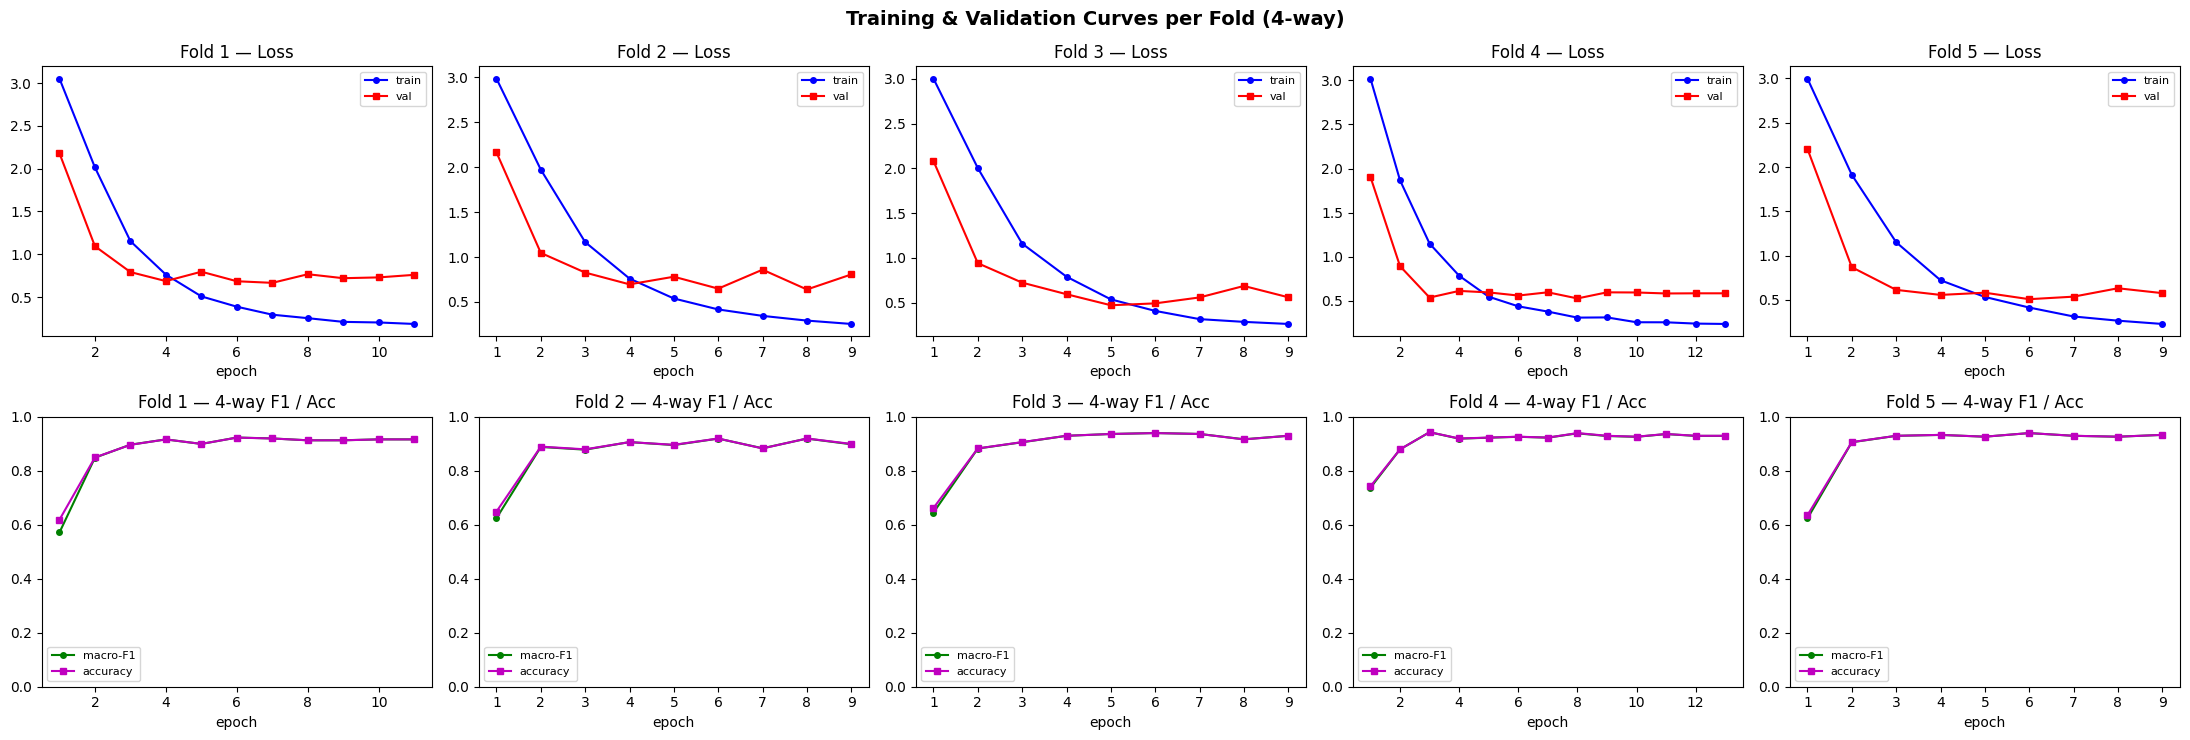

In [18]:
import matplotlib.pyplot as plt, matplotlib
matplotlib.rcParams["font.family"] = "DejaVu Sans"

hist = full_cv["history"]; nF = len(hist)
fig, axes = plt.subplots(2, nF, figsize=(4.4*nF, 7.5), squeeze=False)
fig.suptitle("Training & Validation Curves per Fold (4-way)", fontsize=14, fontweight="bold")
for f, h in hist.items():
    ep = range(1, len(h["train_loss"]) + 1)
    ax = axes[0][f]
    ax.plot(ep, h["train_loss"], "b-o", ms=4, label="train"); ax.plot(ep, h["val_loss"], "r-s", ms=4, label="val")
    ax.set_title(f"Fold {f+1} — Loss"); ax.legend(fontsize=8); ax.set_xlabel("epoch")
    ax = axes[1][f]
    ax.plot(ep, h["cls_f1"], "g-o", ms=4, label="macro-F1"); ax.plot(ep, h["cls_acc"], "m-s", ms=4, label="accuracy")
    ax.set_title(f"Fold {f+1} — 4-way F1 / Acc"); ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.set_xlabel("epoch")
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150, bbox_inches="tight"); plt.show()


## Section 13 — Hold-out Evaluation via the 5-Fold **Ensemble**

The reported model averages the **softmax** probabilities of the five fold models. Each fold model is paired with **its own fold-fitted intent encoder**, so no encoder ever saw the rows it scores.

Evaluation is at the four-way level: the classification report (precision / recall / F1 for each of the four classes), accuracy, macro-F1, weighted-F1, MCC and macro one-vs-rest AUC, plus the 4×4 confusion matrix. The sarcasm and offensive views are reported as *implied* binary decisions (classes {Pure Sarcastic, Sarcastic Offense} and {Pure Offensive, Sarcastic Offense}), so they are consistent with the primary prediction rather than coming from a separate model.

In [19]:
# Section 13 — Hold-out evaluation via 5-fold ENSEMBLE (4-way)
REF_SEED = CFG["ABLATION_SEED"]
REF_CHECKPOINT = os.path.join(CFG["RUN_DIR"], f"ref_run_4cls_seed{REF_SEED}.pt")
if "full_cv" not in globals():
    if os.path.exists(REF_CHECKPOINT):
        print(f"Loading reference run checkpoint from {REF_CHECKPOINT}")
        full_cv = load_cv_checkpoint(REF_CHECKPOINT)
    else:
        raise FileNotFoundError(f"No checkpoint at {REF_CHECKPOINT}. Run Section 12 first.")

y4_test   = df_test.label.values
sarc_true = df_test.sarcasm.values
off_true  = df_test.offensive.values
P4_test   = ensemble_predict(full_cv["models"], full_cv["encoders"], df_test.text.values)
yp4_test  = P4_test.argmax(1)

def _report(tag, P, save_csv=None):
    yp = P.argmax(1)
    print("=" * 66); print(f"  HOLD-OUT TEST (4-way) — {tag}"); print("=" * 66)
    print(classification_report(y4_test, yp, labels=LABELS4, target_names=CLASS_NAMES,
                                digits=4, zero_division=0))
    print("── Confusion (rows = true, cols = predicted) ──")
    cm = pd.DataFrame(confusion_matrix(y4_test, yp, labels=LABELS4), index=CLASS_NAMES, columns=CLASS_NAMES)
    print(cm.to_string())
    row = {"tag": tag, "acc": accuracy_score(y4_test, yp),
           "macro_f1": f1_score(y4_test, yp, average="macro", labels=LABELS4, zero_division=0),
           "weighted_f1": f1_score(y4_test, yp, average="weighted", labels=LABELS4, zero_division=0),
           "mcc": matthews_corrcoef(y4_test, yp), "auc_ovr_macro": _safe_auc_ovr(y4_test, P)}
    print(f"\n  Accuracy {row['acc']:.4f} | macro-F1 {row['macro_f1']:.4f} | weighted-F1 {row['weighted_f1']:.4f}"
          f" | MCC {row['mcc']:+.4f} | macro OvR-AUC {row['auc_ovr_macro']:.4f}")
    # binary views implied by the 4-way prediction (secondary; comparable to the old two-head design)
    ps, po = derived_binary(P)
    spd = np.isin(yp, [0, 2]).astype(int); opd = np.isin(yp, [1, 2]).astype(int)
    row.update({"sarc_f1": f1_score(sarc_true, spd, average="macro", zero_division=0),
                "off_f1": f1_score(off_true, opd, average="macro", zero_division=0),
                "sarc_auc": roc_auc_score(sarc_true, ps), "off_auc": roc_auc_score(off_true, po)})
    print(f"  Implied binary views — Sarcasm macro-F1 {row['sarc_f1']:.4f} (AUC {row['sarc_auc']:.4f}) | "
          f"Offensive macro-F1 {row['off_f1']:.4f} (AUC {row['off_auc']:.4f})")
    if save_csv:
        pd.DataFrame([row]).to_csv(os.path.join(CFG["RUN_DIR"], save_csv), index=False)
    return row

holdout_metrics = _report("5-FOLD ENSEMBLE (unseen data)", P4_test, save_csv="holdout_4class_metrics.csv")
print(f"\nSaved -> {os.path.join(CFG['RUN_DIR'], 'holdout_4class_metrics.csv')}")


  HOLD-OUT TEST (4-way) — 5-FOLD ENSEMBLE (unseen data)
                   precision    recall  f1-score   support

   Pure Sarcastic     0.9391    0.9310    0.9351       116
   Pure Offensive     0.9370    0.9754    0.9558       122
Sarcastic Offense     0.9652    0.9487    0.9569       117
          Neutral     0.9565    0.9429    0.9496       140

         accuracy                         0.9495       495
        macro avg     0.9495    0.9495    0.9494       495
     weighted avg     0.9497    0.9495    0.9495       495

── Confusion (rows = true, cols = predicted) ──
                   Pure Sarcastic  Pure Offensive  Sarcastic Offense  Neutral
Pure Sarcastic                108               2                  3        3
Pure Offensive                  0             119                  0        3
Sarcastic Offense               1               5                111        0
Neutral                         6               1                  1      132

  Accuracy 0.9495 | macro-F1 0

## Section 13b — Confusion Matrices & ROC Curves (hold-out)

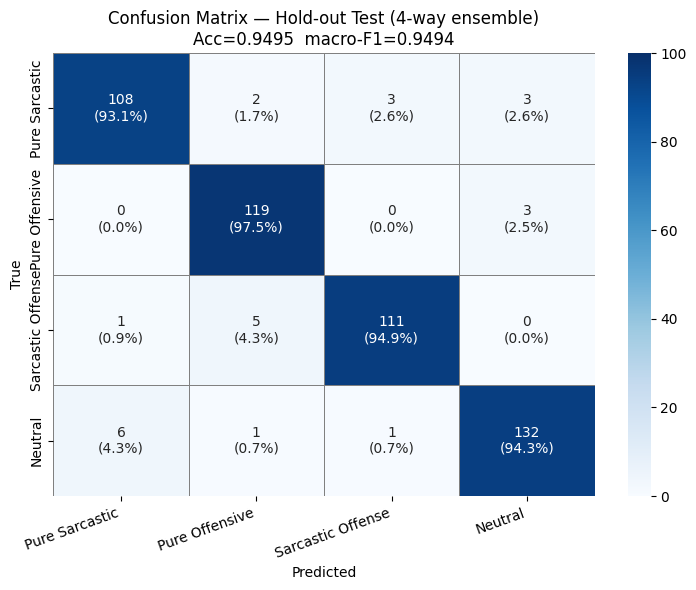

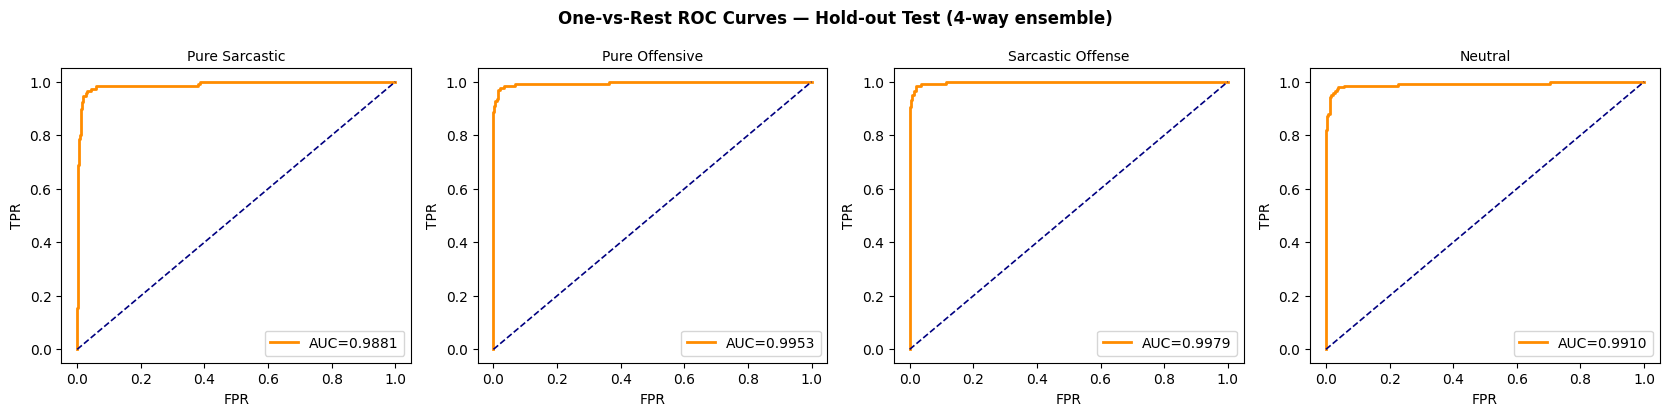

In [20]:
import seaborn as sns
from sklearn.preprocessing import label_binarize

cm  = confusion_matrix(y4_test, yp4_test, labels=LABELS4)
pct = cm / cm.sum(1, keepdims=True) * 100
annot = np.array([[f"{cm[i,j]}\n({pct[i,j]:.1f}%)" for j in range(N_CLASSES)] for i in range(N_CLASSES)])
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=ax, vmin=0, vmax=100, linewidths=.5, linecolor="gray", annot_kws={"size": 10})
ax.set_title(f"Confusion Matrix — Hold-out Test (4-way ensemble)\n"
             f"Acc={accuracy_score(y4_test, yp4_test):.4f}  "
             f"macro-F1={f1_score(y4_test, yp4_test, average='macro', zero_division=0):.4f}")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout(); plt.savefig("confusion_matrix_4way.png", dpi=150, bbox_inches="tight"); plt.show()

Y1 = label_binarize(y4_test, classes=LABELS4)
fig, axes = plt.subplots(1, N_CLASSES, figsize=(4.2*N_CLASSES, 4.2))
for k, ax in enumerate(axes):
    fpr, tpr, _ = roc_curve(Y1[:, k], P4_test[:, k])
    ax.plot(fpr, tpr, "darkorange", lw=2, label=f"AUC={auc(fpr, tpr):.4f}")
    ax.plot([0, 1], [0, 1], "navy", ls="--", lw=1.2)
    ax.set_title(CLASS_NAMES[k], fontsize=10); ax.legend(loc="lower right")
    ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
fig.suptitle("One-vs-Rest ROC Curves — Hold-out Test (4-way ensemble)", fontweight="bold")
plt.tight_layout(); plt.savefig("roc_curves_4way.png", dpi=150, bbox_inches="tight"); plt.show()


## Section 13c — Probability Calibration (reliability, ECE / MCE / Brier / NLL, temperature scaling)

A high macro-F1 does not guarantee trustworthy probabilities. We measure the calibration of the deployed 5-fold ensemble on the TEST sheet with top-label ECE and MCE, the multi-class Brier score and the NLL, and draw a top-label reliability diagram. A single **temperature** is fitted on **out-of-fold train/CV predictions** (the test set is never used to fit T). Per-class probability multipliers tuned on the OOF predictions are reported alongside the plain argmax.

Fitted temperature (OOF train/CV, leakage-free): T=1.301

OOF-tuned class weights: {'Pure Sarcastic': 1.0, 'Pure Offensive': 1.0, 'Sarcastic Offense': 1.0, 'Neutral': 1.0} | OOF macro-F1 0.9277

=== TEST macro-F1: argmax vs OOF-tuned class weights ===
  argmax : 0.9494
  tuned  : 0.9494

=== CALIBRATION ON HOLD-OUT TEST (4-way ensemble, top-label) ===
  raw  : ECE=0.0187 MCE=0.1466 Brier=0.0793 NLL=0.1742
  temp : ECE=0.0553 MCE=0.1247 Brier=0.0830 NLL=0.1990


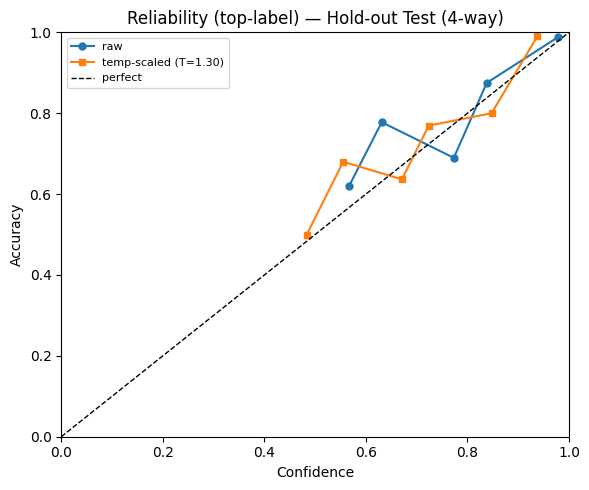

In [21]:
# Section 13c — Calibration (4-way temperature scaling) + OOF class-weight tuning
from scipy.optimize import minimize_scalar

def _nll(P, y):
    return float(-np.mean(np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1.0))))

def _temp_scale(P, T):
    Z = np.log(np.clip(P, 1e-12, 1.0)) / T
    Z = Z - Z.max(1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(1, keepdims=True)

def calib_scores(P, y, n_bins=10):
    """Top-label ECE/MCE (confidence = max prob), multi-class Brier, NLL."""
    conf = P.max(1); correct = (P.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(conf, edges[1:-1]), 0, n_bins - 1)
    ece, mce = 0.0, 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            gap = abs(correct[m].mean() - conf[m].mean())
            ece += m.mean() * gap; mce = max(mce, gap)
    onehot = np.eye(N_CLASSES)[y]
    return {"ECE": ece, "MCE": mce,
            "Brier": float(np.mean(np.sum((P - onehot) ** 2, 1))), "NLL": _nll(P, y)}

# leakage-free OOF probabilities on the train/CV pool: each row is scored by the fold model
# for which it was in the VALIDATION split. The hold-out test set is not used to fit anything here.
oof_P = np.full((len(df_trainval), N_CLASSES), np.nan)
for f, (a, b) in enumerate(full_cv["fold_indices"]):
    oof_P[b] = ensemble_predict([full_cv["models"][f]], [full_cv["encoders"][f]],
                                df_trainval.text.values[b])
y4_tv = df_trainval.label.values

T_cls = float(minimize_scalar(lambda T: _nll(_temp_scale(oof_P, T), y4_tv),
                              bounds=(0.05, 10.0), method="bounded").x)
print(f"Fitted temperature (OOF train/CV, leakage-free): T={T_cls:.3f}\n")

def tune_class_weights(P, y, grid=np.linspace(0.5, 2.0, 16), iters=2):
    """Coordinate ascent on per-class probability multipliers to maximise OOF macro-F1."""
    w = np.ones(N_CLASSES)
    best = f1_score(y, (P * w).argmax(1), average="macro", labels=LABELS4, zero_division=0)
    for _ in range(iters):
        for k in range(N_CLASSES):
            for g in grid:
                w2 = w.copy(); w2[k] = g
                s = f1_score(y, (P * w2).argmax(1), average="macro", labels=LABELS4, zero_division=0)
                if s > best + 1e-12:
                    best, w = s, w2
    return w, best

W_cls, oof_best = tune_class_weights(oof_P, y4_tv)
print("OOF-tuned class weights:", {n: round(float(w), 3) for n, w in zip(CLASS_NAMES, W_cls)},
      f"| OOF macro-F1 {oof_best:.4f}")

P4_test_tuned = P4_test * W_cls
print("\n=== TEST macro-F1: argmax vs OOF-tuned class weights ===")
print(f"  argmax : {f1_score(y4_test, P4_test.argmax(1), average='macro', zero_division=0):.4f}")
print(f"  tuned  : {f1_score(y4_test, P4_test_tuned.argmax(1), average='macro', zero_division=0):.4f}")

P4_test_cal = _temp_scale(P4_test, T_cls)
print("\n=== CALIBRATION ON HOLD-OUT TEST (4-way ensemble, top-label) ===")
cal_rows = []
for variant, P in [("raw", P4_test), ("temp", P4_test_cal)]:
    s = calib_scores(P, y4_test); cal_rows.append({"variant": variant, **s})
    print(f"  {variant:<5}: ECE={s['ECE']:.4f} MCE={s['MCE']:.4f} Brier={s['Brier']:.4f} NLL={s['NLL']:.4f}")
pd.DataFrame(cal_rows).to_csv(os.path.join(CFG["RUN_DIR"], "calibration_4way.csv"), index=False)

fig, ax = plt.subplots(figsize=(6, 5))
for P, lab, style in [(P4_test, "raw", "o-"), (P4_test_cal, f"temp-scaled (T={T_cls:.2f})", "s-")]:
    conf = P.max(1); correct = (P.argmax(1) == y4_test).astype(float)
    edges = np.linspace(0, 1, 11); idx = np.clip(np.digitize(conf, edges[1:-1]), 0, 9)
    xs, ys_ = [], []
    for b in range(10):
        m = idx == b
        if m.any(): xs.append(conf[m].mean()); ys_.append(correct[m].mean())
    ax.plot(xs, ys_, style, ms=5, label=lab)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax.set_title("Reliability (top-label) — Hold-out Test (4-way)")
ax.set_xlabel("Confidence"); ax.set_ylabel("Accuracy")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig("calibration_reliability_4way.png", dpi=150, bbox_inches="tight"); plt.show()


## Section 13d — Robustness to Input Perturbations

We probe how stable the 4-way ensemble is under perturbations of the hold-out inputs:

* **emoji_drop**: all emojis removed (text *and* intent vector lose the signal). Expected degradation; it quantifies how much the model relies on emojis.
* **emoji_swap_in**: one emoji swapped for a sibling in the same intent cluster (meaning-preserving). Predictions should be stable.
* **emoji_swap_cross**: one emoji swapped for an emoji from another cluster (distractor). Measures spurious sensitivity.
* **emoji_repeat_x3**: existing emojis tripled. Intensity robustness.
* **char_typo**: character-level noise on the Bangla text, emojis kept.

The per-row predictions of every perturbation are stored in `rob_preds`, so Section 14d can re-use the emoji-drop predictions without re-running the model.

=== ROBUSTNESS TO INPUT PERTURBATIONS (4-way ensemble, hold-out) ===
    perturbation  macroF1_4way  Δmacro_F1  flip%_all  flip%_emoji_rows
           clean        0.9494     0.0000     0.0000            0.0000
      emoji_drop        0.9403    -0.0090     3.0303            4.4510
   emoji_swap_in        0.9473    -0.0021     0.2020            0.2967
emoji_swap_cross        0.9449    -0.0045     2.2222            3.2641
 emoji_repeat_x3        0.9515     0.0021     1.2121            1.7804
       char_typo        0.8912    -0.0581     7.4747            9.1988


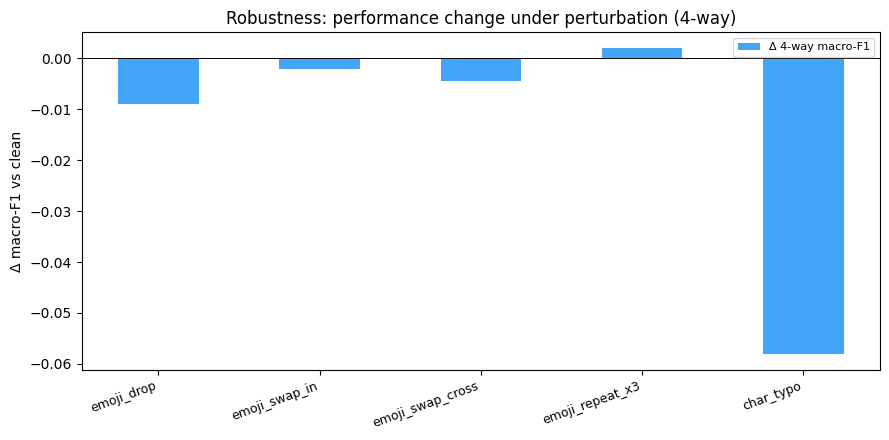


Reading the table: emoji_drop should show the LARGEST drop (model uses emoji signal);
emoji_swap_in / char_typo should show SMALL ΔF1 + low flip-rate (meaning-preserving → robust);
emoji_swap_cross probes spurious sensitivity to a distractor emoji.


In [22]:
# Section 13d — Robustness to input perturbations (4-way ensemble, hold-out)
rob_rng = random.Random(SEED)

def perturb_emoji_drop(t):   return strip_emojis(t)

# swap-in draws from EMOJI_TO_EVAL_CLUSTER: the held-out half never used for training augmentation
def perturb_emoji_swap_in(t):
    chars = list(str(t)); pos = [i for i, c in enumerate(chars) if c in EMOJI_TO_EVAL_CLUSTER]
    if not pos: return t
    i = rob_rng.choice(pos); cur = chars[i]
    opts = [e for e in EMOJI_TO_EVAL_CLUSTER[cur] if e != cur]
    if opts: chars[i] = rob_rng.choice(opts)
    return "".join(chars)

def perturb_emoji_swap_cross(t):
    chars = list(str(t)); pos = [i for i, c in enumerate(chars) if c in EMOJI_TO_CLUSTER]
    if not pos: return t
    i = rob_rng.choice(pos); cur = chars[i]
    same = set(next((cl for cl in CLUSTERS if cur in cl), []))
    other = [c for cl in CLUSTERS for c in cl if c not in same]
    if other: chars[i] = rob_rng.choice(other)
    return "".join(chars)

def perturb_emoji_repeat(t, k=3):
    return "".join(c * (k if c in emojilib.EMOJI_DATA else 1) for c in str(t))

def perturb_typo(t, p=0.08):
    out = []
    for c in str(t):
        if c in emojilib.EMOJI_DATA: out.append(c); continue
        r = rob_rng.random()
        if r < p * 0.5:      continue                          # drop char
        elif r < p:          out.append(c); out.append(c)      # duplicate char
        else:                out.append(c)
    return "".join(out)

def eval_perturbation(texts):
    P = ensemble_predict(full_cv["models"], full_cv["encoders"], list(texts))
    pred = P.argmax(1)
    return pred, f1_score(y4_test, pred, average="macro", labels=LABELS4, zero_division=0)

clean_texts = list(df_test.text.values)
has_emoji   = np.array([len(extract_emojis(t)) > 0 for t in clean_texts])
base_pred, base_f1 = eval_perturbation(clean_texts)

# AUDIT/REV-2: the per-row predictions of every perturbation are KEPT, so Part 2 (Section 14d)
# re-uses the emoji-drop predictions instead of re-running the model.
rob_preds = {"clean": base_pred}

PERTS = [("emoji_drop",       [perturb_emoji_drop(t)       for t in clean_texts]),
         ("emoji_swap_in",    [perturb_emoji_swap_in(t)    for t in clean_texts]),
         ("emoji_swap_cross", [perturb_emoji_swap_cross(t) for t in clean_texts]),
         ("emoji_repeat_x3",  [perturb_emoji_repeat(t)     for t in clean_texts]),
         ("char_typo",        [perturb_typo(t)             for t in clean_texts])]

rows = [{"perturbation": "clean", "macroF1_4way": base_f1, "Δmacro_F1": 0.0,
         "flip%_all": 0.0, "flip%_emoji_rows": 0.0}]
for name, texts in PERTS:
    pred, f1p = eval_perturbation(texts)
    rob_preds[name] = pred
    changed = pred != base_pred
    rows.append({"perturbation": name, "macroF1_4way": f1p, "Δmacro_F1": f1p - base_f1,
                 "flip%_all": changed.mean() * 100,
                 "flip%_emoji_rows": changed[has_emoji].mean() * 100 if has_emoji.any() else float("nan")})

rob_df = pd.DataFrame(rows)
print("=== ROBUSTNESS TO INPUT PERTURBATIONS (4-way ensemble, hold-out) ===")
print(rob_df.round(4).to_string(index=False))
rob_df.to_csv(os.path.join(CFG["RUN_DIR"], "robustness_4way.csv"), index=False)

plot_df = rob_df[rob_df.perturbation != "clean"]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(np.arange(len(plot_df)), plot_df["Δmacro_F1"], 0.5, color="#42a5f5", label="Δ 4-way macro-F1")
ax.axhline(0, color="k", lw=.7)
ax.set_xticks(np.arange(len(plot_df))); ax.set_xticklabels(plot_df["perturbation"], rotation=20, ha="right", fontsize=9)
ax.set_ylabel("Δ macro-F1 vs clean"); ax.set_title("Robustness: performance change under perturbation (4-way)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("robustness_delta_f1_4way.png", dpi=150, bbox_inches="tight"); plt.show()

print("\nReading the table: emoji_drop should show the LARGEST drop (model uses emoji signal);")
print("emoji_swap_in / char_typo should show SMALL ΔF1 + low flip-rate (meaning-preserving → robust);")
print("emoji_swap_cross probes spurious sensitivity to a distractor emoji.")

## Section 14 — Explainability: LIME on the Model's Real (Preprocessed) Input

LIME is run on the **preprocessed** text — the exact emoji-expanded string the model
consumes — so attributions reflect the deployed pipeline. Each emoji phrase is kept as
**one atomic token** (via a NUL-joined surrogate encoding), and the emoji-intent vector is
**held fixed** during perturbation so the explanation isolates the *text-encoder* pathway
where emoji tokens live.

*Reviewer Q&A — "Why preprocessed, not raw?"* Explaining raw text would attribute a
transformation the model never sees; explaining the true input is faithful to what is
actually classified.

**Section 14a** (below) shows per-token attributions for one representative emoji-bearing
example. **Section 14b** then aggregates the same measurement over **every** emoji-bearing
row of the hold-out set and tests the population-level hypothesis. The aggregate arrays
computed in 14b are cached and reused by Section 19, so LIME is executed **once** for the
whole notebook.

**Performance note.** The forward pass used inside LIME keeps all fold models **resident on
the device** for the duration of a batch of explanations, chunks each perturbation set into
`CFG["LIME_INFER_BATCH"]` rows, pads dynamically rather than to `MAX_LEN`, and runs under
`torch.inference_mode()` with optional fp16 autocast. The earlier implementation moved every
fold model host↔device on *each* `predict_fn` call and pushed all `LIME_SAMPLES` rows through
in one full-length batch — with five folds, two tasks and hundreds of examples that is what
made Section 19 appear to hang.


In [23]:
from lime.lime_text import LimeTextExplainer
from contextlib import contextmanager

# Stable explainer encoder: fit on the train/CV pool only (never on test labels).
explain_encoder = EmojiIntentEncoder().fit(
    df_trainval.text.values, df_trainval.sarcasm.values, df_trainval.offensive.values)

CFG.setdefault("LIME_INFER_BATCH", 64)
CFG.setdefault("LIME_AUTOCAST", True)

# LIME runs on the PREPROCESSED text. Bracketed emoji phrases are kept as one atomic token by
# swapping their internal spaces for NUL ("\x00") in a surrogate string; predict_fn restores them.
def _units(exp_text):
    """Split preprocessed text into units; bracketed emoji phrases stay atomic."""
    toks, units, buf = exp_text.split(" "), [], []
    for t in toks:
        if buf:
            buf.append(t)
            if t.endswith("]"): units.append(" ".join(buf)); buf = []
        elif t.startswith("[") and not t.endswith("]"):
            buf = [t]
        else:
            units.append(t)
    if buf: units.append(" ".join(buf))
    return [u for u in units if u]

def to_surrogate(exp_text):
    return " ".join(u.replace(" ", "\x00") for u in _units(exp_text))

def is_emoji_token(tok):
    return tok.strip().startswith("[")

@contextmanager
def lime_models_resident(models):
    """Keep the fold models on DEVICE for a whole batch of explanations (no per-call transfers)."""
    try:
        for m in models: m.to(DEVICE).eval()
        yield models
    finally:
        for m in models: m.to("cpu")
        if torch.cuda.is_available(): torch.cuda.empty_cache()

def make_lime_predict_fn_pre(models, intent_vec, batch_size=None):
    """LIME predict_fn over surrogate strings -> [n, N_CLASSES] softmax probabilities (fold-averaged).
    The intent vector is held fixed at the original example's value."""
    feat0   = torch.tensor(np.asarray(intent_vec, dtype=np.float32))     # [1, 10]
    bs      = CFG["LIME_INFER_BATCH"] if batch_size is None else batch_size
    use_amp = bool(CFG.get("LIME_AUTOCAST", True)) and torch.cuda.is_available()

    def predict_fn(surrogate_texts):
        real = [s.replace("\x00", " ") for s in surrogate_texts]
        prob = np.zeros((len(real), N_CLASSES), dtype=np.float64)
        for i in range(0, len(real), bs):
            chunk = real[i:i+bs]
            enc = tokenizer(chunk, max_length=CFG["MAX_LEN"], padding=True,
                            truncation=True, return_tensors="pt")
            ids = enc["input_ids"].to(DEVICE); msk = enc["attention_mask"].to(DEVICE)
            feats = feat0.to(DEVICE).repeat(len(chunk), 1)
            acc = np.zeros((len(chunk), N_CLASSES))
            for m in models:
                if next(m.parameters()).device != ids.device:
                    m.to(DEVICE)
                m.eval()
                with torch.inference_mode():
                    if use_amp:
                        with torch.autocast("cuda", dtype=torch.float16):
                            c, _, _ = m(ids, msk, feats)
                    else:
                        c, _, _ = m(ids, msk, feats)
                acc += torch.softmax(c.float(), dim=1).cpu().numpy()
            prob[i:i+bs] = acc / len(models)
        return prob
    return predict_fn

# lime's default split regex (\W+) shreds Bangla matras, so emoji phrases never survive as one
# token. We set the split expression explicitly (both spellings across lime versions) and
# self-test that a bracketed phrase really stays atomic.
_LIME_SPLIT = r"\s+"

def _make_lime_text_explainer(class_names, split_regex=_LIME_SPLIT):
    import inspect
    _params = inspect.signature(LimeTextExplainer.__init__).parameters
    _kwargs = {"class_names": class_names}
    for _n in ("split_expression", "split_expr"):
        if _n in _params: _kwargs[_n] = split_regex
    if "bow" in _params: _kwargs["bow"] = True
    _explainer = LimeTextExplainer(**_kwargs)
    for _n in ("split_expression", "split_expr"):
        setattr(_explainer, _n, split_regex)
    _explainer.bow = True
    _explainer.char_level = False
    return _explainer

def _lime_tokenizer_selftest(verbose=True):
    from lime.lime_text import IndexedString
    probe_raw = "ভালো কাজ [ব্যঙ্গাত্মক হাসি] ছিল"
    probe     = to_surrogate(probe_raw)
    ex        = _make_lime_text_explainer(["a", "b"])
    split     = getattr(ex, "split_expression", getattr(ex, "split_expr", None))
    try:
        idx = IndexedString(probe, bow=True, split_expression=split)
    except TypeError:
        idx = IndexedString(probe, bow=True, split_expr=split)
    words   = [w.replace("\x00", " ") for w in idx.as_list]
    n_emoji = sum(1 for w in words if is_emoji_token(w))
    ok      = n_emoji == 1
    if verbose:
        print(f"LIME tokeniser self-test: split={split!r} | tokens={words} | "
              f"emoji-phrase tokens={n_emoji} -> {'OK' if ok else 'FAILED'}")
        if not ok:
            warnings.warn("LIME is NOT keeping emoji phrases atomic; emoji attributions will read as 0.")
    return ok

def _explain_one(raw_text, class_idx, models, num_samples, num_features):
    surrogate = to_surrogate(preprocess(raw_text))
    ivec      = explain_encoder.transform([raw_text])
    fn        = make_lime_predict_fn_pre(models, ivec)
    explainer = _make_lime_text_explainer(CLASS_NAMES)
    return explainer.explain_instance(surrogate, fn, num_features=num_features,
                                      num_samples=num_samples, labels=[class_idx])

def lime_explain_pre(raw_text, class_idx, models=None, num_samples=None,
                     num_features=15, models_resident=False):
    """Explain ONE example for the given class index (4-way)."""
    models = full_cv["models"] if models is None else models
    num_samples = CFG["LIME_SAMPLES"] if num_samples is None else num_samples
    if models_resident:
        return _explain_one(raw_text, class_idx, models, num_samples, num_features)
    with lime_models_resident(models):
        return _explain_one(raw_text, class_idx, models, num_samples, num_features)

def lime_features(exp, class_idx):
    """Return [(readable_token, weight)] for the explained class, NUL restored to space."""
    return [(feat.replace("\x00", " "), w) for feat, w in exp.as_list(label=class_idx)]

_LIME_TOKENIZER_OK = _lime_tokenizer_selftest()

# representative hold-out post that contains an emoji
cand = [i for i in range(len(df_test)) if extract_emojis(df_test.text.iloc[i])]
sidx = cand[0]
raw_example  = df_test.text.iloc[sidx]
pred_example = int(yp4_test[sidx])
print(f"Emoji-bearing hold-out rows: {len(cand)} / {len(df_test)}")
print(f"Explaining: {raw_example}")
print(f"  preprocessed: {preprocess(raw_example)}")
print(f"  truth: {CLASS_NAMES[y4_test[sidx]]} | predicted: {CLASS_NAMES[pred_example]}")


LIME tokeniser self-test: split='\\s+' | tokens=['ভালো', ' ', 'কাজ', ' ', '[ব্যঙ্গাত্মক হাসি]', ' ', 'ছিল'] | emoji-phrase tokens=1 -> OK
Emoji-bearing hold-out rows: 337 / 495
Explaining: Protita character er perfection chilo oshadharon. ⭐
  preprocessed: Protita character er perfection chilo oshadharon. [ইমোজি: star]
  truth: Neutral | predicted: Neutral


In [24]:
# ---- LIME cache: Sections 14b and 14c share it, so each (test row, class) is explained ONCE ----
LIME_CACHE = {}

def lime_explain_cached(i, k):
    """LIME explanation of hold-out row i for class k. Call inside `lime_models_resident(...)`."""
    key = (int(i), int(k))
    if key not in LIME_CACHE:
        LIME_CACHE[key] = lime_explain_pre(df_test.text.iloc[int(i)], int(k),
                                           num_samples=CFG["LIME_SAMPLES"], models_resident=True)
    return LIME_CACHE[key]

print(f"LIME cache ready (keys = (test_row, class)); entries so far: {len(LIME_CACHE)}")

LIME cache ready (keys = (test_row, class)); entries so far: 0


Model P(4-way) for this post: Pure Sarcastic=0.006, Pure Offensive=0.007, Sarcastic Offense=0.006, Neutral=0.981

LIME (14a, single example) — explaining predicted class 'Neutral':
  🔤 chilo                        +0.0005
  🔤 oshadharon.                  +0.0005
  🔤 Protita                      +0.0004
  🔤 character                    +0.0004
  🔤 perfection                   +0.0003
  😀 [ইমোজি: star]                +0.0003
  🔤 er                           +0.0000


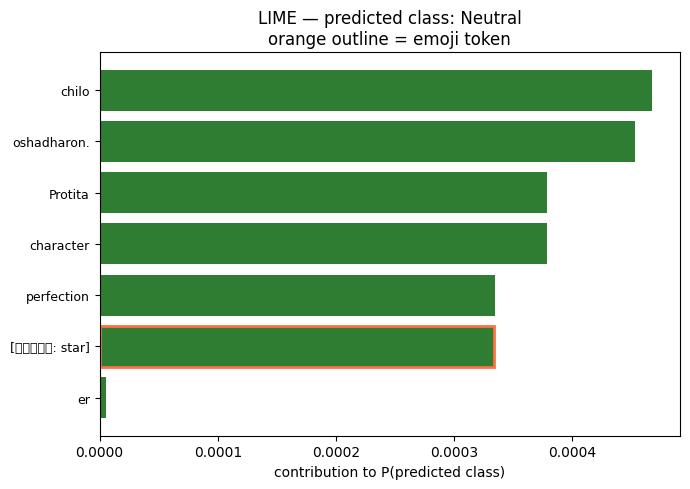

In [25]:
P_ex = ensemble_predict(full_cv["models"], full_cv["encoders"], [raw_example])[0]
print("Model P(4-way) for this post: " + ", ".join(f"{n}={p:.3f}" for n, p in zip(CLASS_NAMES, P_ex)))

exp   = lime_explain_pre(raw_example, pred_example)
feats = lime_features(exp, pred_example)
print(f"\nLIME (14a, single example) — explaining predicted class '{CLASS_NAMES[pred_example]}':")
for feat, w in feats:
    print(f"  {'😀' if is_emoji_token(feat) else '🔤'} {feat:<28} {w:+.4f}")

labels = [f for f, _ in feats][::-1]; vals = [w for _, w in feats][::-1]
colors = ["#2e7d32" if w >= 0 else "#c62828" for w in vals]
edges  = ["#ff7043" if is_emoji_token(f) else "none" for f in labels]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(range(len(vals)), vals, color=colors, edgecolor=edges, linewidth=2)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=9)
ax.axvline(0, color="k", lw=.6)
ax.set_title(f"LIME — predicted class: {CLASS_NAMES[pred_example]}\norange outline = emoji token")
ax.set_xlabel("contribution to P(predicted class)")
plt.tight_layout(); plt.savefig("lime_single_example_4way.png", dpi=150, bbox_inches="tight"); plt.show()


## Section 14b — Emoji vs Word Contribution (**aggregate over all emoji-bearing test examples**)

Section 14a explained one example. Here we aggregate over **every** hold-out example that contains at least one emoji. Each example is explained for its **predicted** four-way class, the emoji-phrase tokens and the word tokens are separated, and the mean |LIME weight| of each group is recorded. Only examples with both token types are kept, so each retained observation is a paired comparison inside the same sentence.

H₁: mean |LIME weight| of emoji tokens > that of word tokens, tested with a one-sided paired *t*-test and a one-sided Wilcoxon signed-rank test. The per-example arrays are cached in `LIME_AGG` and the explanations in `LIME_CACHE`, so Section 14c and Section 19 never run LIME twice for the same (example, class) pair.

  SECTION 14b — AGGREGATE EMOJI vs WORD CONTRIBUTION (LIME, 4-way)
Hold-out rows            : 495
Rows containing >=1 emoji: 337  (68.1% of the test set)
LIME perturbations/example: 300 | explained class: model's predicted class


LIME[pred]:   0%|          | 0/337 [00:00<?, ?it/s]

  paired examples retained: 327 (10 skipped: no word or no emoji token)

------------------------------------------------------------------------
  paired examples (n)       : 327
  mean |LIME weight| emoji  : 0.0677   (median 0.0416)
  mean |LIME weight| word   : 0.0623   (median 0.0647)
  mean paired difference    : +0.0053  | emoji > word in 41.3% of examples
  emoji share of attribution: 52.0%

  per predicted class:
  predicted class  n  emoji_mean  word_mean
   Pure Sarcastic 98      0.1141     0.0717
   Pure Offensive 73      0.0634     0.0646
Sarcastic Offense 85      0.0551     0.0882
          Neutral 71      0.0229     0.0160
  paired t-test  (H1: emoji > word) : t=+1.1108   p(one-sided)=1.337e-01
  Wilcoxon signed-rank (one-sided)  : p=9.967e-01
  VERDICT @ α=0.05                  : NOT significant

Saved -> /kaggle/working/runs/lime_emoji_vs_word_aggregate_4way.csv


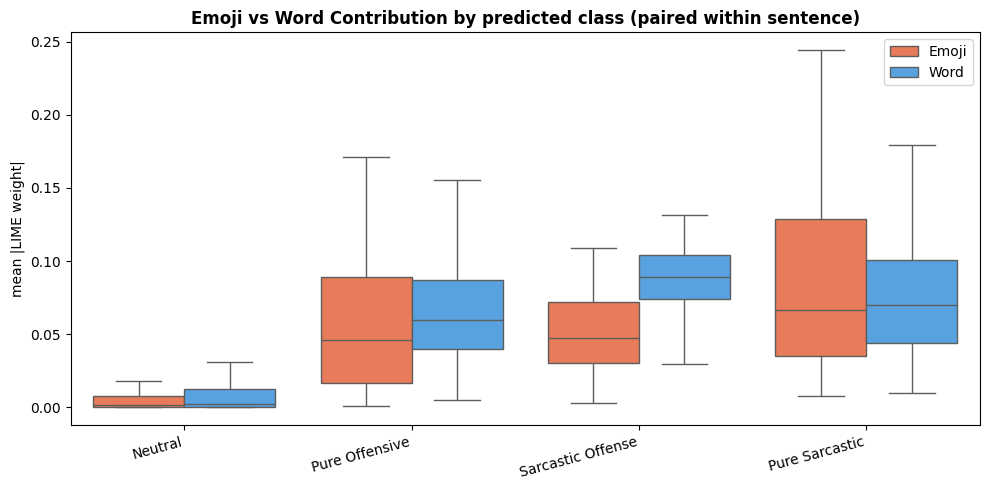


Interpretation: each point is ONE hold-out post explained for its predicted class. Emoji and word
weights are measured in the same sentence, so the paired tests control for length and topic.


In [26]:
from scipy.stats import ttest_rel, wilcoxon
import seaborn as sns

def emoji_word_split(exp, class_idx):
    """Split a LIME explanation into (emoji_tokens, word_tokens) as [(token, weight)]."""
    em, wd = [], []
    for feat, w in lime_features(exp, class_idx):
        (em if is_emoji_token(feat) else wd).append((feat, w))
    return em, wd

# 1. every hold-out row containing >=1 emoji
emoji_test_idx = [i for i in range(len(df_test)) if extract_emojis(df_test.text.iloc[i])]
if CFG.get("LIME_MAX_EXAMPLES"):
    emoji_test_idx = emoji_test_idx[:CFG["LIME_MAX_EXAMPLES"]]

print("=" * 72)
print("  SECTION 14b — AGGREGATE EMOJI vs WORD CONTRIBUTION (LIME, 4-way)")
print("=" * 72)
print(f"Hold-out rows            : {len(df_test)}")
print(f"Rows containing >=1 emoji: {len(emoji_test_idx)}  "
      f"({100*len(emoji_test_idx)/max(len(df_test),1):.1f}% of the test set)")
print(f"LIME perturbations/example: {CFG['LIME_SAMPLES']} | explained class: model's predicted class")

# 2. LIME on every selected row, for its PREDICTED class
em_means, wd_means, kept_idx = [], [], []
with lime_models_resident(full_cv["models"]):
    for i in tqdm(emoji_test_idx, desc="LIME[pred]", leave=False):
        k = int(yp4_test[i])
        exp = lime_explain_cached(i, k)          # shared cache with Section 14c
        em, wd = emoji_word_split(exp, k)
        if not em or not wd:                 # keep the comparison strictly paired
            continue
        em_means.append(float(np.mean([abs(w) for _, w in em])))
        wd_means.append(float(np.mean([abs(w) for _, w in wd])))
        kept_idx.append(i)

LIME_AGG = {"pred": {"emoji": np.array(em_means), "word": np.array(wd_means), "idx": kept_idx}}
print(f"  paired examples retained: {len(kept_idx)} "
      f"({len(emoji_test_idx)-len(kept_idx)} skipped: no word or no emoji token)")

# 3. aggregate statistics + hypothesis tests
em = LIME_AGG["pred"]["emoji"]; wd = LIME_AGG["pred"]["word"]
agg_rows = []
print("\n" + "-" * 72)
if len(em) == 0:
    print("no paired examples — nothing to report.")
else:
    print(f"  paired examples (n)       : {len(em)}")
    print(f"  mean |LIME weight| emoji  : {em.mean():.4f}   (median {np.median(em):.4f})")
    print(f"  mean |LIME weight| word   : {wd.mean():.4f}   (median {np.median(wd):.4f})")
    print(f"  mean paired difference    : {(em-wd).mean():+.4f}  | emoji > word in {100*np.mean(em>wd):.1f}% of examples")
    print(f"  emoji share of attribution: {100*em.mean()/max(em.mean()+wd.mean(), 1e-12):.1f}%")

    # per predicted class breakdown
    per_cls = []
    for k in LABELS4:
        sel = [j for j, i in enumerate(kept_idx) if yp4_test[i] == k]
        if sel:
            per_cls.append({"predicted class": CLASS_NAMES[k], "n": len(sel),
                            "emoji_mean": em[sel].mean(), "word_mean": wd[sel].mean()})
    print("\n  per predicted class:")
    print(pd.DataFrame(per_cls).round(4).to_string(index=False))

    if len(em) < 3:
        print(f"  ⚠️  fewer than 3 paired examples (n={len(em)}) — statistical tests skipped.")
    else:
        t, p_two = ttest_rel(em, wd)
        p_t = p_two/2 if t > 0 else 1 - p_two/2          # one-sided: H1 mean_emoji > mean_word
        try:
            _, p_w = wilcoxon(em, wd, alternative="greater")
        except Exception as e:
            p_w = float("nan"); print(f"  (Wilcoxon unavailable: {type(e).__name__})")
        sig = (p_t < 0.05) and (not np.isfinite(p_w) or p_w < 0.05)
        print(f"  paired t-test  (H1: emoji > word) : t={t:+.4f}   p(one-sided)={p_t:.3e}")
        print(f"  Wilcoxon signed-rank (one-sided)  : p={p_w:.3e}")
        print(f"  VERDICT @ α=0.05                  : "
              f"{'SIGNIFICANT — emoji tokens carry higher LIME weight than words' if sig else 'NOT significant'}")
        agg_rows.append({"n": len(em), "emoji_mean": em.mean(), "word_mean": wd.mean(),
                         "mean_diff": (em-wd).mean(), "pct_examples_emoji_gt_word": 100*np.mean(em>wd),
                         "t": t, "p_ttest_one_sided": p_t, "p_wilcoxon_one_sided": p_w,
                         "significant_at_0.05": bool(sig)})

lime_agg_df = pd.DataFrame(agg_rows)
lime_agg_df.to_csv(os.path.join(CFG["RUN_DIR"], "lime_emoji_vs_word_aggregate_4way.csv"), index=False)
print(f"\nSaved -> {os.path.join(CFG['RUN_DIR'], 'lime_emoji_vs_word_aggregate_4way.csv')}")

# 4. distribution plot, per predicted class
if len(em):
    plot_rows = []
    for j, i in enumerate(kept_idx):
        cname = CLASS_NAMES[int(yp4_test[i])]
        plot_rows.append({"class": cname, "token type": "Emoji", "mean |LIME weight|": em[j]})
        plot_rows.append({"class": cname, "token type": "Word",  "mean |LIME weight|": wd[j]})
    plot_df = pd.DataFrame(plot_rows)
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.boxplot(data=plot_df, x="class", y="mean |LIME weight|", hue="token type",
                palette={"Emoji": "#ff7043", "Word": "#42a5f5"}, showfliers=False, ax=ax)
    ax.set_title("Emoji vs Word Contribution by predicted class (paired within sentence)",
                 fontsize=12, fontweight="bold")
    ax.set_xlabel(""); ax.legend(title="", loc="upper right")
    plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
    plt.tight_layout(); plt.savefig("lime_emoji_vs_word_4way.png", dpi=150, bbox_inches="tight"); plt.show()

print("\nInterpretation: each point is ONE hold-out post explained for its predicted class. Emoji and word")
print("weights are measured in the same sentence, so the paired tests control for length and topic.")

## Section 14c — Class-Stratified Emoji vs Word Attribution (part 1)

Section 14b averages over examples of every class, which dilutes a class-specific effect. Here each emoji-bearing test row is explained for its **true** class, which is the decision the gold label asks for, and the paired comparison is run inside the labelled strata:

* **H₁ (sarcastic-labelled rows; true class Pure Sarcastic or Sarcastic Offense):** E[Δ | Y = sarcastic] > 0, where Δ = mean |w|(emoji) − mean |w|(word).
* **H₁ (offensive-labelled rows; true class Pure Offensive or Sarcastic Offense):** E[Δ | Y = offensive] < 0, i.e. words carry more weight.

Both are one-sided paired *t*-tests, with the Wilcoxon signed-rank test as the distribution-free check, at α = 0.05. The non-labelled strata and each true class are reported descriptively. Rows whose true class equals their predicted class reuse the Section 14b explanations from `LIME_CACHE`, so only mismatches cost extra LIME runs.

LIME[true]:   0%|          | 0/337 [00:00<?, ?it/s]

  SECTION 14c — CLASS-STRATIFIED emoji vs word |LIME| (explained class = TRUE class)
emoji-bearing rows explained: 327 (of 337)

Sarcastic-labelled (H1: Δ>0)
  n=183  emoji 0.0823 vs word 0.0780 | mean Δ +0.0043 | Cohen's d +0.04 | emoji>word in 40.4%
  paired t (greater)  p=2.793e-01 | Wilcoxon p=9.986e-01 -> NOT supported at α=0.05

Non-sarcastic (descriptive)
  n=144  emoji 0.0480 vs word 0.0414 | mean Δ +0.0065 | Cohen's d +0.10 | emoji>word in 43.8%

Offensive-labelled (H1: Δ<0)
  n=156  emoji 0.0569 vs word 0.0762 | mean Δ -0.0193 | Cohen's d -0.36 | emoji>word in 28.2%
  paired t (less)  p=6.142e-06 | Wilcoxon p=1.778e-08 -> SUPPORTED at α=0.05

Non-offensive (descriptive)
  n=171  emoji 0.0765 vs word 0.0488 | mean Δ +0.0277 | Cohen's d +0.27 | emoji>word in 54.4%

Descriptive breakdown by TRUE class:
          stratum  n  emoji_mean  word_mean  mean_diff  pct_emoji_gt_word
   Pure Sarcastic 98      0.1055     0.0705     0.0350            61.2245
   Pure Offensive 71      0.058

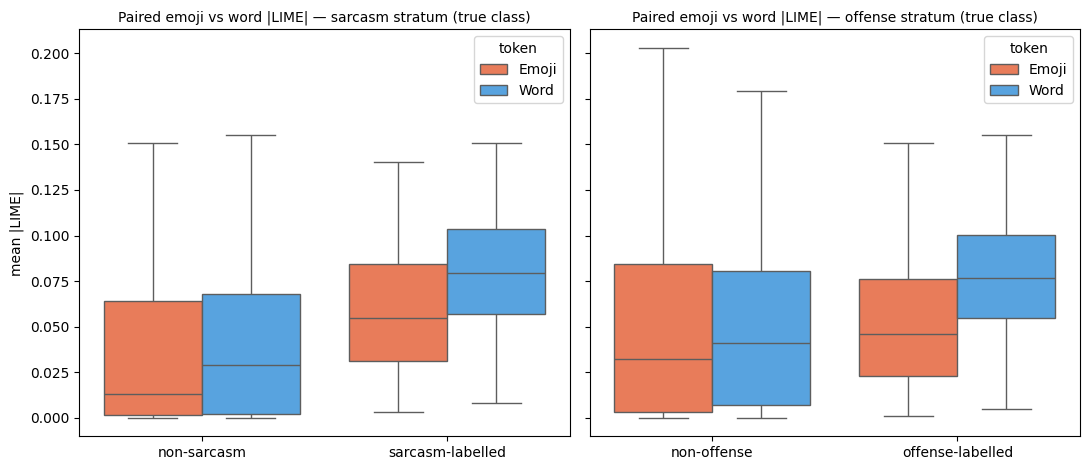

In [27]:
# Section 14c — Class-stratified emoji vs word attribution (Part 1 of the research recommendations)
import seaborn as sns
from scipy.stats import ttest_rel, wilcoxon

if len(emoji_test_idx) == 0:
    print("No emoji-bearing hold-out rows -> Section 14c skipped.")
    CLASS_STRAT = {}
else:
    # Every emoji-bearing hold-out row is explained for its TRUE class (the decision the gold label asks
    # for). Rows whose true class equals the predicted class reuse the Section 14b explanations from
    # LIME_CACHE, so only true/predicted mismatches cost extra LIME runs.
    strat_rows = []
    with lime_models_resident(full_cv["models"]):
        for i in tqdm(emoji_test_idx, desc="LIME[true]", leave=False):
            k = int(y4_test[i])
            exp = lime_explain_cached(i, k)
            em, wd = emoji_word_split(exp, k)
            if not em or not wd:              # keep the comparison strictly paired
                continue
            strat_rows.append({
                "row": int(i), "true_class": CLASS_NAMES[k],
                "sarc_true": int(k in (0, 2)),   # Pure Sarcastic or Sarcastic Offense
                "off_true":  int(k in (1, 2)),   # Pure Offensive or Sarcastic Offense
                "emoji": float(np.mean([abs(w) for _, w in em])),
                "word":  float(np.mean([abs(w) for _, w in wd])),
            })
    S = pd.DataFrame(strat_rows, columns=["row", "true_class", "sarc_true", "off_true", "emoji", "word"])

    def _stratum_test(frame, alt):
        """Paired comparison of mean|w|(emoji) vs mean|w|(word) inside one stratum.
        alt = 'greater' (H1: Δ > 0), 'less' (H1: Δ < 0) or 'two-sided' (descriptive)."""
        out = {"n": len(frame), "emoji_mean": np.nan, "word_mean": np.nan, "mean_diff": np.nan,
               "cohens_d": np.nan, "pct_emoji_gt_word": np.nan, "t": np.nan,
               "p_ttest": np.nan, "p_wilcoxon": np.nan}
        n = len(frame)
        if n == 0:
            return out
        em, wd = frame["emoji"].values, frame["word"].values
        d = em - wd
        out.update(emoji_mean=float(em.mean()), word_mean=float(wd.mean()), mean_diff=float(d.mean()),
                   cohens_d=float(d.mean() / (d.std(ddof=1) + 1e-12)) if n > 1 else np.nan,
                   pct_emoji_gt_word=float(100 * np.mean(d > 0)))
        if n < 3:
            return out
        t, p_t = ttest_rel(em, wd, alternative=alt)
        try:
            _, p_w = wilcoxon(em, wd, alternative=alt)
        except ValueError:                    # all paired differences are zero
            p_w = float("nan")
        out.update(t=float(t), p_ttest=float(p_t), p_wilcoxon=float(p_w))
        return out

    SPEC = [
        ("Sarcastic-labelled (H1: Δ>0)",  S[S["sarc_true"] == 1], "greater"),
        ("Non-sarcastic (descriptive)",   S[S["sarc_true"] == 0], "two-sided"),
        ("Offensive-labelled (H1: Δ<0)",  S[S["off_true"] == 1],  "less"),
        ("Non-offensive (descriptive)",   S[S["off_true"] == 0], "two-sided"),
    ]

    print("=" * 84)
    print("  SECTION 14c — CLASS-STRATIFIED emoji vs word |LIME| (explained class = TRUE class)")
    print("=" * 84)
    print(f"emoji-bearing rows explained: {len(S)} (of {len(emoji_test_idx)})")
    CLASS_STRAT, strat_out = {}, []
    for label, frame, alt in SPEC:
        r = _stratum_test(frame, alt)
        r["stratum"], r["alternative"] = label, alt
        strat_out.append(r); CLASS_STRAT[label] = r
        print(f"\n{label}\n  n={r['n']}  emoji {r['emoji_mean']:.4f} vs word {r['word_mean']:.4f} "
              f"| mean Δ {r['mean_diff']:+.4f} | Cohen's d {r['cohens_d']:+.2f} "
              f"| emoji>word in {r['pct_emoji_gt_word']:.1f}%")
        if alt != "two-sided":
            sig = (np.isfinite(r["p_ttest"]) and r["p_ttest"] < 0.05 and
                   np.isfinite(r["p_wilcoxon"]) and r["p_wilcoxon"] < 0.05)
            print(f"  paired t ({alt})  p={r['p_ttest']:.3e} | Wilcoxon p={r['p_wilcoxon']:.3e} "
                  f"-> {'SUPPORTED' if sig else 'NOT supported'} at α=0.05"
                  + ("  (n<3: test skipped)" if r["n"] < 3 else ""))

    print("\nDescriptive breakdown by TRUE class:")
    per = []
    for k in LABELS4:
        r = _stratum_test(S[S["true_class"] == CLASS_NAMES[k]], "two-sided")
        r["stratum"] = CLASS_NAMES[k]; per.append(r)
    per_df = pd.DataFrame(per)
    print(per_df[["stratum", "n", "emoji_mean", "word_mean", "mean_diff", "pct_emoji_gt_word"]]
          .round(4).to_string(index=False))

    out_df = pd.concat([pd.DataFrame(strat_out), per_df], ignore_index=True)
    out_df.to_csv(os.path.join(CFG["RUN_DIR"], "class_stratified_lime_4way.csv"), index=False)
    print(f"\nSaved -> {os.path.join(CFG['RUN_DIR'], 'class_stratified_lime_4way.csv')}")

    # ---- figure: paired emoji vs word per labelled stratum --------------------------------
    if len(S):
        fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)

        for ax, flag, lab in [(axes[0], "sarc_true", "sarcasm"), (axes[1], "off_true", "offense")]:
            grp = np.where(S[flag].values == 1, f"{lab}-labelled", f"non-{lab}")
            pdf = pd.concat([
                pd.DataFrame({"group": grp, "token": "Emoji", "mean |LIME|": S["emoji"].values}),
                pd.DataFrame({"group": grp, "token": "Word",  "mean |LIME|": S["word"].values})])
            sns.boxplot(data=pdf, x="group", y="mean |LIME|", hue="token",
                        palette={"Emoji": "#ff7043", "Word": "#42a5f5"}, showfliers=False, ax=ax)
            ax.set_title(f"Paired emoji vs word |LIME| — {lab} stratum (true class)", fontsize=10)
            ax.set_xlabel("")
        plt.tight_layout(); plt.savefig("lime_class_stratified_4way.png", dpi=150, bbox_inches="tight"); plt.show()

## Section 14d — Incongruent-Subset Benchmark (Part 2)

Sarcasm in Bangla often uses a surface-positive phrasing whose intent is mocking, and the emojis carry much of that intent. The subset is the set of sarcastic test rows (sarcasm = 1) whose text contains at least one positive-surface trigger word. Triggers are matched as whole words, because a bare substring test would match "বাহ" inside "বাহিনী".

**H₁:** the sarcasm decision of the full model on this subset is better than with emojis removed. The emoji-drop predictions come from Section 13d, so nothing is re-trained.

*Metric choice.* Every row in the subset is truly sarcastic, so a macro-F1 over the two sarcasm classes is degenerate: the negative class has no true rows and contributes an F1 of 0 by convention. The well-defined measures are the sarcasm recall and the positive-class F1, which is a monotone function of recall on this subset. The paired test is McNemar on the sarcasm decisions.

If the lexicon subset has fewer than `CFG["INCONGRUENT_MIN"]` rows, it is expanded with sarcastic rows that contain a positive emoji, so that the pragmatic clash is carried by the emoji alone. The subset rows are saved to `incongruent_subset_rows.csv` for manual audit.

In [28]:
# Section 14d — Incongruent-subset benchmark (Part 2 of the research recommendations)
import re
from scipy.stats import binomtest, chi2 as _chi2dist

# Bangla / code-switched surface-positive triggers (curated from corpus vocabulary)
POSITIVE_SURFACE_TRIGGERS = {
    "বাহ", "অসাধারণ", "চমৎকার", "সুন্দর", "সেরা", "ভালো", "ধন্যবাদ",
    "মাশাআল্লাহ", "প্রশংসনীয়", "উত্তম", "লিজেন্ড", "সুপার", "স্মার্ট",
    "বাহবা", "মুগ্ধ", "মারহাবা",
    "great", "nice", "good", "honest", "wow", "superb", "brilliant",
}
# Positive emojis: used ONLY for the expansion when the lexicon subset is too small
POSITIVE_EMOJI = {"🤩", "👍", "😊", "😍", "🥰", "😘", "😃", "😁", "🙂", "😄", "😇", "🥳", "👏", "💯", "🙏"}

# WHOLE-WORD matching: a bare substring test lets "বাহ" match inside "বাহিনী" or "ভালো" inside
# "ভালোবাসা". Python's \b is unreliable for Bangla (vowel signs are not \w), so word edges are
# defined explicitly as "not a Bangla letter/mark, digit or Latin letter".
_WORD_CH = r"\w\u0980-\u09FF"
_TRIG_RE = re.compile(r"(?<![" + _WORD_CH + r"])(?:" +
                      "|".join(re.escape(w) for w in sorted(POSITIVE_SURFACE_TRIGGERS, key=len, reverse=True)) +
                      r")(?![" + _WORD_CH + r"])", re.IGNORECASE)

def _mcnemar_exact_one_sided(correct_full, correct_alt):
    """Paired McNemar, H1: `correct_full` is better than `correct_alt`.
    Exact binomial for small discordant counts, continuity-corrected chi-square otherwise."""
    b = int(np.sum(correct_full & ~correct_alt))     # full right, alternative wrong
    c = int(np.sum(~correct_full & correct_alt))     # full wrong, alternative right
    n = b + c
    if n == 0:
        return b, c, 1.0
    if n < 25:
        p2 = binomtest(min(b, c), n, 0.5).pvalue
    else:
        p2 = _chi2dist.sf((abs(b - c) - 1) ** 2 / n, 1)
    return b, c, (p2 / 2 if b > c else 1 - p2 / 2)

sarc_true_test = df_test["sarcasm"].values.astype(int)
texts_test     = df_test["text"].values
has_lex        = np.array([bool(_TRIG_RE.search(str(t))) for t in texts_test])
has_pos_emoji  = np.array([any(e in POSITIVE_EMOJI for e in extract_emojis(t)) for t in texts_test])
is_sarc        = sarc_true_test == 1

mask_lex = is_sarc & has_lex
if mask_lex.sum() >= CFG["INCONGRUENT_MIN"]:
    mask, source = mask_lex, "lexicon"
else:
    mask   = is_sarc & (has_lex | has_pos_emoji)
    source = "EXPANDED: lexicon OR positive emoji (lexicon subset below INCONGRUENT_MIN)"
idx_inc = np.where(mask)[0]

print("=" * 84)
print("  SECTION 14d — INCONGRUENT SUBSET BENCHMARK (sarcasm, surface-positive wording)")
print("=" * 84)
print(f"Sarcastic test rows            : {int(is_sarc.sum())}")
print(f"  with a positive-surface word : {int(mask_lex.sum())}   (lexicon hits)")
print(f"Incongruent subset used        : {len(idx_inc)} / {len(df_test)} test rows "
      f"({100*len(idx_inc)/len(df_test):.1f}%)  | source: {source}")

INCONG_RESULTS = {}
if len(idx_inc) < 5:
    print("WARNING: fewer than 5 incongruent rows -> benchmark skipped.")
else:
    if len(idx_inc) < 10:
        print("WARNING: fewer than 10 rows -> underpowered; read the result as indicative only.")

    # Predictions already produced by Section 13d / 13 — no retraining.
    # Sarcasm decision = the sarcasm view implied by the 4-way prediction (classes 0 and 2).
    sarc_full = np.isin(yp4_test, [0, 2]).astype(int)
    sarc_drop = np.isin(rob_preds["emoji_drop"], [0, 2]).astype(int)

    y_sub    = sarc_true_test[idx_inc]                       # all ones by construction
    full_sub = sarc_full[idx_inc]
    drop_sub = sarc_drop[idx_inc]

    # A subset whose true labels are all POSITIVE makes binary macro-F1 degenerate (the negative
    # class is absent, so its F1 is 0 by convention). The well-defined quantities are the
    # positive-class F1 and the sarcasm recall; with no negatives, F1 = 2R/(1+R), a monotone
    # function of recall, so the two rank models identically. The paired test is McNemar.
    rec_full = float(full_sub.mean()); rec_drop = float(drop_sub.mean())
    f1_full  = f1_score(y_sub, full_sub, zero_division=0)
    f1_drop  = f1_score(y_sub, drop_sub, zero_division=0)
    acc4_full = float((yp4_test[idx_inc] == y4_test[idx_inc]).mean())
    acc4_drop = float((rob_preds["emoji_drop"][idx_inc] == y4_test[idx_inc]).mean())
    b, c, p_mc = _mcnemar_exact_one_sided(full_sub == 1, drop_sub == 1)

    # context: the aggregate (whole test set) sarcasm macro-F1 under emoji drop
    agg_full = f1_score(sarc_true_test, sarc_full, average="macro", zero_division=0)
    agg_drop = f1_score(sarc_true_test, sarc_drop, average="macro", zero_division=0)

    print(f"\nSarcasm decision on the incongruent subset:")
    print(f"  {'':<26}{'Full (emoji kept)':>20}{'Emoji dropped':>18}{'Δ':>10}")
    print(f"  {'sarcasm recall (= F1 here)':<26}{rec_full:>20.4f}{rec_drop:>18.4f}{rec_full-rec_drop:>+10.4f}")
    print(f"  {'sarcasm F1 (positive)':<26}{f1_full:>20.4f}{f1_drop:>18.4f}{f1_full-f1_drop:>+10.4f}")
    print(f"  {'4-way accuracy':<26}{acc4_full:>20.4f}{acc4_drop:>18.4f}{acc4_full-acc4_drop:>+10.4f}")
    print(f"\n  McNemar H1 (full > emoji-dropped), one-sided: full-only={b}, drop-only={c}, p={p_mc:.4e}")
    print(f"  Verdict @ α=0.05: {'SUPPORTED' if (p_mc < 0.05 and rec_full > rec_drop) else 'NOT supported'}")
    print(f"\nContext — whole test set, sarcasm macro-F1: full {agg_full:.4f} vs emoji-dropped {agg_drop:.4f} "
          f"(Δ {agg_full-agg_drop:+.4f})")
    print("A large gap on the incongruent subset next to a small aggregate gap is the pattern the "
          "recommendation predicts: easy rows dilute the aggregate.")

    INCONG_RESULTS = {"n": len(idx_inc), "source": source, "recall_full": rec_full, "recall_drop": rec_drop,
                      "acc4_full": acc4_full, "acc4_drop": acc4_drop, "mcnemar_b": b, "mcnemar_c": c,
                      "p_mcnemar_one_sided": p_mc, "agg_macroF1_full": agg_full, "agg_macroF1_drop": agg_drop}
    pd.DataFrame([INCONG_RESULTS]).to_csv(os.path.join(CFG["RUN_DIR"], "incongruent_benchmark_4way.csv"), index=False)
    pd.DataFrame({"text": texts_test[idx_inc], "true_label": [CLASS_NAMES[k] for k in y4_test[idx_inc]],
                  "pred_full": [CLASS_NAMES[k] for k in yp4_test[idx_inc]],
                  "pred_emoji_dropped": [CLASS_NAMES[k] for k in rob_preds["emoji_drop"][idx_inc]]}
                 ).to_csv(os.path.join(CFG["RUN_DIR"], "incongruent_subset_rows.csv"), index=False)
    print(f"Saved -> {CFG['RUN_DIR']}/incongruent_benchmark_4way.csv and incongruent_subset_rows.csv")

  SECTION 14d — INCONGRUENT SUBSET BENCHMARK (sarcasm, surface-positive wording)
Sarcastic test rows            : 233
  with a positive-surface word : 127   (lexicon hits)
Incongruent subset used        : 127 / 495 test rows (25.7%)  | source: lexicon

Sarcasm decision on the incongruent subset:
                               Full (emoji kept)     Emoji dropped         Δ
  sarcasm recall (= F1 here)              0.9843            0.9843   +0.0000
  sarcasm F1 (positive)                   0.9921            0.9921   +0.0000
  4-way accuracy                          0.9606            0.9606   +0.0000

  McNemar H1 (full > emoji-dropped), one-sided: full-only=0, drop-only=0, p=1.0000e+00
  Verdict @ α=0.05: NOT supported

Context — whole test set, sarcasm macro-F1: full 0.9655 vs emoji-dropped 0.9613 (Δ +0.0042)
A large gap on the incongruent subset next to a small aggregate gap is the pattern the recommendation predicts: easy rows dilute the aggregate.
Saved -> /kaggle/working/runs/incong

## Section 15 — Robust Inference (`predict_text`) + Interactive Prompt

A single reusable `predict_text` with full **input validation and error handling** (empty, over-long, non-Bangla, emoji-only, tokenizer/model failure) that returns a status field instead of raising. The interactive prompt is **enabled by default** and guarded so "Run all" in a non-interactive kernel skips it cleanly.

"Is it deployment-ready?"* Malformed input degrades gracefully to a labelled warning/error rather than crashing the pipeline.

In [29]:
BANGLA_RANGE = range(0x0980, 0x0A00)   # Bengali Unicode block
def _has_bangla(t): return any(ord(ch) in BANGLA_RANGE for ch in str(t))

CLASS_ICONS = ["😏", "😡", "⚠️", "✅"]     # same order as CLASS_NAMES

def predict_text(raw_text, models=None, encoder=None, max_chars=2000):
    """Robust single-text 4-way inference. Returns a dict; bad input yields an error field, never raises."""
    models  = full_cv["models"] if models is None else models
    encoder = explain_encoder   if encoder is None else encoder
    try:
        if raw_text is None or not str(raw_text).strip():
            return {"error": "empty_input", "label": "⛔ EMPTY INPUT", "probs": None}
        raw_text = str(raw_text); warning = None
        if len(raw_text) > max_chars:
            raw_text = raw_text[:max_chars]; warning = f"truncated_to_{max_chars}_chars"
        if not _has_bangla(raw_text):
            warning = (warning + "; " if warning else "") + "no_bangla_characters_detected"

        exp   = preprocess(raw_text)
        feats = torch.tensor(encoder.transform([raw_text]), dtype=torch.float32)
        enc   = tokenizer(exp, max_length=CFG["MAX_LEN"], padding="max_length",
                          truncation=True, return_tensors="pt")
        P = np.zeros(N_CLASSES)
        for m in models:
            m.to(DEVICE).eval()
            with torch.no_grad():
                c, _, _ = m(enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE), feats.to(DEVICE))
            P += torch.softmax(c, dim=1).squeeze(0).cpu().numpy()
            m.to("cpu")
        P /= len(models)
    except Exception as e:
        return {"error": f"{type(e).__name__}: {e}", "label": "⛔ INFERENCE ERROR", "probs": None}

    k = int(P.argmax())
    out = {"raw": raw_text, "expanded": exp, "emojis": extract_emojis(raw_text),
           "pred_class": CLASS_NAMES[k],
           "label": f"{CLASS_ICONS[k]} {CLASS_NAMES[k].upper()}",
           "probs": {n: round(float(p), 4) for n, p in zip(CLASS_NAMES, P)}}
    if warning: out["warning"] = warning
    return out

# smoke tests, incl. edge cases (empty / non-Bangla / emoji-only)
for t in ["সে অনেক ভদ্র 🤣", "তুমি একটা গাধা 😡",
          "করিম এর বুদ্ধি প্রশংসনীয় 🤣 😡", "আজকের আবহাওয়া সুন্দর।",
          "", "hello world 🙂", "🤣🤣🤣"]:
    r = predict_text(t)
    tag = r.get("error") or r.get("warning") or ""
    print(f"{r['label']:<34} {str(r.get('probs'))} | {t!r} {('[' + tag + ']') if tag else ''}")


✅ NEUTRAL                          {'Pure Sarcastic': 0.3714, 'Pure Offensive': 0.0124, 'Sarcastic Offense': 0.0107, 'Neutral': 0.6055} | 'সে অনেক ভদ্র 🤣' 
😡 PURE OFFENSIVE                   {'Pure Sarcastic': 0.0047, 'Pure Offensive': 0.9783, 'Sarcastic Offense': 0.0086, 'Neutral': 0.0084} | 'তুমি একটা গাধা 😡' 
😏 PURE SARCASTIC                   {'Pure Sarcastic': 0.7263, 'Pure Offensive': 0.0069, 'Sarcastic Offense': 0.2546, 'Neutral': 0.0122} | 'করিম এর বুদ্ধি প্রশংসনীয় 🤣 😡' 
✅ NEUTRAL                          {'Pure Sarcastic': 0.0063, 'Pure Offensive': 0.007, 'Sarcastic Offense': 0.0056, 'Neutral': 0.9812} | 'আজকের আবহাওয়া সুন্দর।' 
⛔ EMPTY INPUT                      None | '' [empty_input]
✅ NEUTRAL                          {'Pure Sarcastic': 0.2148, 'Pure Offensive': 0.0084, 'Sarcastic Offense': 0.0071, 'Neutral': 0.7698} | 'hello world 🙂' [no_bangla_characters_detected]
✅ NEUTRAL                          {'Pure Sarcastic': 0.4039, 'Pure Offensive': 0.0187, 'Sarcastic Offense'

In [30]:
# Interactive inference — ENABLED by default. Non-interactive runs skip the prompt cleanly.
import sys
CFG.setdefault("ENABLE_INTERACTIVE", True)
ENABLE_INTERACTIVE = CFG["ENABLE_INTERACTIVE"]
if ENABLE_INTERACTIVE:
    interactive_ok = hasattr(sys, "stdin") and sys.stdin is not None and sys.stdin.isatty()
    if not interactive_ok:
        print("Interactive prompt is ENABLED but stdin is non-interactive "
              "(e.g. 'Run all' / batch). Skipping the prompt; call predict_text('...') directly.")
    else:
        try:
            txt = input("Enter Bangla text (with/without emojis), or press Enter to skip: ").strip()
            if txt:
                r = predict_text(txt)
                print(r["label"], "| probs:", r.get("probs"),
                      ("| ⚠ " + r["warning"]) if r.get("warning") else "")
        except (EOFError, KeyboardInterrupt):
            print("No interactive input available — skipped.")


Interactive prompt is ENABLED but stdin is non-interactive (e.g. 'Run all' / batch). Skipping the prompt; call predict_text('...') directly.


## Section 16 — Task Relationship & Controlled Ablations

We quantify the sarcasm–offensive relationship (χ², φ) between the two binary views derived from the four-way label, on the TRAIN/CV pool only. The values are computed and printed below; the computed association decides whether dependence is an argument for joint modelling. Joint modelling in any case rests on the shared four-way target.

A **minimal** two-ablation ladder isolates the two core claims: **(A0) no-emoji** (emojis removed from the text pipeline) shows that emojis matter, and **(A1) no-cross-stitch** (intent vector kept, independent heads) shows that soft sharing matters. Both are trained on the identical fold indices, seed, hyper-parameters and epoch budget as the reference run, and their hold-out predictions are retained for the fold-level paired *t*-tests and the sample-level McNemar tests (Section 19). The gated-fusion variant is compared in Section 16b.

In [31]:
from scipy.stats import chi2_contingency

# Descriptive association on the TRAIN/CV pool only (the hold-out test set is never used for this)
phi = matthews_corrcoef(df_trainval["sarcasm"], df_trainval["offensive"])     # = phi for binary views
chi2, pval, dof, _ = chi2_contingency(pd.crosstab(df_trainval["sarcasm"], df_trainval["offensive"]))
p_off_given_sarc  = df_trainval[df_trainval["sarcasm"] == 1]["offensive"].mean()
p_off_given_nsarc = df_trainval[df_trainval["sarcasm"] == 0]["offensive"].mean()
direction = "NEGATIVE" if phi < 0 else "POSITIVE"
dependent = pval < 0.05

print("=== TASK RELATIONSHIP (derived sarcasm / offensive views, TRAIN/CV pool) ===")
print(f"P(Offensive | Sarcastic)     = {p_off_given_sarc:.3f}")
print(f"P(Offensive | Non-sarcastic) = {p_off_given_nsarc:.3f}")
print(f"Phi (φ via MCC)              = {phi:+.4f}   [{direction} association]")
print(f"Chi-square test              = {chi2:.2f} (p = {pval:.2e}, dof={dof})")
print(f"→ Association is statistically significant (p<0.05): {'YES' if dependent else 'NO'}.")
if dependent:
    print(f"\nInterpretation: sarcasm and offensiveness are DEPENDENT ({direction}, φ={phi:+.3f}),")
    print("which supports modelling them jointly (the cross-stitch layer can exploit the shared structure).")
else:
    print(f"\nInterpretation: no significant sarcasm–offensive association (φ={phi:+.3f}, p={pval:.2g}).")
    print("The case for joint modelling therefore rests on the shared 4-way target, not on dependence.")
TASKREL = {"phi": phi, "chi2": chi2, "p": pval, "dof": dof}

=== TASK RELATIONSHIP (derived sarcasm / offensive views, TRAIN/CV pool) ===
P(Offensive | Sarcastic)     = 0.515
P(Offensive | Non-sarcastic) = 0.486
Phi (φ via MCC)              = +0.0288   [POSITIVE association]
Chi-square test              = 1.12 (p = 2.89e-01, dof=1)
→ Association is statistically significant (p<0.05): NO.

Interpretation: no significant sarcasm–offensive association (φ=+0.029, p=0.29).
The case for joint modelling therefore rests on the shared 4-way target, not on dependence.


In [32]:
# Section 16 — Controlled ablations (4-way). Identical folds, seed and budget as the reference run.
import gc
from scipy.stats import ttest_rel, wilcoxon

# Prerequisites: the reference run in memory, or restored from its STATE-DICT checkpoint.
# Restoring rebuilds the models from this notebook's class definitions, so there is no
# pickled `__main__` lookup and no AttributeError on reload.
if "full_cv" not in globals():
    REF_CHECKPOINT = os.path.join(CFG["RUN_DIR"], f"ref_run_4cls_seed{CFG['ABLATION_SEED']}.pt")
    if not os.path.exists(REF_CHECKPOINT):
        raise FileNotFoundError("Run Sections 12-13 first (no reference run in memory or on disk).")
    full_cv = load_cv_checkpoint(REF_CHECKPOINT)
if "BEST_HP" not in globals():
    BEST_HP = full_cv["best_hp"]

abl_splits = 2 if CFG["QUICK_SMOKE_TEST"] else CFG["N_SPLITS"]
abl_folds  = full_cv["fold_indices"] if not CFG["QUICK_SMOKE_TEST"] else \
             make_fold_indices(df_trainval, joint_trainval, CFG["ABLATION_SEED"], abl_splits)

class Ablation_TextOnly(nn.Module):
    """A0: text encoder only, independent heads. Fed emoji-STRIPPED text, so it sees NO emoji signal."""
    def __init__(self, BanglaBERT=None, shared_dim=512, task_dim=256, dropout=0.3, **_):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(BanglaBERT or CFG["MODEL_NAME"])
        h = self.encoder.config.hidden_size
        self.shared   = nn.Sequential(nn.Linear(h, shared_dim), nn.LayerNorm(shared_dim),
                                      nn.ReLU(), nn.Dropout(dropout))
        self.cls_head = nn.Linear(shared_dim, N_CLASSES)
        self.sp = nn.Linear(shared_dim, 1); self.op = nn.Linear(shared_dim, 1)
    def encode_fused(self, ids, msk, emo):
        return self.shared(self.encoder(input_ids=ids, attention_mask=msk).last_hidden_state[:, 0, :])
    def forward(self, ids, msk, emo, return_fused=False):
        f = self.encode_fused(ids, msk, emo)
        out = (self.cls_head(f), self.sp(f).squeeze(-1), self.op(f).squeeze(-1))
        return (out + (f,)) if return_fused else out

class Ablation_NoStitch(nn.Module):
    """A1: full emoji-intent model but NO cross-stitch: independent sarcasm/offense branches feed
    the same 4-way head. Isolates the value of cross-stitch soft-sharing."""
    def __init__(self, BanglaBERT=None, emo_dim=10, shared_dim=512, task_dim=256, dropout=0.3, **_):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(BanglaBERT or CFG["MODEL_NAME"])
        h = self.encoder.config.hidden_size
        self.emo_mlp = EmoIntentMLP(emo_dim, 64, 32)
        self.shared  = nn.Sequential(nn.Linear(h + 32, shared_dim), nn.LayerNorm(shared_dim),
                                     nn.ReLU(), nn.Dropout(dropout))
        self.sproj = nn.Sequential(nn.Linear(shared_dim, task_dim), nn.ReLU())
        self.oproj = nn.Sequential(nn.Linear(shared_dim, task_dim), nn.ReLU())
        self.cls_head = nn.Linear(2 * task_dim, N_CLASSES)
        self.sp = nn.Linear(task_dim, 1); self.op = nn.Linear(task_dim, 1)
    def encode_fused(self, ids, msk, emo):
        cls = self.encoder(input_ids=ids, attention_mask=msk).last_hidden_state[:, 0, :]
        return self.shared(torch.cat([cls, self.emo_mlp(emo)], 1))
    def forward(self, ids, msk, emo, return_fused=False):
        f = self.encode_fused(ids, msk, emo)
        hs, ho = self.sproj(f), self.oproj(f)
        out = (self.cls_head(torch.cat([hs, ho], 1)), self.sp(hs).squeeze(-1), self.op(ho).squeeze(-1))
        return (out + (f,)) if return_fused else out

def build_textonly(hp): return Ablation_TextOnly(**hp).to(DEVICE)
def build_nostitch(hp): return Ablation_NoStitch(**hp).to(DEVICE)

ABLATIONS = {
    "A0 No-emoji (text only)":     dict(builder=build_textonly, use_supcon=True, pp=preprocess_noemoji),
    "A1 +Intent, no cross-stitch": dict(builder=build_nostitch, use_supcon=True, pp=preprocess),
}
abl_results = {}
for name, spec in ABLATIONS.items():
    print(f"\n--- Running {name} ---")
    seed_everything(CFG["ABLATION_SEED"])
    cv = run_cv(df_trainval, joint_trainval, BEST_HP, spec["builder"],
                use_supcon=spec["use_supcon"], n_splits=abl_splits, verbose=False,
                tag=name.split()[0], seed=CFG["ABLATION_SEED"], fold_indices=abl_folds,
                preprocess_fn=spec["pp"])
    P = ensemble_predict(cv["models"], cv["encoders"], df_test.text.values, preprocess_fn=spec["pp"])
    abl_results[name] = {"metrics": cv["metrics"], "P4": P, "yp4": P.argmax(1),
                         "fold_macro": cv["metrics"]["macro_f1"].values}
    del cv; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

full_fold_macro = full_cv["metrics"]["macro_f1"].values
ladder = {k: abl_results[k]["fold_macro"].mean() for k in ABLATIONS}
ladder["Full (Intent+Cross-stitch+SupCon, 4-way)"] = full_fold_macro.mean()

print("\n=== CONTROLLED ABLATION (identical folds & budget, CV macro-F1, 4-way) ===")
for k, v in ladder.items():
    print(f"  {k:<40} macro-F1 = {v:.4f}")

print("\n=== PAIRED t-TEST + WILCOXON across folds (Full > Ablation), one-sided ===")
print(f"CAVEAT: n={abl_splits} paired fold values -> low statistical power. A non-significant result\n"
      f"means 'underpowered', not 'no effect'; read it alongside the sample-level McNemar test in Section 19.")
for name in ABLATIONS:
    fm = abl_results[name]["fold_macro"]
    t, p2 = ttest_rel(full_fold_macro, fm)
    p1 = p2/2 if t > 0 else 1 - p2/2
    try:
        _, wp2 = wilcoxon(full_fold_macro, fm, alternative="two-sided")
        wp1 = wp2/2 if np.median(full_fold_macro - fm) > 0 else 1 - wp2/2
    except ValueError:
        wp1 = float("nan")
    print(f"  Full vs {name:<30} Δ={full_fold_macro.mean()-fm.mean():+.4f} "
          f"| t-test p={p1:.4f} | Wilcoxon p={wp1:.4f}  (n={abl_splits})")
print("\n(Sample-level McNemar tests Full > Ablation are in Section 19.)")



--- Running A0 No-emoji (text only) ---

--- Running A1 +Intent, no cross-stitch ---

=== CONTROLLED ABLATION (identical folds & budget, CV macro-F1, 4-way) ===
  A0 No-emoji (text only)                  macro-F1 = 0.9144
  A1 +Intent, no cross-stitch              macro-F1 = 0.9203
  Full (Intent+Cross-stitch+SupCon, 4-way) macro-F1 = 0.9276

=== PAIRED t-TEST + WILCOXON across folds (Full > Ablation), one-sided ===
CAVEAT: n=5 paired fold values -> low statistical power. A non-significant result
means 'underpowered', not 'no effect'; read it alongside the sample-level McNemar test in Section 19.
  Full vs A0 No-emoji (text only)        Δ=+0.0132 | t-test p=0.1364 | Wilcoxon p=0.1562  (n=5)
  Full vs A1 +Intent, no cross-stitch    Δ=+0.0073 | t-test p=0.1154 | Wilcoxon p=0.1562  (n=5)

(Sample-level McNemar tests Full > Ablation are in Section 19.)


## Section 16b — Gated Fusion and Repeated Seeds

**Gated fusion.** The concatenation model gives the 768 text dimensions and the 32 intent dimensions the same route into the shared layer, so the gradient is dominated by the text path. `MultimodalGatedFusion` learns a per-dimension convex combination h_F = g ⊙ h_T + (1 − g) ⊙ h_E, followed by a residual refinement. Everything downstream of the fusion is identical to the reference model, so the comparison isolates the fusion mechanism.

* **H₁ (accuracy):** macro-F1(gated) > macro-F1(concat), tested with a one-sided paired fold test and a one-sided McNemar test on the TEST sheet.
* **H₁_gate (interpretability):** the emoji weight ω = 1 − g correlates positively with the number of emojis in a sentence.

*Correction carried into this revision:* the recommendation's gate sub-hypothesis read g as the emoji weight. Because h_F = g ⊙ h_T + (1 − g) ⊙ h_E, g is the **text** weight, so the test below is run on ω = 1 − g. Unit tests check shapes, the gate range, gradient flow into the emoji branch and compatibility with `ensemble_predict`.

**Repeated seeds.** The extra seeds in `CFG["MULTI_SEEDS"]` re-draw the folds and re-train the reference model with the same hyper-parameters, and report mean ± SD across seeds. Set `MULTI_SEEDS = []` to skip this block. It is the most expensive part of the notebook.

In [33]:
# Section 16b — Gated multimodal fusion (Part 3): model definitions + unit tests
import gc

class MultimodalGatedFusion(nn.Module):
    """Dynamic gated fusion between the BanglaBERT [CLS] vector and the emoji-intent vector.
    Replaces the naive concatenation that gave the 10-d intent branch a tiny share of the gradient.

      h_E   = LayerNorm(Linear(128->d)(ReLU(Linear(10->128)(x_E))))         intent in text space
      g     = sigmoid(Linear(H->d)(ReLU(Linear(2d->H)([h_T ; h_E]))))        gate in [0,1]^d
      h_F   = g * h_T + (1 - g) * h_E                                         convex combination
      out   = LayerNorm(h_F + Refinement(h_F))                                residual refinement
    NOTE: g weights the TEXT path. The emoji weight is therefore (1 - g); that is the quantity the
    gate analysis in Section 16b tests."""
    def __init__(self, text_dim=768, intent_in_dim=10, gate_hidden=256, dropout=0.1):
        super().__init__()
        self.intent_proj = nn.Sequential(
            nn.Linear(intent_in_dim, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, text_dim), nn.LayerNorm(text_dim))
        self.gate_net = nn.Sequential(
            nn.Linear(2 * text_dim, gate_hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(gate_hidden, text_dim), nn.Sigmoid())
        self.refinement = nn.Sequential(
            nn.Linear(text_dim, gate_hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(gate_hidden, text_dim))
        self.norm = nn.LayerNorm(text_dim)

    def forward(self, h_text, x_intent):
        h_emoji = self.intent_proj(x_intent)                                  # [B, d]
        gate    = self.gate_net(torch.cat([h_text, h_emoji], dim=-1))         # [B, d]
        h_fused = gate * h_text + (1.0 - gate) * h_emoji                      # [B, d]
        out     = self.norm(h_fused + self.refinement(h_fused))               # [B, d]
        return out, gate


class EmoMTL_BanglaBERT_Gated(nn.Module):
    """EmoMTL_BanglaBERT with the GATED fusion in place of concatenation. Everything downstream of the
    fusion (shared projection, task projections, cross-stitch, 4-way head, auxiliary heads) is the same
    architecture, so the comparison isolates the fusion mechanism. Same forward() contract as
    EmoMTL_BanglaBERT, so run_cv / ensemble_predict work unchanged."""
    def __init__(self, BanglaBERT=CFG["MODEL_NAME"], emo_dim=10,
                 shared_dim=512, task_dim=256, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(BanglaBERT)
        h = self.encoder.config.hidden_size
        self.gated_fusion = MultimodalGatedFusion(text_dim=h, intent_in_dim=emo_dim,
                                                  gate_hidden=CFG["GATE_HIDDEN"], dropout=0.1)
        self.shared = nn.Sequential(nn.Linear(h, shared_dim), nn.LayerNorm(shared_dim),
                                    nn.ReLU(), nn.Dropout(dropout))
        self.sarc_proj = nn.Sequential(nn.Linear(shared_dim, task_dim), nn.LayerNorm(task_dim),
                                       nn.ReLU(), nn.Dropout(dropout))
        self.off_proj = nn.Sequential(nn.Linear(shared_dim, task_dim), nn.LayerNorm(task_dim),
                                      nn.ReLU(), nn.Dropout(dropout))
        self.cross_stitch = CrossStitchUnit()
        self.cls_head  = nn.Linear(2 * task_dim, N_CLASSES)
        self.sarc_head = nn.Linear(task_dim, 1)
        self.off_head  = nn.Linear(task_dim, 1)

    def _cls(self, input_ids, attention_mask):
        return self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0, :]

    def encode_fused(self, input_ids, attention_mask, emoji_features):
        fused, _ = self.gated_fusion(self._cls(input_ids, attention_mask), emoji_features)
        return self.shared(fused)                                             # [B, shared_dim]

    def gate_values(self, input_ids, attention_mask, emoji_features):
        """Gate g in [0,1]^h per row (g = TEXT weight; emoji weight = 1 - g)."""
        _, gate = self.gated_fusion(self._cls(input_ids, attention_mask), emoji_features)
        return gate

    def forward(self, input_ids, attention_mask, emoji_features, return_fused=False):
        fused = self.encode_fused(input_ids, attention_mask, emoji_features)
        h_s, h_o = self.cross_stitch(self.sarc_proj(fused), self.off_proj(fused))
        c = self.cls_head(torch.cat([h_s, h_o], dim=1))
        s = self.sarc_head(h_s).squeeze(-1)
        o = self.off_head(h_o).squeeze(-1)
        return (c, s, o, fused) if return_fused else (c, s, o)

def build_gated(hp):
    return EmoMTL_BanglaBERT_Gated(shared_dim=hp["shared_dim"], task_dim=hp["task_dim"],
                                   dropout=hp["dropout"]).to(DEVICE)

# ---- unit tests on a real batch: fail loudly on shape / range / gradient problems ----------------
_t_texts = list(df_trainval["text"].values[:4])
_t_enc   = tokenizer([preprocess(t) for t in _t_texts], max_length=CFG["MAX_LEN"],
                     padding="max_length", truncation=True, return_tensors="pt")
_t_feat  = torch.tensor(explain_encoder.transform(_t_texts), dtype=torch.float32).to(DEVICE)
_t_ids, _t_msk = _t_enc["input_ids"].to(DEVICE), _t_enc["attention_mask"].to(DEVICE)

_mg = MultimodalGatedFusion(text_dim=32, intent_in_dim=10, gate_hidden=16).to(DEVICE)
_o, _g = _mg(torch.randn(4, 32, device=DEVICE), torch.randn(4, 10, device=DEVICE))
assert _o.shape == (4, 32) and _g.shape == (4, 32), "MultimodalGatedFusion shape mismatch"
assert float(_g.min()) >= 0.0 and float(_g.max()) <= 1.0, "gate outside [0, 1]"

_t_model = build_gated(BEST_HP)
c_, s_, o_, f_ = _t_model(_t_ids, _t_msk, _t_feat, return_fused=True)
assert c_.shape == (4, N_CLASSES) and s_.shape == (4,) and o_.shape == (4,)
assert f_.shape == (4, BEST_HP["shared_dim"])
g_ = _t_model.gate_values(_t_ids, _t_msk, _t_feat)
assert g_.shape == (4, _t_model.encoder.config.hidden_size)
assert float(g_.min()) >= 0.0 and float(g_.max()) <= 1.0
(c_.sum() + s_.sum() + o_.sum()).backward()
_gw = _t_model.gated_fusion.intent_proj[0].weight.grad
assert _gw is not None and float(_gw.abs().sum()) > 0, "no gradient reaches the emoji-intent branch"
_P_chk = ensemble_predict([_t_model.cpu()], [explain_encoder], _t_texts)
assert _P_chk.shape == (4, N_CLASSES) and np.allclose(_P_chk.sum(1), 1.0, atol=1e-5)
print("MultimodalGatedFusion unit tests PASSED: shapes, gate in [0,1], gradient reaches the "
      "emoji-intent branch, ensemble_predict compatible.")
del _t_model, _mg; gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

MultimodalGatedFusion unit tests PASSED: shapes, gate in [0,1], gradient reaches the emoji-intent branch, ensemble_predict compatible.


[EmoMTL-GATED-4way] s42 F1 E1:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-GATED-4way] s42 F1 E01 | trL 2.950 | monitor macF1 0.655 (ES) | fold-val macF1 0.634 acc 0.645
      per-class F1 (fold-val): PureSarc 0.697 | PureOff 0.624 | SarcOff 0.449 | Neutral 0.766


[EmoMTL-GATED-4way] s42 F1 E2:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-GATED-4way] s42 F1 E02 | trL 2.030 | monitor macF1 0.875 (ES) | fold-val macF1 0.887 acc 0.886
      per-class F1 (fold-val): PureSarc 0.852 | PureOff 0.922 | SarcOff 0.874 | Neutral 0.901


[EmoMTL-GATED-4way] s42 F1 E3:   0%|          | 0/135 [00:00<?, ?it/s]

...

  [EmoMTL-GATED-4way] s42 F5 E09 | trL 0.232 | monitor macF1 0.941 (ES) | fold-val macF1 0.940 acc 0.940
      per-class F1 (fold-val): PureSarc 0.931 | PureOff 0.961 | SarcOff 0.928 | Neutral 0.940


[EmoMTL-GATED-4way] s42 F5 E10:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-GATED-4way] s42 F5 E10 | trL 0.216 | monitor macF1 0.941 (ES) | fold-val macF1 0.936 acc 0.936
      per-class F1 (fold-val): PureSarc 0.924 | PureOff 0.961 | SarcOff 0.921 | Neutral 0.940


[EmoMTL-GATED-4way] s42 F5 E11:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-GATED-4way] s42 F5 E11 | trL 0.204 | monitor macF1 0.950 (ES) | fold-val macF1 0.933 acc 0.933
      per-class F1 (fold-val): PureSarc 0.924 | PureOff 0.954 | SarcOff 0.921 | Neutral 0.933
  early stop @E11 (on inner monitor split)
  ── Fold 5 per-class report (held-out fold-val, best checkpoint) ──
                   precision    recall  f1-score   support

   Pure Sarcastic     0.8816    0.9306    0.9054        72
   Pure Offensive     0.9342    0.9726    0.9530        73
Sarcastic Offense     0.9306    0.8701    0.8993        77
          Neutral     0.9333    0.9091    0.9211        77

         accuracy                         0.9197       299
        macro avg     0.9199    0.9206    0.9197       299
     weighted avg     0.9204    0.9197    0.9195       299

  ✅ Fold 5 macro-F1 = 0.9197

  SECTION 16b — GATED FUSION vs CONCATENATION (identical folds, seed, budget)
             model  CV macro-F1 (mean)  CV macro-F1 (std)  TEST acc  TEST macro-F1  TEST MCC  TEST macro O

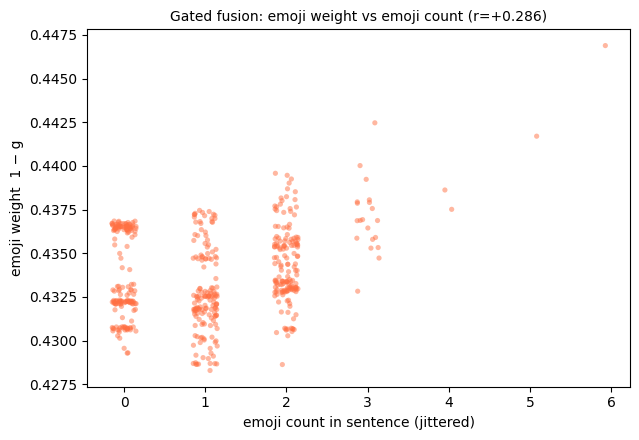

In [34]:
# Section 16b — Gated vs concatenation fusion: same folds, seed, budget and heads (Part 3)
import gc
from scipy.stats import ttest_rel, wilcoxon, pearsonr, mannwhitneyu
from sklearn.metrics import matthews_corrcoef

GATED_RESULTS = {}
if not CFG["RUN_GATED"]:
    print("RUN_GATED = False -> gated-fusion comparison skipped.")
else:
    seed_everything(REF_SEED)
    gated_cv = run_cv(df_trainval, joint_trainval, BEST_HP, model_builder=build_gated,
                      use_supcon=True, verbose=True, tag="EmoMTL-GATED-4way", seed=REF_SEED,
                      fold_indices=full_cv["fold_indices"])
    gated_P  = ensemble_predict(gated_cv["models"], gated_cv["encoders"], df_test["text"].values)
    gated_yp = gated_P.argmax(1)

    # ---- 1. paired comparison on IDENTICAL folds (H1: gated > concatenation) -------------------
    f_concat = full_cv["metrics"]["macro_f1"].values
    f_gated  = gated_cv["metrics"]["macro_f1"].values
    t_f, p_f = ttest_rel(f_gated, f_concat, alternative="greater")      # one-sided
    try:
        _, p_fw = wilcoxon(f_gated, f_concat, alternative="greater")
    except ValueError:
        p_fw = float("nan")

    # ---- 2. sample-level McNemar on the TEST set (H1: gated > concatenation) ----------------------
    cf_concat = (yp4_test == y4_test); cf_gated = (gated_yp == y4_test)
    b_mc, c_mc, p_mc = _mcnemar_exact_one_sided(cf_gated, cf_concat)

    def _row(name, yp, P, cv_f):
        return {"model": name,
                "CV macro-F1 (mean)": float(np.mean(cv_f)), "CV macro-F1 (std)": float(pd.Series(cv_f).std()),
                "TEST acc": accuracy_score(y4_test, yp),
                "TEST macro-F1": f1_score(y4_test, yp, average="macro", labels=LABELS4, zero_division=0),
                "TEST MCC": matthews_corrcoef(y4_test, yp),
                "TEST macro OvR-AUC": _safe_auc_ovr(y4_test, P)}
    cmp_df = pd.DataFrame([_row("concat (reference)", yp4_test, P4_test, f_concat),
                           _row("gated fusion", gated_yp, gated_P, f_gated)])
    print("=" * 84); print("  SECTION 16b — GATED FUSION vs CONCATENATION (identical folds, seed, budget)"); print("=" * 84)
    print(cmp_df.round(4).to_string(index=False))
    print(f"\nPaired fold test  (gated > concat, n={len(f_concat)} folds): t={t_f:+.3f}, "
          f"p(one-sided)={p_f:.4f}")
    print(f"  Wilcoxon p(one-sided) = {p_fw:.4f}")
    print(f"McNemar on TEST (gated > concat, 4-way correctness): gated-only={b_mc}, concat-only={c_mc}, "
          f"p(one-sided)={p_mc:.4f}")
    print(f"Verdict @ α=0.05: {'SUPPORTED' if (p_f < 0.05 and p_mc < 0.05 and t_f > 0) else 'NOT supported (see p-values)'}")

    # ---- 3. gate analysis: H1_gate, corrected direction -------------------------------------------
    # h_F = g*h_T + (1-g)*h_E, so the EMOJI weight is omega = 1 - g. We average omega over the
    # five fold models (each with its own fold-fitted encoder) and test its correlation with the
    # number of emojis in each TEST sentence (one-sided, H1: r > 0).
    W_emoji = np.zeros(len(df_test))
    for m, enc in zip(gated_cv["models"], gated_cv["encoders"]):
        m.to(DEVICE).eval()
        texts_all = df_test["text"].values
        feats = torch.tensor(enc.transform(texts_all), dtype=torch.float32)
        for i in range(0, len(texts_all), 32):
            t = tokenizer([preprocess(x) for x in texts_all[i:i+32]], max_length=CFG["MAX_LEN"],
                          padding="max_length", truncation=True, return_tensors="pt")
            with torch.no_grad():
                g = m.gate_values(t["input_ids"].to(DEVICE), t["attention_mask"].to(DEVICE),
                                  feats[i:i+32].to(DEVICE))
            W_emoji[i:i+32] += (1.0 - g).mean(dim=1).cpu().numpy()
        m.to("cpu")
    W_emoji /= len(gated_cv["models"])
    emo_cnt = np.array([len(extract_emojis(t)) for t in df_test["text"].values], dtype=float)

    if emo_cnt.std() > 0 and W_emoji.std() > 0:
        r_g, p_g2 = pearsonr(emo_cnt, W_emoji)
        p_g = p_g2 / 2 if r_g > 0 else 1 - p_g2 / 2
    else:
        r_g, p_g = float("nan"), float("nan")
    has_e = emo_cnt > 0
    if has_e.any() and (~has_e).any():
        u_stat, p_u = mannwhitneyu(W_emoji[has_e], W_emoji[~has_e], alternative="greater")
        w_e, w_n = W_emoji[has_e].mean(), W_emoji[~has_e].mean()
    else:
        p_u, w_e, w_n = float("nan"), float("nan"), float("nan")

    print(f"\n=== GATE ANALYSIS (test set, omega = 1 - g = emoji weight, averaged over folds) ===")
    print(f"  Pearson r(emoji count, omega) = {r_g:+.4f}   one-sided p (H1: r>0) = {p_g:.4e}")
    print(f"  mean omega: emoji-bearing rows {w_e:.4f} | emoji-free rows {w_n:.4f} "
          f"| Mann-Whitney one-sided p = {p_u:.4e}")
    print(f"  H1_gate (emoji-heavy sentences up-weight emoji features): "
          f"{'SUPPORTED' if (np.isfinite(p_g) and p_g < 0.05 and r_g > 0) else 'NOT supported'}")

    gate_df = pd.DataFrame({"text": df_test["text"].values, "emoji_count": emo_cnt,
                            "emoji_weight_1_minus_g": W_emoji})
    gate_df.to_csv(os.path.join(CFG["RUN_DIR"], "gate_emoji_weight_4way.csv"), index=False)
    cmp_df.to_csv(os.path.join(CFG["RUN_DIR"], "gated_vs_concat_4way.csv"), index=False)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    jit = np.random.RandomState(SEED).uniform(-0.15, 0.15, len(emo_cnt))
    ax.scatter(emo_cnt + jit, W_emoji, s=14, alpha=.5, c="#ff7043", edgecolors="none")
    ax.set_xlabel("emoji count in sentence (jittered)"); ax.set_ylabel("emoji weight  1 − g")
    ax.set_title(f"Gated fusion: emoji weight vs emoji count (r={r_g:+.3f})", fontsize=10)
    plt.tight_layout(); plt.savefig("gate_vs_emoji_count.png", dpi=150, bbox_inches="tight"); plt.show()

    GATED_RESULTS = {"cmp": cmp_df, "p_fold_one_sided": p_f, "p_mcnemar_one_sided": p_mc,
                     "gate_r": r_g, "gate_p_one_sided": p_g, "gated_test_macro_f1": float(cmp_df.iloc[1]["TEST macro-F1"])}
    del gated_cv; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

In [ ]:
# Section 16b-iii — Repeated seeds (Part 5, priority P4): mean ± SD of the reference model across seeds
import gc
MULTI_SEED_RESULTS = []
if not CFG["MULTI_SEEDS"]:
    print("MULTI_SEEDS is empty -> repeated-seed study skipped.")
else:
    MULTI_SEED_RESULTS.append({"seed": REF_SEED,
                               "cv_macro_f1": float(full_cv["metrics"]["macro_f1"].mean()),
                               "test_macro_f1": holdout_metrics["macro_f1"],
                               "test_acc": holdout_metrics["acc"], "test_mcc": holdout_metrics["mcc"]})
    for s in CFG["MULTI_SEEDS"]:
        s = int(s)
        if s == REF_SEED:
            continue
        seed_everything(s)
        fidx = make_fold_indices(df_trainval, joint_trainval, s)
        cv_s = run_cv(df_trainval, joint_trainval, BEST_HP, tag=f"EmoMTL-4way-seed{s}",
                      seed=s, fold_indices=fidx, verbose=True)
        P_s  = ensemble_predict(cv_s["models"], cv_s["encoders"], df_test["text"].values)
        yp_s = P_s.argmax(1)
        MULTI_SEED_RESULTS.append({
            "seed": s, "cv_macro_f1": float(cv_s["metrics"]["macro_f1"].mean()),
            "test_macro_f1": f1_score(y4_test, yp_s, average="macro", labels=LABELS4, zero_division=0),
            "test_acc": accuracy_score(y4_test, yp_s), "test_mcc": matthews_corrcoef(y4_test, yp_s)})
        del cv_s; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    ms = pd.DataFrame(MULTI_SEED_RESULTS)
    print("=" * 84); print("  REPEATED SEEDS — concatenation model (same hyper-parameters, fresh folds per seed)"); print("=" * 84)
    print(ms.round(4).to_string(index=False))
    if len(ms) > 1:
        print("\nMEAN ± SD across seeds:")
        for c in ["cv_macro_f1", "test_macro_f1", "test_acc", "test_mcc"]:
            print(f"  {c:<15}: {ms[c].mean():.4f} ± {ms[c].std():.4f}  (n={len(ms)} seeds)")
    ms.to_csv(os.path.join(CFG["RUN_DIR"], "multi_seed_summary_4way.csv"), index=False)
    print(f"Saved -> {os.path.join(CFG['RUN_DIR'], 'multi_seed_summary_4way.csv')}")

[EmoMTL-4way-seed7] s7 F1 E1:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-4way-seed7] s7 F1 E01 | trL 3.010 | monitor macF1 0.609 (ES) | fold-val macF1 0.613 acc 0.649
      per-class F1 (fold-val): PureSarc 0.528 | PureOff 0.447 | SarcOff 0.676 | Neutral 0.802


[EmoMTL-4way-seed7] s7 F1 E2:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-4way-seed7] s7 F1 E02 | trL 1.930 | monitor macF1 0.842 (ES) | fold-val macF1 0.899 acc 0.900
      per-class F1 (fold-val): PureSarc 0.861 | PureOff 0.924 | SarcOff 0.910 | Neutral 0.902


[EmoMTL-4way-seed7] s7 F1 E3:   0%|          | 0/135 [00:00<?, ?it/s]

...

[EmoMTL-4way-seed2024] s2024 F3 E7:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-4way-seed2024] s2024 F3 E07 | trL 0.346 | monitor macF1 0.941 (ES) | fold-val macF1 0.933 acc 0.933
      per-class F1 (fold-val): PureSarc 0.909 | PureOff 0.966 | SarcOff 0.913 | Neutral 0.945


[EmoMTL-4way-seed2024] s2024 F3 E8:   0%|          | 0/135 [00:00<?, ?it/s]

  [EmoMTL-4way-seed2024] s2024 F3 E08 | trL 0.287 | monitor macF1 0.950 (ES) | fold-val macF1 0.933 acc 0.933
      per-class F1 (fold-val): PureSarc 0.909 | PureOff 0.966 | SarcOff 0.905 | Neutral 0.952
  early stop @E8 (on inner monitor split)
  ── Fold 3 per-class report (held-out fold-val, best checkpoint) ──
                   precision    recall  f1-score   support

   Pure Sarcastic     0.8481    0.9178    0.8816        73
   Pure Offensive     0.9600    0.9863    0.9730        73
Sarcastic Offense     0.9079    0.8961    0.9020        77
          Neutral     0.9855    0.8947    0.9379        76

         accuracy                         0.9231       299
        macro avg     0.9254    0.9237    0.9236       299
     weighted avg     0.9257    0.9231    0.9235       299

  ✅ Fold 3 macro-F1 = 0.9236



[EmoMTL-4way-seed2024] s2024 F4 E1:   0%|          | 0/135 [00:00<?, ?it/s]

## Section 17 — Error Analysis (multi-faceted)

Beyond counts we provide: a **continuous emoji-ambiguity score** (correlated with error via point-biserial *r*), a **joint 4-class multi-label confusion** matrix, **stratified error rates** (emoji presence, text length, ambiguity bucket, joint class) to explain *why* errors happen, and a **cross-model** comparison (Jaccard overlap of Full vs each ablation's errors) separating systematic from ensemble-specific mistakes.

*Reviewer Q&A — "Do you understand the failure modes?"* Errors concentrate in high-ambiguity emoji contexts and the minority joint class, and are largely shared across variants (systematic, not noise).

In [ ]:
from scipy.stats import pointbiserialr
import seaborn as sns

# ambiguity: how close each emoji's TRAIN propensities sit to 0.5 (1 = maximally ambiguous)
def ambiguity_score(text):
    vals = []
    for e in extract_emojis(text):
        if e in explain_encoder.sarc_prop:
            sa = 1 - abs(2*explain_encoder.sarc_prop[e] - 1)
            oa = 1 - abs(2*explain_encoder.off_prop[e]  - 1)
            vals.append((sa + oa) / 2)
    return float(np.mean(vals)) if vals else 0.0

res = df_test.copy()
res["pred"]      = yp4_test
res["true_name"] = [CLASS_NAMES[k] for k in y4_test]
res["pred_name"] = [CLASS_NAMES[k] for k in yp4_test]
res["err"]       = (res["label"] != res["pred"]).astype(int)
print("=== ERROR ANALYSIS (hold-out, 4-way ensemble) ===")
print(f"Total errors: {int(res.err.sum())} / {len(res)}  (accuracy {1-res.err.mean():.4f})")

# (1) continuous emoji ambiguity vs error
res["has_emoji"] = res.text.apply(lambda t: len(extract_emojis(t)) > 0)
res["ambiguity"] = res.text.apply(ambiguity_score)
emoji_rows = res[res.has_emoji]
if len(emoji_rows) > 0 and emoji_rows.ambiguity.std() > 0:
    r, p = pointbiserialr(emoji_rows.err, emoji_rows.ambiguity)
    print(f"\nAmbiguity vs error (emoji rows): point-biserial r={r:+.3f} (p={p:.3g})")
    print(f"  mean ambiguity — correct: {emoji_rows[emoji_rows.err==0].ambiguity.mean():.3f} | "
          f"wrong: {emoji_rows[emoji_rows.err==1].ambiguity.mean():.3f}")

# (2) 4-way confusion (rows = true, cols = predicted)
cm4 = pd.crosstab(pd.Categorical(res.true_name, CLASS_NAMES), pd.Categorical(res.pred_name, CLASS_NAMES),
                  dropna=False, rownames=["true"], colnames=["pred"]).reindex(index=CLASS_NAMES, columns=CLASS_NAMES, fill_value=0)
print("\n── 4-way confusion — rows=true, cols=pred ──")
print(cm4.to_string())
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm4, annot=True, fmt="d", cmap="Reds", cbar=False)
plt.title("4-way Confusion (hold-out)"); plt.ylabel("True"); plt.xlabel("Predicted")
plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig("error_confusion_4way.png", dpi=150, bbox_inches="tight"); plt.show()

# (3) WHY: stratified error rates
def _rate(frame): return f"{frame['err'].mean()*100:5.1f}% (n={len(frame)})"
res["len_words"] = res.text.str.split().apply(len)
res["len_bin"]   = pd.qcut(res.len_words.rank(method="first"), q=3, labels=["short", "med", "long"])
res["amb_bin"]   = pd.cut(res.ambiguity, bins=[-0.01, 0.001, 0.34, 0.67, 1.01],
                          labels=["no-emoji", "low", "mid", "high"])
print("\n── Error rate by stratum ──")
print("  By emoji presence:")
for k, g in res.groupby("has_emoji"):   print(f"    emoji={k!s:5}: {_rate(g)}")
print("  By text length:")
for k, g in res.groupby("len_bin", observed=True): print(f"    {str(k):5}: {_rate(g)}")
print("  By emoji-ambiguity bucket:")
for k, g in res.groupby("amb_bin", observed=True): print(f"    {str(k):8}: {_rate(g)}")
print("  By TRUE class:")
for k, g in res.groupby("true_name", sort=False): print(f"    {k:<18}: {_rate(g)}")

for k in LABELS4:
    samp = res[(res["label"] == k) & (res.pred != k)].text.head(3)
    print(f"\nSample errors for true '{CLASS_NAMES[k]}':")
    for t in samp: print("  ", t)

# (4) cross-model error comparison (Full vs ablations)
if "abl_results" in globals():
    full_err = set(np.where(yp4_test != y4_test)[0])
    print("\n── Cross-model error overlap (4-way errors on the same test set) ──")
    print(f"  Full errors: {len(full_err)}")
    for name, r in abl_results.items():
        ae = set(np.where(r["yp4"] != y4_test)[0])
        inter, union = full_err & ae, full_err | ae
        print(f"  {name:<34} errors={len(ae):3d} | shared={len(inter):3d} "
              f"| Full-only={len(full_err-ae):3d} | Abl-only={len(ae-full_err):3d} "
              f"| Jaccard={len(inter)/max(len(union),1):.2f}")
    print("  (High Jaccard ⇒ systematic errors shared across variants; low ⇒ ensemble-specific.)")


## Section 18 — Emoji Intent Space (train-fit, no leakage)

Scatter of each emoji's **sarcasm** vs **offensive** propensity (from the train/CV-pool
encoder). Distinct clusters demonstrate the research-gap solution: emojis carry
*sarcasm/offence intent*, not just generic sentiment.

In [ ]:
import matplotlib.patches as mpatches
rows = [{"emoji": e, "sarc": explain_encoder.sarc_prop[e], "off": explain_encoder.off_prop[e],
         "n": emoji_freq.get(e,0)} for e in explain_encoder.sarc_prop]
edf = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(11, 8))
for _, r in edf.iterrows():
    c = "red" if r.sarc>0.65 else ("orange" if r.off>0.65 else "steelblue")
    ax.scatter(r.sarc, r.off, s=max(40, r.n*4), c=c, alpha=.7, edgecolors="k", linewidths=.4)
    if r.n >= 8: ax.annotate(r.emoji, (r.sarc, r.off), xytext=(5,5), textcoords="offset points", fontsize=13)
ax.axhline(.65, ls="--", c="gray", alpha=.5); ax.axvline(.65, ls="--", c="gray", alpha=.5)
ax.set_xlabel("Sarcasm Propensity"); ax.set_ylabel("Offensive Propensity")
ax.set_title("Emoji Intent Space (size ∝ corpus frequency)")
ax.legend(handles=[mpatches.Patch(color="red", label="High sarcasm"),
                   mpatches.Patch(color="orange", label="High offensive"),
                   mpatches.Patch(color="steelblue", label="Neutral/mixed")])
ax.set_xlim(-.05,1.05); ax.set_ylim(-.05,1.05)
plt.tight_layout(); plt.savefig("emoji_intent_space.png", dpi=150, bbox_inches="tight"); plt.show()

## Section 19 — Statistical Significance Suite

A consolidated protocol reporting **effect + uncertainty + p-value** for every headline
claim:

1. **Bootstrap** 95 % CIs (5 000 resamples) plus a label-permutation *p*-value for
   performance-versus-random, per task and per metric.
2. **McNemar** (one-sided, paired on the shared hold-out set) for Full > each ablation.
3. **Paired *t*-test + Wilcoxon signed-rank** that emoji tokens outweigh word tokens in
   LIME. This test **reuses the cached `LIME_AGG` arrays computed in Section 14b** over all
   emoji-bearing hold-out examples; LIME is therefore executed once per example for the
   whole notebook instead of twice. If Section 14b has not been run, the block recomputes
   the arrays itself with the same efficient device-resident path.
4. **χ²** task-dependence recap from Section 16.
5. **Across-fold variance** stability of the reference run (target std < 0.02).

All results are exported as CSVs alongside the point estimates and intervals.

*Reviewer Q&A — "Are the gains significant, not luck?"* Every headline claim is paired with
a hypothesis test and an interval; reported *p*-values are the real computed values.


In [ ]:
from scipy.stats import chi2 as _chi2dist, binomtest, wilcoxon, ttest_rel

# ============================================================================
# Helpers (metrics take the 4-way probability matrix P [N, 4])
# ============================================================================
mf4  = lambda yt, P: f1_score(yt, P.argmax(1), average="macro", labels=LABELS4, zero_division=0)
acc4 = lambda yt, P: accuracy_score(yt, P.argmax(1))
auc4 = lambda yt, P: _safe_auc_ovr(yt, P)

_RNG_CALL_COUNT = 0
def _next_rng():
    """Monotonic counter -> independent, still reproducible RNG streams per call."""
    global _RNG_CALL_COUNT
    _RNG_CALL_COUNT += 1
    return np.random.default_rng(SEED + 1000 * _RNG_CALL_COUNT)

def bootstrap_ci(y_true, P, metric_fn, B=None, alpha=0.05):
    B = CFG["BOOTSTRAP_N"] if B is None else B
    rng = _next_rng(); n = len(y_true); vals = np.full(B, np.nan)
    for i in range(B):
        idx = rng.integers(0, n, n)
        try:
            vals[i] = metric_fn(y_true[idx], P[idx])
        except Exception:
            pass
    lo, hi = np.nanpercentile(vals, [100*alpha/2, 100*(1-alpha/2)])
    return np.nanmean(vals), lo, hi, vals

def perm_pvalue(y_true, P, metric_fn, observed, perm_n=None):
    """Label-permutation null: p = P(metric under shuffled labels >= observed)."""
    perm_n = CFG["PERM_N"] if perm_n is None else perm_n
    rng = _next_rng(); null = np.empty(perm_n)
    for i in range(perm_n):
        null[i] = metric_fn(rng.permutation(y_true), P)
    return (np.sum(null >= observed) + 1) / (perm_n + 1)

def mcnemar(correct_full, correct_abl):
    b = int(np.sum(correct_full & ~correct_abl))
    c = int(np.sum(~correct_full & correct_abl))
    n = b + c
    if n == 0: return b, c, 1.0
    if n < 25: p = binomtest(min(b, c), n, 0.5).pvalue
    else:      p = _chi2dist.sf((abs(b-c)-1)**2 / n, 1)
    p_one = p/2 if b > c else 1 - p/2
    return b, c, p_one

# ============================================================================
# TEST 1 — BOOTSTRAP: 4-way performance vs chance (5-fold ensemble)
# ============================================================================
print("=" * 70); print("TEST 1 — BOOTSTRAP 95% CI + permutation p-value (4-way, vs random)"); print("=" * 70)
boot_rows = []
for mname, fn in [("macroF1", mf4), ("accuracy", acc4), ("AUC_ovr_macro", auc4)]:
    obs = fn(y4_test, P4_test)
    _, lo, hi, _ = bootstrap_ci(y4_test, P4_test, fn)
    p = perm_pvalue(y4_test, P4_test, fn, obs)
    boot_rows.append({"metric": mname, "value": obs, "CI95_low": lo, "CI95_high": hi, "p_vs_random": p})
    print(f"  {mname:<14}: {obs:.4f}  95%CI[{lo:.4f}, {hi:.4f}]  p(>random)={p:.1e}")
boot_df = pd.DataFrame(boot_rows)

# ============================================================================
# TEST 2 — McNEMAR: Full > Ablation (paired per-sample 4-way correctness)
# ============================================================================
print("\n" + "=" * 70); print("TEST 2 — McNEMAR (Full > Ablation), one-sided, 4-way correctness"); print("=" * 70)
mcn_rows = []
cf = (yp4_test == y4_test)
for name, r in abl_results.items():
    ca = (r["yp4"] == y4_test)
    b, c, p = mcnemar(cf, ca)
    mcn_rows.append({"ablation": name, "full_only_correct": b, "abl_only_correct": c, "p_one_sided": p})
    print(f"  Full vs {name:<30} full-only={b:3d} abl-only={c:3d}  p={p:.4f}")
mcn_df = pd.DataFrame(mcn_rows)

# ============================================================================
# TEST 3 — paired t-test + Wilcoxon on LIME weights: emoji > words (reuses Section 14b arrays)
# ============================================================================
print("\n" + "=" * 70); print("TEST 3 — Emoji > Word contribution (paired t-test + Wilcoxon on LIME weights)"); print("=" * 70)
em_means = LIME_AGG["pred"]["emoji"]; wd_means = LIME_AGG["pred"]["word"]
tt_rows = []
if len(em_means) >= 3:
    t, p2 = ttest_rel(em_means, wd_means)
    p_t = p2/2 if t > 0 else 1 - p2/2
    try:
        _, p_w2 = wilcoxon(em_means, wd_means, alternative="greater")
    except Exception:
        p_w2 = float("nan")
    print(f"  n={len(em_means)}  mean|w| emoji={em_means.mean():.4f} vs word={wd_means.mean():.4f}  "
          f"| t={t:+.3f} p(t,1-sided)={p_t:.2e} | Wilcoxon p={p_w2:.2e}")
    tt_rows.append({"n": len(em_means), "emoji_mean": em_means.mean(), "word_mean": wd_means.mean(),
                    "t": t, "p_ttest": p_t, "p_wilcoxon": p_w2})
else:
    print(f"  too few paired examples (n={len(em_means)}) for a stable test.")
ttest_df = pd.DataFrame(tt_rows)

# ============================================================================
# TEST 4 — CHI-SQUARE: sarcasm and offensive are related (recap of Section 16)
# ============================================================================
print("\n" + "=" * 70); print("TEST 4 — CHI-SQUARE (sarcasm vs offensive, derived binary views)"); print("=" * 70)
print(f"  χ²={TASKREL['chi2']:.2f}  dof={TASKREL['dof']}  p={TASKREL['p']:.2e}  φ={TASKREL['phi']:+.3f}  "
      f"({'related' if TASKREL['p'] < 0.05 else 'independent'})")

# ============================================================================
# TEST 5 — STABILITY across folds (4-way macro-F1 std < 0.02)
# ============================================================================
print("\n" + "=" * 70); print("TEST 5 — STABILITY (std < 0.02)"); print("=" * 70)
fold_std = full_cv["metrics"]["macro_f1"].std()
print(f"  Across-fold 4-way macro-F1 std : {fold_std:.4f}  {'✅' if fold_std < 0.02 else '⚠️'}")

# ============================================================================
# FINAL REPORT
# ============================================================================
print("\n" + "=" * 70); print("FINAL REPORT — Reference Run (5-Fold Ensemble, 4-way) | 95% CI | p(>random)"); print("=" * 70)
obs = mf4(y4_test, P4_test)
_, lo, hi, _ = bootstrap_ci(y4_test, P4_test, mf4)
pr = perm_pvalue(y4_test, P4_test, mf4, obs)
report_df = pd.DataFrame([{"task": "4-way", "metric": "macro-F1", "value": round(obs, 4),
                           "CI95": f"[{lo:.4f}, {hi:.4f}]", "p_vs_random": f"{pr:.1e}"}])
print(report_df.to_string(index=False))

out_dir = CFG["RUN_DIR"]
report_df.to_csv(os.path.join(out_dir, "statistical_report_4way.csv"), index=False)
boot_df.to_csv(os.path.join(out_dir, "bootstrap_ci_4way.csv"), index=False)
mcn_df.to_csv(os.path.join(out_dir, "mcnemar_4way.csv"), index=False)
if len(ttest_df): ttest_df.to_csv(os.path.join(out_dir, "lime_ttest_4way.csv"), index=False)
print(f"\nSaved: statistical_report_4way.csv, bootstrap_ci_4way.csv, mcnemar_4way.csv, lime_ttest_4way.csv → {out_dir}")


## Section 20 — Research-Objective Resolution Summary

Checklist mapping each research objective to its evidence:

* **Emoji-anchored intent encoding**, fitted leakage-free per fold (Sections 4 and 12).
* **Joint multitask modelling** of the four-way target with cross-stitch soft sharing, and the ablation ladder (Section 16).
* **Explainability on the real model input:** LIME over all emoji-bearing test rows (14b), class-stratified by true label (14c), and the incongruent-subset benchmark (14d).
* **Fusion mechanism:** concatenation vs gated fusion on identical folds, with gate analysis (16b).
* **Stability:** repeated seeds (16b).
* **Statistics:** bootstrap CIs, label-permutation tests, McNemar, paired *t*-tests, Wilcoxon, χ² and across-fold variance (Section 19).

In [ ]:
print("Pipeline complete.")
print(f"  Data layout                 : {SPLIT_MODE} "
      f"({'separate train & test sheets' if SPLIT_MODE == 'sheets' else 'single table, stratified hold-out'})")
print(f"  Reference run               : seed {CFG['ABLATION_SEED']} | {CFG['N_SPLITS']}-fold CV | "
      f"5-fold ensemble on the TEST set | 4 classes")
print(f"  CV macro-F1 (4-way)         : {full_cv['metrics']['macro_f1'].mean():.4f} "
      f"± {full_cv['metrics']['macro_f1'].std():.4f}  (across folds)")
print(f"  TEST 4-way                  : acc {holdout_metrics['acc']:.4f} | macro-F1 {holdout_metrics['macro_f1']:.4f} "
      f"| MCC {holdout_metrics['mcc']:+.4f} | macro OvR-AUC {holdout_metrics['auc_ovr_macro']:.4f}")
print(f"  Implied binary views        : Sarcasm macro-F1 {holdout_metrics['sarc_f1']:.4f} | "
      f"Offensive macro-F1 {holdout_metrics['off_f1']:.4f}")
print(f"  Task relationship           : φ={TASKREL['phi']:+.3f}, χ² p={TASKREL['p']:.1e}")
if len(lime_agg_df):
    r = lime_agg_df.iloc[0]
    print(f"  LIME emoji>word (pred cls)  : n={int(r['n'])} | emoji {r['emoji_mean']:.4f} vs word "
          f"{r['word_mean']:.4f} | p(t)={r['p_ttest_one_sided']:.1e}")
if globals().get("CLASS_STRAT"):
    for lab in ["Sarcastic-labelled (H1: Δ>0)", "Offensive-labelled (H1: Δ<0)"]:
        r = CLASS_STRAT.get(lab)
        if r is not None and np.isfinite(r["p_ttest"]):
            print(f"  Class-stratified LIME       : {lab:<30} n={r['n']} | Δ {r['mean_diff']:+.4f} | "
                  f"p(t)={r['p_ttest']:.1e} | p(W)={r['p_wilcoxon']:.1e}")
if globals().get("INCONG_RESULTS"):
    r = INCONG_RESULTS
    print(f"  Incongruent subset (Part 2) : n={r['n']} | sarcasm recall full {r['recall_full']:.4f} vs "
          f"emoji-dropped {r['recall_drop']:.4f} | McNemar p={r['p_mcnemar_one_sided']:.3e}")
if globals().get("GATED_RESULTS"):
    r = GATED_RESULTS
    print(f"  Gated fusion (Part 3)       : TEST macro-F1 {r['gated_test_macro_f1']:.4f} | "
          f"fold p={r['p_fold_one_sided']:.3f} | McNemar p={r['p_mcnemar_one_sided']:.3f} | "
          f"gate r={r['gate_r']:+.3f} (p={r['gate_p_one_sided']:.3f})")
if globals().get("MULTI_SEED_RESULTS") and len(MULTI_SEED_RESULTS) > 1:
    ms = pd.DataFrame(MULTI_SEED_RESULTS)
    print(f"  Repeated seeds (n={len(ms)})       : TEST macro-F1 {ms['test_macro_f1'].mean():.4f} "
          f"± {ms['test_macro_f1'].std():.4f} | CV macro-F1 {ms['cv_macro_f1'].mean():.4f} "
          f"± {ms['cv_macro_f1'].std():.4f}")
print("  Ablations                   : " + ", ".join(f"{k} ({v:.4f})" for k, v in ladder.items()))
print("  Statistical tests           : bootstrap CIs, label permutation, McNemar (Full>Abl),")
print("                                LIME emoji>word (pooled, class-stratified), χ², across-fold variance,")
print("                                gated-vs-concat paired fold test + McNemar, incongruent-subset McNemar")
print("  Saved tables (RUN_DIR)      : holdout_4class_metrics, calibration_4way, robustness_4way,")
print("                                lime_emoji_vs_word_aggregate_4way, class_stratified_lime_4way,")
print("                                incongruent_benchmark_4way, gated_vs_concat_4way, gate_emoji_weight_4way,")
print("                                multi_seed_summary_4way, statistical_report_4way, bootstrap_ci_4way,")
print("                                mcnemar_4way, lime_ttest_4way (.csv)")